# ASSIGNMENT 2: DATA EXPLORATION AND DATA PREPARATION

## 1. Mục tiêu

Bài tập này áp dụng các kỹ thuật khám phá, phân tích và tiền xử lý dữ liệu trên bộ dữ liệu Beijing Multi-Site Air Quality. Mục tiêu là đánh giá chất lượng dữ liệu ban đầu, xác định những vấn đề có thể ảnh hưởng đến quá trình phân tích và xây dựng cơ sở dữ liệu phù hợp cho các bài toán học máy tiếp theo.

Các nội dung chính bao gồm:

- Khám phá cấu trúc, kích thước và đặc điểm của dữ liệu.
- Phân tích và xử lý các giá trị thiếu (Missing Values).
- Phát hiện và xử lý các giá trị ngoại lệ (Outliers).
- Kiểm tra và xử lý vấn đề mất cân bằng dữ liệu (Imbalanced Data).
- Áp dụng thêm các kỹ thuật khám phá và biến đổi dữ liệu để nâng cao chất lượng dữ liệu.

## 2. Giới thiệu bộ dữ liệu

Bộ dữ liệu Beijing Multi-Site Air Quality ghi nhận chất lượng không khí và các yếu tố khí tượng tại nhiều trạm quan trắc ở Bắc Kinh, Trung Quốc. Dữ liệu được thu thập theo từng giờ, trong khoảng thời gian từ tháng 3 năm 2013 đến tháng 2 năm 2017.

Dữ liệu bao gồm các nhóm thuộc tính chính:

- Thông tin thời gian: năm, tháng, ngày và giờ quan trắc.
- Chỉ số chất lượng không khí: PM2.5, PM10, SO2, NO2, CO và O3.
- Yếu tố khí tượng: nhiệt độ (TEMP), áp suất (PRES), điểm sương (DEWP), lượng mưa (RAIN), hướng gió (wd) và tốc độ gió (WSPM).
- Thông tin trạm: tên trạm quan trắc.

Bộ dữ liệu có nhiều trạm và các biến đo lường khác nhau, phù hợp để thực hành khám phá dữ liệu, phân tích giá trị thiếu, phát hiện ngoại lệ và chuẩn bị dữ liệu cho các mô hình phân tích tiếp theo.

## 3. Phương pháp thực hiện

Bài tập được triển khai theo quy trình từ kiểm tra dữ liệu gốc đến xử lý các vấn đề về chất lượng dữ liệu.

| Giai đoạn | Nội dung thực hiện | Mục đích |
|---|---|---|
| 1 | Đọc và hợp nhất dữ liệu từ các tệp CSV | Tạo một tập dữ liệu chung để phân tích |
| 2 | Khám phá cấu trúc và kiểu dữ liệu | Hiểu các thuộc tính và quy mô dữ liệu |
| 3 | Kiểm tra dữ liệu thiếu và dữ liệu trùng lặp | Xác định các vấn đề về chất lượng dữ liệu |
| 4 | Phân tích và xử lý giá trị thiếu | Hạn chế ảnh hưởng của dữ liệu không đầy đủ |
| 5 | Phát hiện và xử lý ngoại lệ | Đánh giá các giá trị bất thường |
| 6 | Xây dựng biến mục tiêu và kiểm tra mất cân bằng | Đánh giá sự phân bố giữa các lớp khi thực hiện phân loại |
| 7 | Áp dụng các kỹ thuật khám phá, biến đổi bổ sung | Chuẩn bị dữ liệu tốt hơn cho các bài tập tiếp theo |

Các phương pháp xử lý cụ thể sẽ được lựa chọn dựa trên đặc điểm thực tế của dữ liệu, thay vì áp dụng một cách máy móc cho tất cả các thuộc tính.

## 4. Đọc và kiểm tra dữ liệu ban đầu

### 4.1. Mục tiêu

Trước khi xử lý dữ liệu, cần đọc các tệp CSV của các trạm quan trắc và hợp nhất chúng thành một DataFrame. Sau đó, tiến hành kiểm tra kích thước dữ liệu, các dòng đầu tiên, tên cột, kiểu dữ liệu, số lượng giá trị thiếu, số dòng trùng lặp và số trạm quan trắc.

Bước này giúp xác định trạng thái ban đầu của dữ liệu và cung cấp căn cứ để lựa chọn phương pháp tiền xử lý ở các bước tiếp theo.

### 4.2. Đầu vào và đầu ra

- **Đầu vào:** các tệp CSV gốc của bộ dữ liệu Beijing Multi-Site Air Quality được thêm vào Kaggle Notebook.
- **Quá trình xử lý:** tìm các tệp dữ liệu, đọc bằng thư viện Pandas và nối các bảng theo chiều dòng.
- **Đầu ra:** DataFrame `df_raw` chứa dữ liệu gốc đã hợp nhất, cùng các thông tin mô tả cấu trúc và chất lượng dữ liệu.

Ở bước này, dữ liệu chỉ được đọc và kiểm tra. Chưa thực hiện điền giá trị thiếu, loại bỏ ngoại lệ hoặc cân bằng dữ liệu nhằm giữ nguyên trạng thái ban đầu để đánh giá chính xác các vấn đề cần xử lý.

In [1]:
# Nhập thư viện hỗ trợ tìm tệp và xử lý dữ liệu
import os  # Xử lý tên và đường dẫn tệp
import glob  # Tìm kiếm các tệp CSV
import pandas as pd  # Đọc và phân tích dữ liệu dạng bảng

# Tìm tất cả các tệp CSV trong thư mục dữ liệu đầu vào của Kaggle
all_csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

# Lọc các tệp dữ liệu gốc của bộ Beijing Multi-Site Air Quality
csv_files = sorted([
    file for file in all_csv_files
    if os.path.basename(file).startswith("PRSA_Data_")
])

# Hiển thị số lượng và tên các tệp CSV tìm được
print("Số tệp dữ liệu tìm được:", len(csv_files))
for file in csv_files:
    print(os.path.basename(file))

# Dừng chương trình nếu không tìm thấy tệp dữ liệu phù hợp
if len(csv_files) == 0:
    raise FileNotFoundError(
        "Không tìm thấy tệp PRSA_Data_*.csv. "
        "Hãy kiểm tra dữ liệu đã được thêm vào Kaggle hay chưa."
    )

# Đọc từng tệp CSV thành một DataFrame
dataframes = [pd.read_csv(file) for file in csv_files]

# Hợp nhất dữ liệu của các trạm theo chiều dòng
df_raw = pd.concat(dataframes, ignore_index=True)

# Hiển thị kích thước dữ liệu sau khi hợp nhất
print("\nKích thước dữ liệu:", df_raw.shape)

# Hiển thị năm dòng đầu tiên để quan sát dữ liệu
display(df_raw.head())

# Kiểm tra tên cột, số giá trị không thiếu và kiểu dữ liệu
print("\nThông tin tổng quan về dữ liệu:")
df_raw.info()

# Đếm số giá trị thiếu trong từng cột theo thứ tự giảm dần
print("\nSố lượng giá trị thiếu theo cột:")
display(df_raw.isnull().sum().sort_values(ascending=False))

# Đếm số dòng trùng lặp hoàn toàn
print("\nSố dòng trùng lặp hoàn toàn:", df_raw.duplicated().sum())

# Kiểm tra số lượng và tên các trạm quan trắc
print("\nSố trạm quan trắc:", df_raw["station"].nunique())
print("Danh sách trạm:", sorted(df_raw["station"].unique()))

Số tệp dữ liệu tìm được: 12
PRSA_Data_Aotizhongxin_20130301-20170228.csv
PRSA_Data_Changping_20130301-20170228.csv
PRSA_Data_Dingling_20130301-20170228.csv
PRSA_Data_Dongsi_20130301-20170228.csv
PRSA_Data_Guanyuan_20130301-20170228.csv
PRSA_Data_Gucheng_20130301-20170228.csv
PRSA_Data_Huairou_20130301-20170228.csv
PRSA_Data_Nongzhanguan_20130301-20170228.csv
PRSA_Data_Shunyi_20130301-20170228.csv
PRSA_Data_Tiantan_20130301-20170228.csv
PRSA_Data_Wanliu_20130301-20170228.csv
PRSA_Data_Wanshouxigong_20130301-20170228.csv

Kích thước dữ liệu: (420768, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin



Thông tin tổng quan về dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB

Số lượng gi

CO         20701
O3         13277
NO2        12116
SO2         9021
PM2.5       8739
PM10        6449
wd          1822
DEWP         403
TEMP         398
PRES         393
RAIN         390
WSPM         318
year           0
No             0
day            0
month          0
hour           0
station        0
dtype: int64


Số dòng trùng lặp hoàn toàn: 0

Số trạm quan trắc: 12
Danh sách trạm: ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']


### Nhận xét kết quả khám phá dữ liệu ban đầu

Sau khi đọc và hợp nhất dữ liệu từ 12 tệp CSV, tập dữ liệu thu được có **420.768 dòng và 18 cột**, tương ứng với dữ liệu quan trắc tại 12 trạm trong giai đoạn từ năm 2013 đến năm 2017.

Dữ liệu bao gồm các thuộc tính thời gian, các chất gây ô nhiễm không khí, các yếu tố khí tượng và thông tin trạm quan trắc. Phần lớn các thuộc tính đã có kiểu dữ liệu phù hợp để phân tích; riêng `wd` và `station` là các thuộc tính dạng chuỗi, trong đó `wd` biểu diễn hướng gió và `station` xác định trạm quan trắc.

Kết quả kiểm tra cho thấy:

- **Dữ liệu thiếu:** nhiều thuộc tính có giá trị thiếu, tập trung nhiều nhất ở `CO` với 20.701 giá trị, tiếp theo là `O3` với 13.277 giá trị và `NO2` với 12.116 giá trị.
- **Dữ liệu trùng lặp:** không phát hiện dòng nào trùng lặp hoàn toàn trong tập dữ liệu đã hợp nhất.
- **Số trạm quan trắc:** có đủ 12 trạm được nhận diện trong dữ liệu.

Như vậy, vấn đề nổi bật cần xử lý tiếp theo là các giá trị thiếu trong những thuộc tính đo lường chất lượng không khí và khí tượng. Tuy nhiên, chưa nên xóa các dòng chứa giá trị thiếu một cách hàng loạt vì điều này có thể làm mất nhiều quan sát hữu ích. Cần phân tích tỷ lệ thiếu và đặc điểm của từng thuộc tính trước khi lựa chọn phương pháp xử lý phù hợp.

**Kết luận:** dữ liệu đã được đọc và hợp nhất thành công, không có dòng trùng lặp hoàn toàn, nhưng cần tiếp tục đánh giá chất lượng dữ liệu trước khi sử dụng cho các bước phân tích và xây dựng mô hình.

### 5. Phân tích mức độ thiếu dữ liệu

**Mục tiêu:** Xác định số lượng và tỷ lệ giá trị thiếu trong từng thuộc tính để đánh giá mức độ ảnh hưởng đến chất lượng dữ liệu và lựa chọn phương pháp xử lý phù hợp.

**Phương pháp:** Sử dụng Pandas để tính số lượng, tỷ lệ phần trăm giá trị thiếu; kết hợp biểu đồ cột để so sánh trực quan giữa các thuộc tính.

**Đầu vào:** Tập dữ liệu gốc `df_raw` đã hợp nhất từ 12 trạm quan trắc.

**Đầu ra:** Bảng thống kê và biểu đồ tỷ lệ giá trị thiếu theo từng thuộc tính. Bước này chỉ phân tích dữ liệu, chưa thực hiện điền hoặc loại bỏ giá trị thiếu.

,Số lượng thiếu,Tỷ lệ thiếu (%)
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


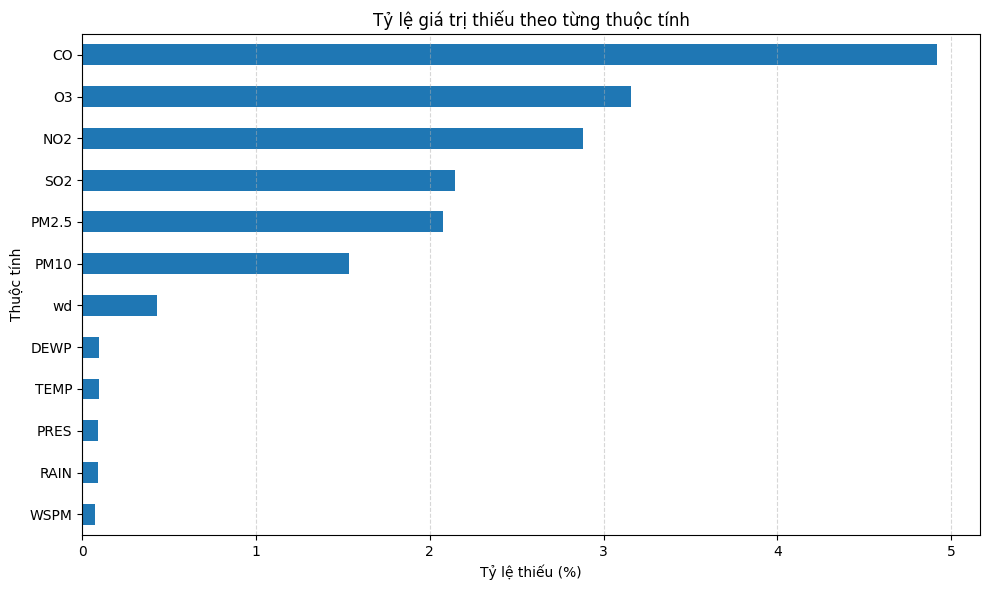

In [2]:
# Nhập thư viện trực quan hóa dữ liệu
import matplotlib.pyplot as plt

# Tính số lượng giá trị thiếu trong từng cột
missing_count = df_raw.isnull().sum()

# Tính tỷ lệ giá trị thiếu theo phần trăm tổng số dòng
missing_percent = (missing_count / len(df_raw)) * 100

# Tổng hợp số lượng và tỷ lệ thiếu thành một bảng
missing_summary = pd.DataFrame({
    "Số lượng thiếu": missing_count,
    "Tỷ lệ thiếu (%)": missing_percent
})

# Sắp xếp bảng theo tỷ lệ thiếu giảm dần
missing_summary = missing_summary.sort_values(
    by="Tỷ lệ thiếu (%)",
    ascending=False
)

# Chỉ hiển thị những cột có ít nhất một giá trị thiếu
missing_summary = missing_summary[missing_summary["Số lượng thiếu"] > 0]

# In bảng thống kê để xác định các cột cần ưu tiên xử lý
display(missing_summary.round(2))

# Vẽ biểu đồ tỷ lệ giá trị thiếu của từng cột
plt.figure(figsize=(10, 6))
missing_summary["Tỷ lệ thiếu (%)"].sort_values().plot(
    kind="barh"
)

# Bổ sung tiêu đề và nhãn trục cho biểu đồ
plt.title("Tỷ lệ giá trị thiếu theo từng thuộc tính")
plt.xlabel("Tỷ lệ thiếu (%)")
plt.ylabel("Thuộc tính")
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

### Nhận xét kết quả phân tích giá trị thiếu

Kết quả thống kê cho thấy giá trị thiếu xuất hiện ở 12 thuộc tính, nhưng tỷ lệ thiếu nhìn chung thấp, dao động từ **0,08% đến 4,92%**.

- **CO** có tỷ lệ thiếu cao nhất, với 20.701 giá trị (4,92%), tiếp theo là **O3** với 13.277 giá trị (3,16%) và **NO2** với 12.116 giá trị (2,88%).
- Các thuộc tính **SO2, PM2.5 và PM10** có tỷ lệ thiếu từ 1,53% đến 2,14%.
- Các thuộc tính khí tượng như **DEWP, TEMP, PRES, RAIN và WSPM** có tỷ lệ thiếu dưới 0,11%. Thuộc tính `wd` có 1.822 giá trị thiếu, tương ứng 0,43%.

Biểu đồ cho thấy giá trị thiếu tập trung nhiều hơn ở các biến đo nồng độ chất ô nhiễm, trong khi phần lớn biến khí tượng có dữ liệu tương đối đầy đủ.

**Kết luận:** Không nên loại bỏ toàn bộ các dòng có giá trị thiếu vì có thể làm mất những quan sát hữu ích. Bước tiếp theo sẽ phân tích và lựa chọn phương pháp xử lý phù hợp cho từng nhóm thuộc tính, đồng thời giữ nguyên dữ liệu gốc để có thể đối chiếu khi cần.

### 6. Khảo sát phân bố các thuộc tính số

**Mục tiêu:** Tìm hiểu đặc điểm phân bố của các biến số trước khi lựa chọn phương pháp điền giá trị thiếu.

**Phương pháp:** Sử dụng thống kê mô tả (`describe()`) và biểu đồ histogram để quan sát khoảng giá trị, mức độ phân tán và độ lệch của dữ liệu.

**Đầu vào:** Các thuộc tính số trong `df_raw`.

**Đầu ra:** Bảng thống kê mô tả và biểu đồ phân bố của các biến chất lượng không khí. Kết quả sẽ được sử dụng để lựa chọn phương pháp xử lý giá trị thiếu ở bước tiếp theo.

,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,412029.00,414319.00,411747.00,408652.00,400067.00,407491.00,420370.00,420375.00,420365.00,420378.00,420450.00
mean,79.79,104.60,15.83,50.64,1230.77,57.37,13.54,1010.75,2.49,0.06,1.73
std,80.82,91.77,21.65,35.13,1160.18,56.66,11.44,10.47,13.79,0.82,1.25
min,2.00,2.00,0.29,1.03,100.00,0.21,-19.90,982.40,-43.40,0.00,0.00
25%,20.00,36.00,3.00,23.00,500.00,11.00,3.10,1002.30,-8.90,0.00,0.90
50%,55.00,82.00,7.00,43.00,900.00,45.00,14.50,1010.40,3.10,0.00,1.40
75%,111.00,145.00,20.00,71.00,1500.00,82.00,23.30,1019.00,15.10,0.00,2.20
max,999.00,999.00,500.00,290.00,10000.00,1071.00,41.60,1042.80,29.10,72.50,13.20


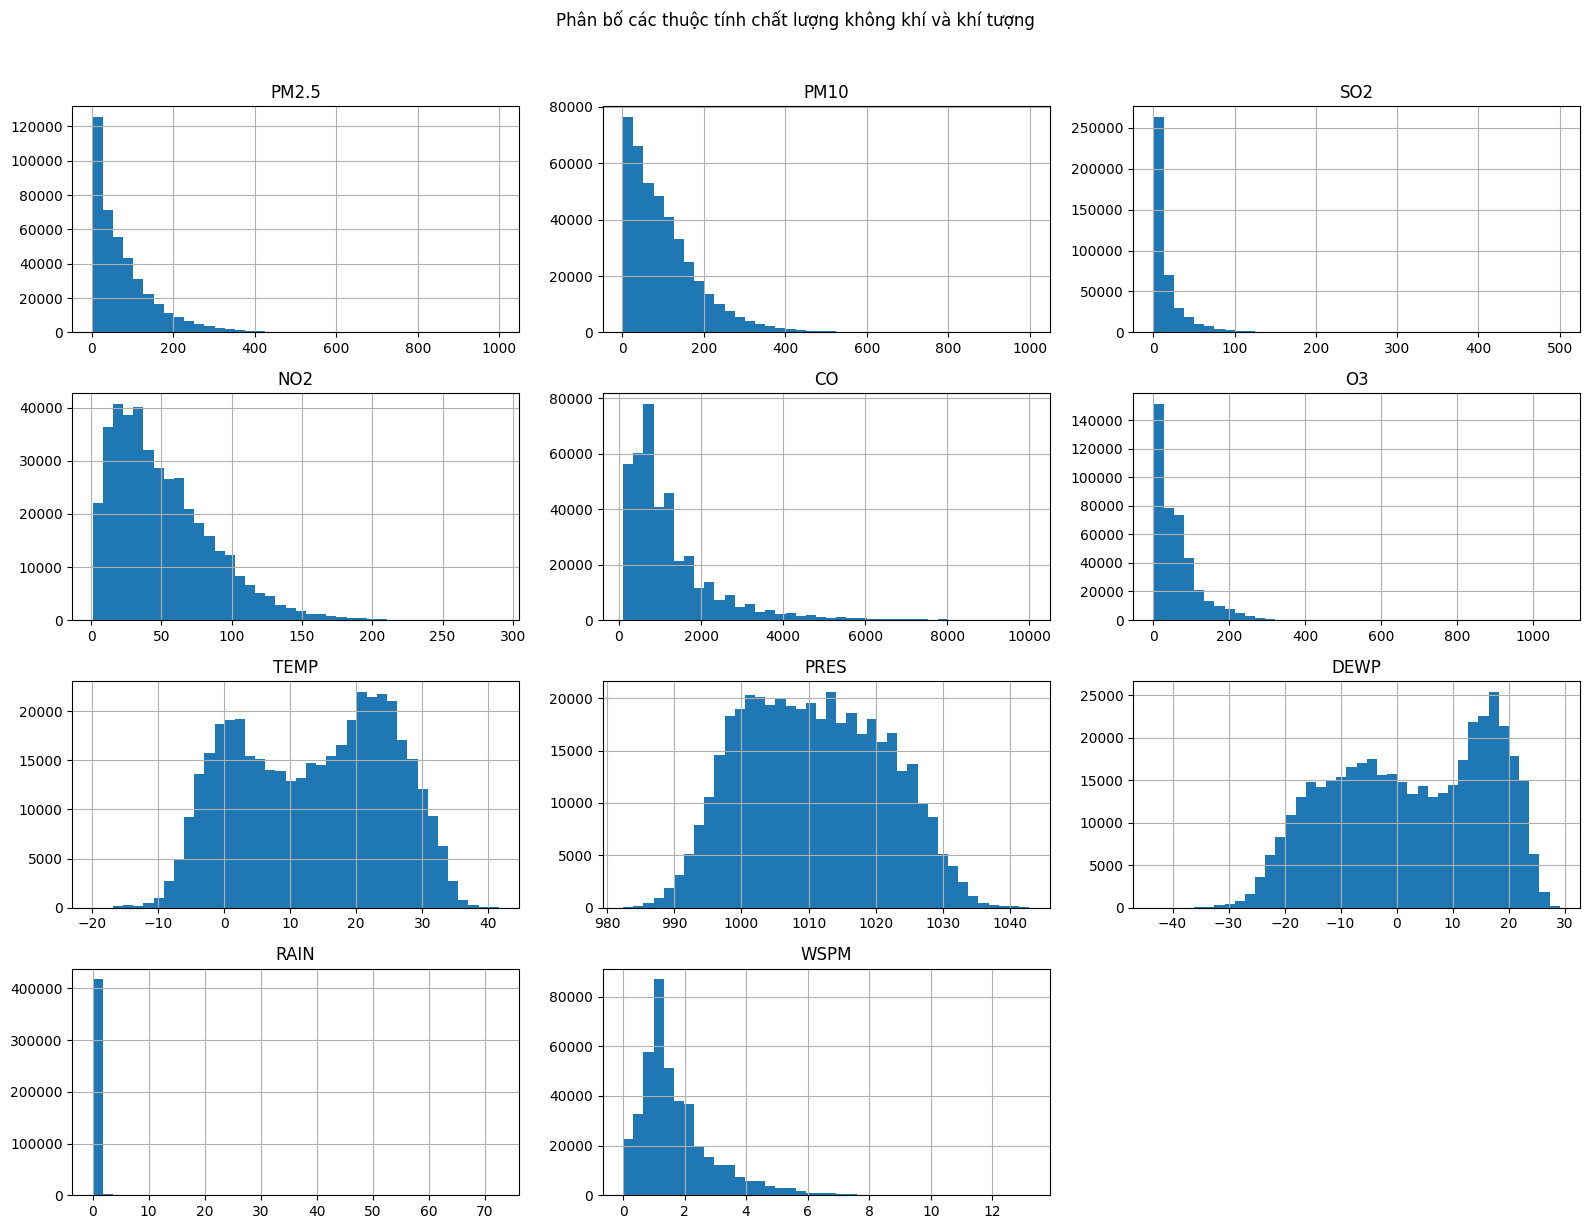

In [3]:
# Chọn các cột số đo chất lượng không khí và khí tượng để phân tích
numeric_cols = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

# Tính các thống kê mô tả như số lượng, trung bình, độ lệch chuẩn và các phân vị
display(df_raw[numeric_cols].describe().round(2))

# Tạo lưới biểu đồ histogram để quan sát phân bố của từng biến
df_raw[numeric_cols].hist(
    bins=40,            # Chia dữ liệu thành 40 khoảng để quan sát phân bố
    figsize=(16, 12)    # Đặt kích thước tổng thể của lưới biểu đồ
)

# Bổ sung tiêu đề chung và điều chỉnh khoảng cách giữa các biểu đồ
plt.suptitle("Phân bố các thuộc tính chất lượng không khí và khí tượng", y=1.02)
plt.tight_layout()

# Hiển thị toàn bộ biểu đồ
plt.show()

Bảng thống kê và biểu đồ histogram cho thấy:

- **Các biến ô nhiễm không khí:** PM2.5, PM10, SO2, CO và O3 có phân bố lệch phải rõ rệt. Giá trị trung bình thường lớn hơn trung vị, cho thấy một số quan sát có nồng độ cao kéo giá trị trung bình lên.
- **Biến NO2:** cũng có xu hướng lệch phải, nhưng mức độ phân bố trải rộng hơn ở vùng giá trị trung bình.
- **Các biến khí tượng:** TEMP và DEWP có phân bố nhiều đỉnh, PRES tập trung chủ yếu quanh vùng áp suất trung bình, WSPM lệch phải, trong khi RAIN tập trung mạnh tại giá trị 0.
- **Giá trị cực đại:** một số biến có khoảng giá trị rất rộng, chẳng hạn PM2.5 và PM10 đạt 999, CO đạt 10.000 và RAIN đạt 72,5. Các giá trị này cần được kiểm tra thêm trước khi kết luận chúng là ngoại lệ bất thường.

Do nhiều biến có phân bố lệch, sử dụng trung vị để điền giá trị thiếu có thể phù hợp hơn trung bình đối với một số thuộc tính. Tuy nhiên, cần xem xét từng biến và đặc điểm thời gian, trạm quan trắc trước khi lựa chọn phương pháp xử lý.

### 7. Xử lý giá trị thiếu

**Mục tiêu:** Hoàn thiện dữ liệu bằng cách xử lý các giá trị thiếu, hạn chế mất mát quan sát và bảo toàn sự khác biệt giữa các trạm quan trắc.

**Phương pháp:**
- Với các biến số, điền giá trị thiếu bằng trung vị của biến tương ứng tại cùng trạm quan trắc.
- Với biến hướng gió `wd`, điền bằng giá trị xuất hiện nhiều nhất tại cùng trạm.
- Giữ nguyên DataFrame `df_raw` và thực hiện xử lý trên bản sao `df_clean`.

**Đầu vào:** Dữ liệu gốc `df_raw` có các giá trị thiếu đã được thống kê.

**Đầu ra:** DataFrame `df_clean` sau xử lý và bảng kiểm tra số lượng giá trị thiếu còn lại.

Phương pháp này là bước tiền xử lý ban đầu. Sau khi kiểm tra kết quả, cần tiếp tục đánh giá tính hợp lý của dữ liệu và tránh sử dụng thông tin từ tập kiểm tra khi huấn luyện mô hình dự báo.

In [4]:
# Tạo bản sao để xử lý mà không làm thay đổi dữ liệu gốc
df_clean = df_raw.copy()

# Xác định các biến số cần điền giá trị thiếu
numeric_cols = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

# Điền giá trị thiếu của từng biến số bằng trung vị theo từng trạm
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean.groupby("station")[col].transform("median")
    )

# Định nghĩa hàm tìm giá trị xuất hiện nhiều nhất trong một nhóm
def get_mode(series):
    # Tìm các giá trị xuất hiện nhiều nhất trong cột
    modes = series.mode()

    # Trả về giá trị đầu tiên nếu có, nếu không thì giữ nguyên giá trị thiếu
    return modes.iloc[0] if not modes.empty else pd.NA

# Điền giá trị thiếu của hướng gió bằng mode theo từng trạm
df_clean["wd"] = df_clean["wd"].fillna(
    df_clean.groupby("station")["wd"].transform(get_mode)
)

# Đếm số giá trị thiếu còn lại sau xử lý
remaining_missing = df_clean.isnull().sum()

# Hiển thị số lượng giá trị thiếu còn lại của từng cột
print("Số giá trị thiếu còn lại theo cột:")
display(remaining_missing[remaining_missing > 0])

# In tổng số giá trị thiếu còn lại trong toàn bộ dữ liệu
print("Tổng giá trị thiếu còn lại:", int(remaining_missing.sum()))

# So sánh kích thước trước và sau khi xử lý
print("Kích thước dữ liệu gốc:", df_raw.shape)
print("Kích thước dữ liệu sau xử lý:", df_clean.shape)

Số giá trị thiếu còn lại theo cột:


Series([], dtype: int64)

Tổng giá trị thiếu còn lại: 0
Kích thước dữ liệu gốc: (420768, 18)
Kích thước dữ liệu sau xử lý: (420768, 18)


Sau khi áp dụng phương pháp điền giá trị thiếu theo từng trạm quan trắc, kết quả cho thấy:

- **Số lượng giá trị thiếu còn lại:** 0.
- **Kích thước dữ liệu:** giữ nguyên 420.768 dòng và 18 cột.
- **Phương pháp xử lý:** các biến số được điền bằng trung vị theo từng trạm, biến hướng gió `wd` được điền bằng giá trị xuất hiện nhiều nhất tại trạm tương ứng.

Quá trình xử lý đã hoàn thiện các giá trị thiếu mà không loại bỏ bất kỳ dòng dữ liệu nào. Việc tính toán theo từng trạm cũng giúp hạn chế sự khác biệt giữa các khu vực quan trắc bị che lấp bởi một giá trị đại diện chung.

Dữ liệu `df_clean` đã sẵn sàng cho bước kiểm tra ngoại lệ. Tuy nhiên, các giá trị được điền là giá trị ước lượng thay thế, không phải số đo thực tế.

### 8. Phát hiện ngoại lệ bằng phương pháp IQR (Interquartile Range)

#### Mục tiêu

Phát hiện các giá trị bất thường trong những thuộc tính số của bộ dữ liệu. Các giá trị ngoại lệ có thể ảnh hưởng đến thống kê mô tả và quá trình xây dựng mô hình học máy. Tuy nhiên, không phải mọi giá trị ngoại lệ đều là dữ liệu sai, một số giá trị cao có thể phản ánh những thời điểm ô nhiễm không khí nghiêm trọng.

#### Cơ sở lý thuyết

**IQR (Interquartile Range – khoảng tứ phân vị)** là thước đo độ phân tán của dữ liệu, được tính bằng hiệu giữa phân vị thứ ba và phân vị thứ nhất:

\[
IQR = Q_3 - Q_1
\]

Trong đó:

- \(Q_1\): phân vị thứ nhất (25%), nghĩa là khoảng 25% quan sát có giá trị nhỏ hơn hoặc bằng \(Q_1\).
- \(Q_3\): phân vị thứ ba (75%), nghĩa là khoảng 75% quan sát có giá trị nhỏ hơn hoặc bằng \(Q_3\).
- \(IQR\): độ rộng của khoảng chứa 50% quan sát nằm ở giữa phân bố dữ liệu.

Phương pháp IQR xác định ngoại lệ dựa trên hai ngưỡng:

\[
L = Q_1 - 1.5 \times IQR
\]

\[
U = Q_3 + 1.5 \times IQR
\]

Trong đó, \(L\) là ngưỡng dưới và \(U\) là ngưỡng trên. Một quan sát được đánh dấu là ngoại lệ nếu giá trị của nó nhỏ hơn \(L\) hoặc lớn hơn \(U\).

#### Lý do lựa chọn phương pháp

Trong bước khảo sát phân bố dữ liệu, nhiều biến ô nhiễm như PM2.5, PM10, SO2 và CO có phân bố lệch phải và khoảng giá trị rộng. IQR phù hợp để phát hiện các giá trị nằm xa vùng trung tâm vì phương pháp này dựa trên các phân vị, ít nhạy cảm với những giá trị cực lớn so với phương pháp sử dụng trung bình và độ lệch chuẩn.

Phương pháp được áp dụng riêng cho từng biến số để xác định ngưỡng phù hợp với phân bố của từng thuộc tính.

#### Quy trình thực hiện

1. Tính \(Q_1\) và \(Q_3\) cho từng biến số.
2. Tính IQR và xác định ngưỡng dưới, ngưỡng trên.
3. Đếm số lượng và tính tỷ lệ quan sát nằm ngoài hai ngưỡng.
4. Tổng hợp kết quả thành bảng và biểu đồ để so sánh giữa các thuộc tính.

#### Đầu vào và đầu ra

- **Đầu vào:** DataFrame `df_clean` đã được xử lý giá trị thiếu.
- **Kỹ thuật:** IQR với hệ số \(1.5\).
- **Đầu ra:** Bảng thống kê ngưỡng, số lượng và tỷ lệ ngoại lệ của từng biến số, kèm biểu đồ so sánh.

Ở bước này, IQR chỉ được sử dụng để **phát hiện và đánh dấu ngoại lệ**, chưa xóa hoặc thay thế bất kỳ giá trị nào. Việc xử lý tiếp theo sẽ căn cứ vào kết quả thống kê và ý nghĩa thực tế của các phép đo.

,Thuộc tính,Ngưỡng dưới,Ngưỡng trên,Số ngoại lệ,Tỷ lệ ngoại lệ (%)
2,SO2,-21.00,43.00,38275,9.10
4,CO,-1000.00,3000.00,28054,6.67
10,WSPM,-1.05,4.15,23079,5.48
0,PM2.5,-111.00,241.00,20756,4.93
5,O3,-90.00,182.00,18582,4.42
9,RAIN,0.00,0.00,16520,3.93
1,PM10,-126.00,306.00,15004,3.57
3,NO2,-47.50,140.50,7954,1.89
6,TEMP,-27.05,53.35,0,0.00
8,DEWP,-44.90,51.10,0,0.00


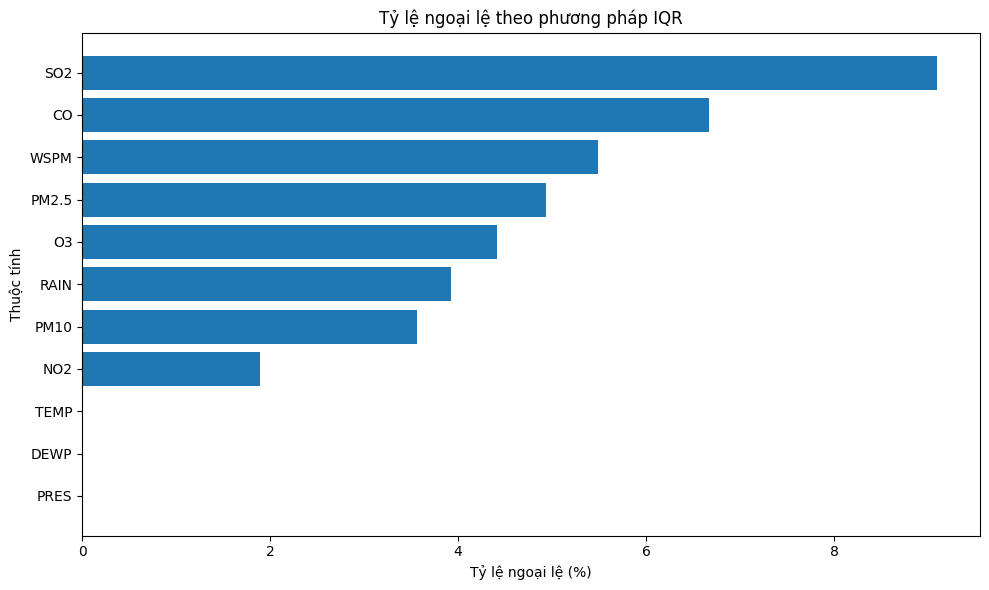

In [5]:
# Khởi tạo danh sách để lưu kết quả phát hiện ngoại lệ
outlier_results = []

# Duyệt qua từng biến số cần kiểm tra ngoại lệ
for col in numeric_cols:
    # Tính phân vị thứ nhất và thứ ba của biến hiện tại
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)

    # Tính khoảng tứ phân vị IQR
    iqr = q3 - q1

    # Xác định ngưỡng dưới và ngưỡng trên theo quy tắc 1,5 lần IQR
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Đánh dấu các quan sát nằm ngoài hai ngưỡng
    outlier_mask = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    )

    # Đếm số ngoại lệ được phát hiện
    outlier_count = int(outlier_mask.sum())

    # Tính tỷ lệ ngoại lệ trên tổng số dòng
    outlier_percent = outlier_count / len(df_clean) * 100

    # Lưu thống kê của biến hiện tại vào danh sách kết quả
    outlier_results.append({
        "Thuộc tính": col,
        "Ngưỡng dưới": lower_bound,
        "Ngưỡng trên": upper_bound,
        "Số ngoại lệ": outlier_count,
        "Tỷ lệ ngoại lệ (%)": outlier_percent
    })

# Chuyển danh sách kết quả thành DataFrame
outlier_summary = pd.DataFrame(outlier_results)

# Sắp xếp theo tỷ lệ ngoại lệ giảm dần
outlier_summary = outlier_summary.sort_values(
    by="Tỷ lệ ngoại lệ (%)",
    ascending=False
)

# Hiển thị bảng thống kê ngoại lệ
display(outlier_summary.round(2))

# Vẽ biểu đồ so sánh tỷ lệ ngoại lệ giữa các biến
plt.figure(figsize=(10, 6))
plt.barh(
    outlier_summary["Thuộc tính"],
    outlier_summary["Tỷ lệ ngoại lệ (%)"]
)

# Bổ sung tiêu đề và nhãn trục
plt.title("Tỷ lệ ngoại lệ theo phương pháp IQR")
plt.xlabel("Tỷ lệ ngoại lệ (%)")
plt.ylabel("Thuộc tính")

# Hiển thị biến có tỷ lệ ngoại lệ cao ở phía trên
plt.gca().invert_yaxis()

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Kết quả áp dụng phương pháp IQR với hệ số \(1.5\) cho thấy tỷ lệ ngoại lệ khác nhau đáng kể giữa các thuộc tính:

- **SO2** có tỷ lệ ngoại lệ cao nhất, với 38.275 quan sát (9,10%), tiếp theo là **CO** với 28.054 quan sát (6,67%).
- **WSPM** có 23.079 ngoại lệ (5,48%), **PM2.5** có 20.756 ngoại lệ (4,93%) và **O3** có 18.582 ngoại lệ (4,42%).
- **RAIN** có 16.520 ngoại lệ (3,93%), trong khi PM10 và NO2 lần lượt có tỷ lệ 3,57% và 1,89%.
- Các biến TEMP, DEWP và PRES không ghi nhận ngoại lệ theo ngưỡng IQR đã tính.

Nhìn chung, các biến ô nhiễm không khí có tỷ lệ ngoại lệ tương đối cao. Kết quả này phù hợp với đặc điểm phân bố lệch đã quan sát ở bước trước. Đối với RAIN, phần lớn giá trị bằng 0 nên \(Q_1=Q_3=0\), dẫn đến IQR bằng 0; do đó, mọi giá trị dương đều bị đánh dấu là ngoại lệ theo quy tắc này.

Các ngưỡng IQR được tính trên toàn bộ dữ liệu của mỗi biến, chưa phân biệt trạm quan trắc và thời điểm. Vì vậy, kết quả chỉ thể hiện những giá trị nằm ngoài khoảng thống kê thông thường, không khẳng định chúng là lỗi đo lường.

Chưa loại bỏ các ngoại lệ ở bước này. Cần đánh giá đặc điểm từng biến và ý nghĩa thực tế của các quan sát trước khi quyết định giữ nguyên, giới hạn giá trị hay áp dụng phương pháp xử lý khác.

### 9. Kiểm tra mất cân bằng dữ liệu (Imbalanced Data)

#### 9.1. Mục tiêu

Đánh giá sự phân bố số lượng quan sát giữa các lớp để xác định liệu dữ liệu có bị mất cân bằng hay không. Mất cân bằng xảy ra khi số lượng mẫu giữa các lớp chênh lệch đáng kể, khiến mô hình phân loại có thể thiên về lớp chiếm đa số.

#### 9.2. Phương pháp

Do dữ liệu gốc không có nhãn phân loại mức ô nhiễm, nghiên cứu sử dụng nồng độ PM2.5 để xây dựng biến mục tiêu gồm ba lớp: **ô nhiễm thấp, trung bình và cao**. Các ngưỡng được xác định theo quy ước phục vụ bài thực hành và sẽ được nêu rõ trong phần triển khai.

Sau đó, sử dụng bảng tần số và biểu đồ cột để so sánh số lượng, tỷ lệ mẫu của từng lớp. Đây là bước đánh giá phân bố lớp; chưa áp dụng kỹ thuật cân bằng dữ liệu.

#### 9.3. Đầu vào và đầu ra

- **Đầu vào:** dữ liệu `df_clean` sau khi xử lý giá trị thiếu.
- **Đầu ra:** biến mục tiêu phân loại PM2.5 và bảng, biểu đồ phân bố số lượng mẫu theo lớp.

Kết quả sẽ được dùng để quyết định có cần áp dụng kỹ thuật cân bằng dữ liệu hay không. Biến mục tiêu này phục vụ thực hành phân loại, không thay thế các ngưỡng đánh giá chất lượng không khí chính thức.

,Số lượng mẫu,Tỷ lệ (%)
PM25_Level,,
Thấp,150954,35.88
Trung bình,106831,25.39
Cao,162983,38.73


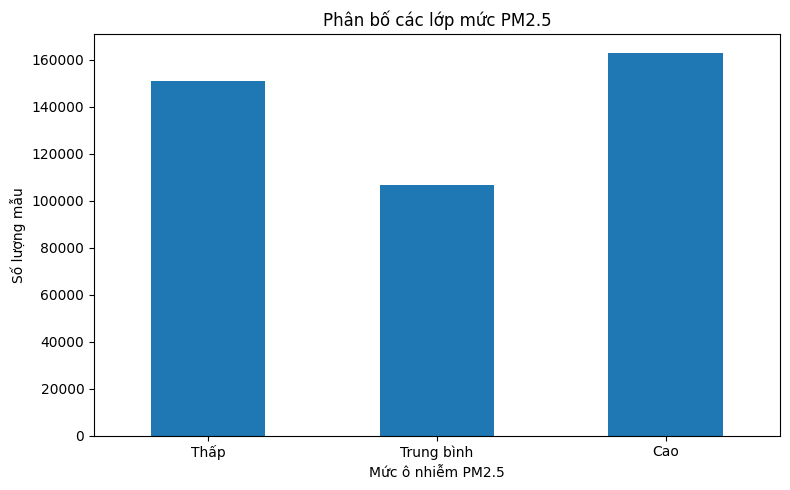

In [6]:
# Tạo bản sao để bổ sung nhãn phân loại mà không sửa df_clean
df_class = df_clean.copy()

# Định nghĩa ngưỡng PM2.5 phục vụ bài thực hành: thấp dưới 35,
# trung bình từ 35 đến dưới 75, và cao từ 75 trở lên
pm25_bins = [-float("inf"), 35, 75, float("inf")]

# Gán nhãn cho từng khoảng nồng độ PM2.5
pm25_labels = ["Thấp", "Trung bình", "Cao"]

# Chuyển biến PM2.5 liên tục thành biến phân loại có thứ tự
df_class["PM25_Level"] = pd.cut(
    df_class["PM2.5"],
    bins=pm25_bins,
    labels=pm25_labels,
    right=False
)

# Đếm số lượng quan sát trong từng lớp, kể cả lớp không có mẫu
class_counts = df_class["PM25_Level"].value_counts().reindex(
    pm25_labels,
    fill_value=0
)

# Tính tỷ lệ phần trăm của từng lớp trên tổng số quan sát
class_percent = class_counts / class_counts.sum() * 100

# Tổng hợp số lượng và tỷ lệ của từng lớp thành bảng
class_summary = pd.DataFrame({
    "Số lượng mẫu": class_counts,
    "Tỷ lệ (%)": class_percent
})

# Hiển thị bảng phân bố lớp để đánh giá mất cân bằng
display(class_summary.round(2))

# Vẽ biểu đồ số lượng quan sát của từng lớp
plt.figure(figsize=(8, 5))
class_counts.plot(kind="bar")

# Đặt tiêu đề và nhãn trục cho biểu đồ
plt.title("Phân bố các lớp mức PM2.5")
plt.xlabel("Mức ô nhiễm PM2.5")
plt.ylabel("Số lượng mẫu")
plt.xticks(rotation=0)

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Kết quả phân loại theo nồng độ PM2.5 cho thấy phân bố của ba lớp như sau:

- **Lớp Thấp:** 150.954 mẫu, chiếm 35,88%.
- **Lớp Trung bình:** 106.831 mẫu, chiếm 25,39%.
- **Lớp Cao:** 162.983 mẫu, chiếm 38,73%.

Lớp Cao chiếm tỷ lệ lớn nhất, trong khi lớp Trung bình có số lượng mẫu thấp nhất. Chênh lệch giữa lớp lớn nhất và lớp nhỏ nhất là 56.152 mẫu, tương đương khoảng 13,34 điểm phần trăm.

Mặc dù số lượng mẫu giữa các lớp không hoàn toàn đồng đều, cả ba lớp đều có tỷ lệ đáng kể. Vì vậy, dữ liệu chưa thể hiện tình trạng mất cân bằng nghiêm trọng theo cách phân chia hiện tại.

**Kết luận:** Chưa cần áp dụng ngay các kỹ thuật như SMOTE hoặc undersampling. Khi xây dựng mô hình phân loại, cần tiếp tục đánh giá Precision, Recall, F1-score và ma trận nhầm lẫn cho từng lớp để xác định liệu chênh lệch phân bố có ảnh hưởng đến hiệu quả dự đoán hay không.

Ba lớp được tạo từ các ngưỡng PM2.5 quy ước cho bài thực hành, kết quả phân bố phụ thuộc vào cách lựa chọn các ngưỡng này.

### 10. Biến đổi dữ liệu và tạo thuộc tính mới

**Mục tiêu:** Bổ sung thuộc tính thời gian và chuyển các biến phân loại sang dạng số để hỗ trợ phân tích dữ liệu cũng như xây dựng mô hình học máy.

**Phương pháp:**
- **Feature Engineering:** kết hợp các thành phần năm, tháng, ngày và giờ thành thuộc tính `datetime`.
- **One-Hot Encoding:** biểu diễn các giá trị phân loại của hướng gió và trạm quan trắc thành các cột nhị phân, tránh gán thứ tự số học giả tạo cho các nhóm.

**Đầu vào:** Dữ liệu `df_clean` sau khi xử lý giá trị thiếu.

**Đầu ra:** DataFrame `df_feature` có thêm thuộc tính thời gian và một DataFrame đã mã hóa các biến phân loại để phục vụ những bài tập tiếp theo.

Việc mã hóa được thực hiện trên một bản sao dữ liệu nhằm giữ nguyên `df_clean`. Các biến mục tiêu của bài toán dự báo và phân loại sẽ được xác định riêng theo từng bài, tránh sử dụng thông tin không phù hợp làm đầu vào mô hình.

In [7]:
# Tạo bản sao để bổ sung thuộc tính mà không thay đổi dữ liệu đã làm sạch
df_feature = df_clean.copy()

# Kết hợp năm, tháng, ngày và giờ thành một thuộc tính thời gian
df_feature["datetime"] = pd.to_datetime(
    df_feature[["year", "month", "day", "hour"]],
    errors="coerce"
)

# Hiển thị một số dòng để kiểm tra thuộc tính thời gian mới
display(df_feature[["year", "month", "day", "hour", "datetime"]].head())

# Kiểm tra kiểu dữ liệu và số giá trị thời gian không hợp lệ
print("Kiểu dữ liệu datetime:", df_feature["datetime"].dtype)
print("Số giá trị datetime không hợp lệ:", df_feature["datetime"].isnull().sum())

# Mã hóa hướng gió và trạm quan trắc bằng One-Hot Encoding
df_encoded = pd.get_dummies(
    df_feature,
    columns=["wd", "station"],
    dtype=int
)

# Hiển thị kích thước trước và sau khi mã hóa
print("Kích thước trước mã hóa:", df_feature.shape)
print("Kích thước sau mã hóa:", df_encoded.shape)

# Hiển thị một số cột sau mã hóa để kiểm tra kết quả
display(df_encoded.head())

# Kiểm tra dữ liệu thiếu còn lại trong bảng sau biến đổi
print("Tổng giá trị thiếu sau biến đổi:", int(df_encoded.isnull().sum().sum()))

,year,month,day,hour,datetime
0,2013,3,1,0,2013-03-01 00:00:00
1,2013,3,1,1,2013-03-01 01:00:00
2,2013,3,1,2,2013-03-01 02:00:00
3,2013,3,1,3,2013-03-01 03:00:00
4,2013,3,1,4,2013-03-01 04:00:00


Kiểu dữ liệu datetime: datetime64[ns]
Số giá trị datetime không hợp lệ: 0
Kích thước trước mã hóa: (420768, 19)
Kích thước sau mã hóa: (420768, 45)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,...,station_Dingling,station_Dongsi,station_Guanyuan,station_Gucheng,station_Huairou,station_Nongzhanguan,station_Shunyi,station_Tiantan,station_Wanliu,station_Wanshouxigong
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,...,0,0,0,0,0,0,0,0,0,0
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,...,0,0,0,0,0,0,0,0,0,0
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,...,0,0,0,0,0,0,0,0,0,0
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,...,0,0,0,0,0,0,0,0,0,0
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,...,0,0,0,0,0,0,0,0,0,0


Tổng giá trị thiếu sau biến đổi: 0


Kết quả cho thấy quá trình biến đổi dữ liệu đã hoàn thành thành công.

- **Tạo thuộc tính thời gian:** Các cột `year`, `month`, `day` và `hour` được kết hợp thành `datetime` có kiểu dữ liệu `datetime64[ns]`. Không có giá trị thời gian không hợp lệ.
- **One-Hot Encoding:** Phương pháp này chuyển mỗi nhóm giá trị phân loại thành các cột nhị phân, nhận giá trị 0 hoặc 1. Cách biểu diễn này giúp mô hình sử dụng dữ liệu phân loại mà không tạo ra thứ tự số học giả tạo giữa các nhóm.
- **Kích thước dữ liệu:** Sau khi mã hóa `wd` và `station`, số cột tăng từ 19 lên 45, trong khi số dòng vẫn giữ nguyên ở mức 420.768.
- **Giá trị thiếu:** Không còn giá trị thiếu trong dữ liệu sau biến đổi.

**Kết luận:** Dữ liệu đã được bổ sung thuộc tính thời gian và mã hóa các biến phân loại, tạo điều kiện thuận lợi cho việc phân tích chuỗi thời gian và xây dựng mô hình học máy. Các biến thời gian và biến phân loại sẽ được lựa chọn phù hợp với từng bài toán cụ thể.

### 11. Xử lý ngoại lệ bằng phương pháp Winsorization

**Mục tiêu:** Hạn chế ảnh hưởng của các giá trị cực đoan đến quá trình phân tích dữ liệu.

**Phương pháp:** Winsorization thay thế các giá trị nằm ngoài ngưỡng cho phép bằng chính ngưỡng dưới hoặc ngưỡng trên, thay vì xóa các dòng dữ liệu. Trong bài này, ta sử dụng ngưỡng IQR đã tính ở bước trước để giới hạn giá trị của các biến ô nhiễm có ngoại lệ. Phương pháp này giữ nguyên số lượng quan sát nhưng có thể làm giảm thông tin về những đợt ô nhiễm nghiêm trọng.

Không áp dụng trực tiếp cho `RAIN` vì IQR bằng 0 khiến mọi giá trị mưa dương bị đánh dấu là ngoại lệ. Các biến khí tượng không có ngoại lệ theo kết quả IQR cũng được giữ nguyên.

**Đầu vào:** Dữ liệu `df_clean` và bảng ngưỡng IQR `outlier_summary`.

**Đầu ra:** Dữ liệu `df_outlier_treated` sau khi giới hạn ngoại lệ và bảng so sánh trước, sau xử lý.

In [8]:
# Tạo bản sao để giữ nguyên dữ liệu đã làm sạch ban đầu
df_outlier_treated = df_clean.copy()

# Chọn các biến có ngoại lệ theo kết quả IQR, không bao gồm RAIN
cols_to_cap = ["SO2", "CO", "WSPM", "PM2.5", "O3", "PM10", "NO2"]

# Lưu số lượng ngoại lệ ban đầu của từng biến
comparison = []

# Giới hạn giá trị theo ngưỡng IQR đã tính ở bước trước
for col in cols_to_cap:
    # Lấy ngưỡng dưới và ngưỡng trên của biến hiện tại
    row = outlier_summary[outlier_summary["Thuộc tính"] == col].iloc[0]
    lower = row["Ngưỡng dưới"]
    upper = row["Ngưỡng trên"]

    # Đếm số giá trị nằm ngoài ngưỡng trước xử lý
    before_count = int(
        ((df_outlier_treated[col] < lower) |
         (df_outlier_treated[col] > upper)).sum()
    )

    # Thay giá trị thấp hơn ngưỡng bằng ngưỡng dưới
    # Thay giá trị cao hơn ngưỡng bằng ngưỡng trên
    df_outlier_treated[col] = df_outlier_treated[col].clip(
        lower=lower,
        upper=upper
    )

    # Đếm số giá trị còn nằm ngoài ngưỡng sau xử lý
    after_count = int(
        ((df_outlier_treated[col] < lower) |
         (df_outlier_treated[col] > upper)).sum()
    )

    # Lưu kết quả so sánh trước và sau xử lý
    comparison.append({
        "Thuộc tính": col,
        "Ngoại lệ trước xử lý": before_count,
        "Ngoại lệ sau xử lý": after_count
    })

# Hiển thị bảng so sánh kết quả
display(pd.DataFrame(comparison))

# Kiểm tra kích thước dữ liệu có được giữ nguyên hay không
print("Kích thước trước xử lý:", df_clean.shape)
print("Kích thước sau xử lý:", df_outlier_treated.shape)

,Thuộc tính,Ngoại lệ trước xử lý,Ngoại lệ sau xử lý
0,SO2,38275,0
1,CO,28054,0
2,WSPM,23079,0
3,PM2.5,20756,0
4,O3,18582,0
5,PM10,15004,0
6,NO2,7954,0


Kích thước trước xử lý: (420768, 18)
Kích thước sau xử lý: (420768, 18)


Kết quả cho thấy phương pháp Winsorization đã giới hạn các giá trị nằm ngoài ngưỡng IQR đối với cả 7 thuộc tính được lựa chọn.

- SO2 có 38.275 ngoại lệ trước xử lý.
- CO có 28.054 ngoại lệ.
- WSPM có 23.079 ngoại lệ.
- PM2.5 có 20.756 ngoại lệ.
- O3, PM10 và NO2 lần lượt có 18.582, 15.004 và 7.954 ngoại lệ.

Sau xử lý, cả 7 thuộc tính đều không còn giá trị nằm ngoài ngưỡng IQR đã xác định. Kích thước dữ liệu vẫn giữ nguyên **420.768 dòng và 18 cột**, cho thấy phương pháp không loại bỏ quan sát mà thay thế các giá trị vượt ngưỡng bằng ngưỡng tương ứng.

**Kết luận:** Winsorization giúp hạn chế ảnh hưởng của các giá trị cực đoan mà không làm giảm số lượng mẫu. Tuy nhiên, phương pháp cũng làm thay đổi các giá trị ô nhiễm cao thực tế. Vì vậy, `df_outlier_treated` nên được sử dụng khi cần giảm ảnh hưởng của ngoại lệ, còn `df_clean` được giữ lại để đối chiếu và phục vụ những bài toán cần bảo toàn giá trị quan trắc gốc.

### 12. Cân bằng dữ liệu bằng Random Oversampling

**Mục tiêu:** Tạo tập dữ liệu có số lượng mẫu giữa các lớp bằng nhau để khảo sát cách xử lý mất cân bằng trong bài toán phân loại.

**Phương pháp:** Random Oversampling là kỹ thuật tăng số lượng mẫu của lớp thiểu số bằng cách lấy mẫu ngẫu nhiên có hoàn lại từ các quan sát hiện có. Các mẫu được chọn có thể xuất hiện nhiều lần, do đó kỹ thuật này không tạo ra thông tin mới và có thể làm tăng nguy cơ quá khớp.

Trong bước thực hành này, ta cân bằng ba lớp PM2.5 đã tạo ở bước 9. Việc cân bằng được thực hiện trên tập dữ liệu dành riêng cho khảo sát, không dùng trực tiếp tập đã cân bằng để đánh giá mô hình trên dữ liệu kiểm tra.

**Đầu vào:** Dữ liệu `df_class` chứa nhãn `PM25_Level`.

**Đầu ra:** Bảng so sánh số lượng mẫu trước và sau cân bằng, cùng biểu đồ phân bố lớp sau xử lý.

,Trước cân bằng,Sau cân bằng
PM25_Level,,
Thấp,150954,162983
Trung bình,106831,162983
Cao,162983,162983


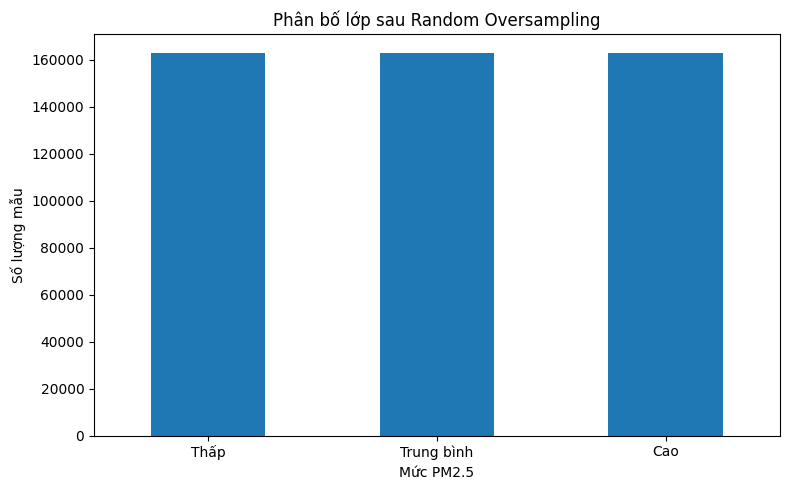

In [9]:
# Nhập công cụ lấy mẫu ngẫu nhiên từ thư viện scikit-learn
from sklearn.utils import resample

# Tạo dữ liệu đầu vào từ các thuộc tính và nhãn phân loại
# Chỉ sử dụng PM2.5 và nhãn để minh họa kỹ thuật cân bằng lớp
balance_data = df_class[["PM2.5", "PM25_Level"]].copy()

# Tách dữ liệu thành từng nhóm theo nhãn phân loại
class_groups = {
    label: balance_data[balance_data["PM25_Level"] == label]
    for label in pm25_labels
}

# Xác định số lượng mẫu lớn nhất trong các lớp hiện có
target_size = max(len(group) for group in class_groups.values())

# Khởi tạo danh sách lưu các nhóm sau khi cân bằng
balanced_groups = []

# Lấy mẫu có hoàn lại để tăng các lớp lên cùng số lượng
for label, group in class_groups.items():
    balanced_group = resample(
        group,
        replace=True,
        n_samples=target_size,
        random_state=42
    )

    # Lưu nhóm đã cân bằng
    balanced_groups.append(balanced_group)

# Ghép các nhóm thành tập dữ liệu cân bằng
df_balanced = pd.concat(balanced_groups, ignore_index=True)

# Đếm số lượng mẫu của từng lớp trước và sau cân bằng
before_counts = balance_data["PM25_Level"].value_counts().reindex(
    pm25_labels, fill_value=0
)
after_counts = df_balanced["PM25_Level"].value_counts().reindex(
    pm25_labels, fill_value=0
)

# Tổng hợp kết quả so sánh thành bảng
balance_summary = pd.DataFrame({
    "Trước cân bằng": before_counts,
    "Sau cân bằng": after_counts
})

# Hiển thị bảng so sánh
display(balance_summary)

# Vẽ biểu đồ số lượng mẫu sau cân bằng
plt.figure(figsize=(8, 5))
after_counts.plot(kind="bar")

# Bổ sung tiêu đề và nhãn trục
plt.title("Phân bố lớp sau Random Oversampling")
plt.xlabel("Mức PM2.5")
plt.ylabel("Số lượng mẫu")
plt.xticks(rotation=0)

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Kết quả cho thấy số lượng mẫu của ba lớp đã được đưa về cùng mức **162.983 mẫu mỗi lớp**.

- Lớp Thấp tăng từ 150.954 lên 162.983 mẫu.
- Lớp Trung bình tăng từ 106.831 lên 162.983 mẫu.
- Lớp Cao giữ nguyên ở mức 162.983 mẫu vì đây là lớp có số lượng mẫu lớn nhất ban đầu.

Random Oversampling hoạt động bằng cách lấy mẫu ngẫu nhiên có hoàn lại từ các lớp ít mẫu hơn. Vì vậy, một số quan sát có thể được lặp lại nhiều lần. Phương pháp này giúp cân bằng số lượng mẫu giữa các lớp nhưng không bổ sung thông tin mới cho dữ liệu.

**Kết luận:** Tập dữ liệu sau cân bằng đã có phân bố lớp đồng đều. Tuy nhiên, khi xây dựng mô hình, cần thực hiện cân bằng trên tập huấn luyện, không cân bằng tập kiểm tra, để tránh đánh giá mô hình thiếu khách quan.

# ASSIGNMENT 3: FEATURE SELECTION AND DIMENSIONALITY REDUCTION

## 1. Mục tiêu

Bài tập áp dụng các kỹ thuật lựa chọn đặc trưng và giảm chiều dữ liệu trên bộ dữ liệu Beijing Multi-Site Air Quality. Mục tiêu là xác định những thuộc tính hữu ích cho việc phân loại mức PM2.5, đồng thời khảo sát khả năng giảm số chiều dữ liệu mà vẫn giữ lại thông tin quan trọng.

## 2. Nội dung thực hiện

Bài tập gồm hai nhóm kỹ thuật chính.

**Nhóm 1. Feature Selection**

Feature Selection là quá trình chọn ra một tập con các thuộc tính ban đầu dựa trên mức độ hữu ích của chúng đối với bài toán. Phương pháp này giữ nguyên ý nghĩa và tên gọi của các thuộc tính được chọn.

Các kỹ thuật được áp dụng gồm:

- RFECV
- Variance Threshold
- SelectKBest với Mutual Information
- Feature Importance của Random Forest

**Nhóm 2. Feature Extraction và Dimensionality Reduction**

Feature Extraction tạo ra các đặc trưng mới từ những thuộc tính ban đầu, qua đó biểu diễn dữ liệu bằng số chiều thấp hơn.

Các kỹ thuật được áp dụng gồm:

- PCA
- SVD
- LDA

## 3. Dữ liệu và bài toán phân tích

Sử dụng bộ dữ liệu Beijing Multi-Site Air Quality đã được xử lý giá trị thiếu ở Assignment 2. Biến mục tiêu là `PM25_Level`, gồm ba lớp Thấp, Trung bình và Cao, được xây dựng từ nồng độ PM2.5.

Các biến đầu vào gồm PM10, SO2, NO2, CO, O3 và những yếu tố khí tượng như nhiệt độ, áp suất, điểm sương, lượng mưa và tốc độ gió. Biến PM2.5 không được sử dụng làm đầu vào vì nó được dùng để xác định trực tiếp biến mục tiêu, nếu đưa vào sẽ gây rò rỉ thông tin.

Do bộ dữ liệu có số lượng quan sát lớn, bài thực hành sử dụng một mẫu phân tầng để giảm thời gian tính toán nhưng vẫn giữ tỷ lệ các lớp gần với dữ liệu ban đầu.

## 4. Đánh giá kết quả

Các phương pháp lựa chọn đặc trưng sẽ được so sánh dựa trên số lượng và danh sách thuộc tính được chọn. Các phương pháp giảm chiều sẽ được đánh giá qua số chiều đầu ra và tỷ lệ phương sai được giữ lại khi chỉ số này phù hợp.

Kết quả giúp làm rõ sự khác biệt giữa việc chọn thuộc tính gốc và tạo ra các đặc trưng mới, đồng thời cung cấp cơ sở lựa chọn dữ liệu đầu vào cho các mô hình học máy tiếp theo.

### 5. Chuẩn bị dữ liệu cho Feature Selection và Dimensionality Reduction

**Mục tiêu:** Xây dựng tập dữ liệu đầu vào thống nhất để áp dụng các phương pháp lựa chọn đặc trưng và giảm chiều.

**Phương pháp:** Lấy mẫu phân tầng theo `PM25_Level`, chia dữ liệu thành tập huấn luyện và tập kiểm tra theo tỷ lệ 80:20. Sau đó, chuẩn hóa các thuộc tính dựa trên tập huấn luyện.

**Đầu vào:** Dữ liệu `df_class` đã được tạo ở Assignment 2.

**Đầu ra:** Tập đặc trưng `X_train`, `X_test`, nhãn `y_train`, `y_test` và dữ liệu đã chuẩn hóa để sử dụng ở các bước tiếp theo.

Biến PM2.5 được loại khỏi tập đầu vào để tránh rò rỉ thông tin từ biến mục tiêu.

In [10]:
# Nhập công cụ chia dữ liệu và chuẩn hóa đặc trưng
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Khai báo các thuộc tính đầu vào, không sử dụng trực tiếp PM2.5
feature_cols = [
    "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

# Tạo DataFrame chứa các thuộc tính đầu vào và nhãn phân loại
data_for_model = df_class[feature_cols + ["PM25_Level"]].copy()

# Lấy mẫu tối đa 30.000 dòng theo phương pháp phân tầng
# Cách này giữ tỷ lệ các lớp gần với dữ liệu ban đầu
if len(data_for_model) > 30000:
    data_sample, _ = train_test_split(
        data_for_model,
        train_size=30000,
        stratify=data_for_model["PM25_Level"],
        random_state=42
    )
else:
    # Sử dụng toàn bộ dữ liệu nếu số dòng không vượt quá 30.000
    data_sample = data_for_model.copy()

# Tách các thuộc tính đầu vào X và nhãn mục tiêu y
X = data_sample[feature_cols]
y = data_sample["PM25_Level"]

# Chia dữ liệu thành tập huấn luyện 80% và tập kiểm tra 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Khởi tạo bộ chuẩn hóa dữ liệu
scaler = StandardScaler()

# Tính tham số chuẩn hóa trên tập huấn luyện và biến đổi tập huấn luyện
X_train_scaled = scaler.fit_transform(X_train)

# Dùng cùng tham số đã học để chuẩn hóa tập kiểm tra
X_test_scaled = scaler.transform(X_test)

# In kích thước các tập dữ liệu sau khi chia
print("Kích thước mẫu:", data_sample.shape)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Hiển thị tỷ lệ các lớp trong tập huấn luyện
print("\nTỷ lệ lớp trong tập huấn luyện:")
display((y_train.value_counts(normalize=True) * 100).round(2))

# Hiển thị tỷ lệ các lớp trong tập kiểm tra
print("\nTỷ lệ lớp trong tập kiểm tra:")
display((y_test.value_counts(normalize=True) * 100).round(2))

# Kiểm tra kích thước dữ liệu sau chuẩn hóa
print("\nKích thước X_train_scaled:", X_train_scaled.shape)
print("Kích thước X_test_scaled:", X_test_scaled.shape)

Kích thước mẫu: (30000, 11)
X_train: (24000, 10)
X_test: (6000, 10)
y_train: (24000,)
y_test: (6000,)

Tỷ lệ lớp trong tập huấn luyện:


PM25_Level
Cao           38.73
Thấp          35.88
Trung bình    25.39
Name: proportion, dtype: float64


Tỷ lệ lớp trong tập kiểm tra:


PM25_Level
Cao           38.73
Thấp          35.88
Trung bình    25.38
Name: proportion, dtype: float64


Kích thước X_train_scaled: (24000, 10)
Kích thước X_test_scaled: (6000, 10)


Sau khi lấy mẫu phân tầng và chia dữ liệu, tập dữ liệu có 30.000 quan sát với 10 thuộc tính đầu vào và một biến mục tiêu `PM25_Level`.

- **Chia dữ liệu:** tập huấn luyện có 24.000 mẫu, chiếm 80%, và tập kiểm tra có 6.000 mẫu, chiếm 20%.
- **Phân bố lớp:** hai tập giữ được tỷ lệ lớp gần như giống nhau. Lớp Cao chiếm 38,73%, lớp Thấp chiếm 35,88% và lớp Trung bình chiếm khoảng 25,38–25,39%.
- **Chuẩn hóa:** dữ liệu sau chuẩn hóa vẫn có 10 thuộc tính. Bộ chuẩn hóa chỉ được học từ tập huấn luyện rồi áp dụng cho tập kiểm tra, giúp tránh rò rỉ thông tin từ tập kiểm tra.

Dữ liệu đã sẵn sàng cho các phương pháp lựa chọn đặc trưng và giảm chiều. Việc sử dụng mẫu 30.000 quan sát giúp giảm thời gian tính toán trong khi vẫn duy trì tương đối tốt phân bố các lớp.

### 6. Lựa chọn đặc trưng bằng RFECV

**Mục tiêu:** Tìm tập con thuộc tính phù hợp nhất cho việc phân loại mức PM2.5.

**Phương pháp:** RFECV huấn luyện mô hình, xếp hạng độ quan trọng của các thuộc tính và loại bỏ dần thuộc tính ít quan trọng. Sau mỗi lần loại bỏ, phương pháp đánh giá hiệu quả bằng kiểm định chéo để lựa chọn số lượng thuộc tính tối ưu.

**Đầu vào:** `X_train` và `y_train` gồm 24.000 quan sát.

**Đầu ra:** Danh sách thuộc tính được chọn, số lượng thuộc tính tối ưu và điểm đánh giá qua kiểm định chéo.

Random Forest được sử dụng làm mô hình cơ sở để xác định độ quan trọng của thuộc tính. Tập kiểm tra được giữ riêng và không tham gia quá trình lựa chọn.

In [11]:
# Nhập các công cụ cần thiết cho phương pháp RFECV
from sklearn.feature_selection import RFECV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

# Khởi tạo Random Forest làm mô hình cơ sở
rf_model = RandomForestClassifier(
    n_estimators=100,       # Sử dụng 100 cây quyết định
    random_state=42,        # Cố định kết quả để dễ tái lập
    n_jobs=-1               # Tận dụng các lõi CPU có sẵn
)

# Tạo chiến lược kiểm định chéo phân tầng gồm 3 phần
cv_strategy = StratifiedKFold(
    n_splits=3,             # Chia tập huấn luyện thành 3 phần
    shuffle=True,            # Xáo trộn dữ liệu trước khi chia
    random_state=42         # Cố định cách chia dữ liệu
)

# Khởi tạo RFECV để tự lựa chọn số lượng thuộc tính phù hợp
rfecv = RFECV(
    estimator=rf_model,      # Mô hình dùng để đánh giá độ quan trọng
    step=1,                  # Mỗi lần loại bỏ một thuộc tính
    cv=cv_strategy,          # Sử dụng kiểm định chéo phân tầng
    scoring="f1_macro",      # Đánh giá F1 trung bình giữa các lớp
    min_features_to_select=2, # Giữ tối thiểu 2 thuộc tính
    n_jobs=-1                # Tận dụng các lõi CPU có sẵn
)

# Huấn luyện RFECV trên tập huấn luyện
rfecv.fit(X_train, y_train)

# Lấy danh sách tên thuộc tính được chọn
selected_features_rfecv = X_train.columns[rfecv.support_].tolist()

# In số lượng và danh sách thuộc tính được chọn
print("Số thuộc tính ban đầu:", X_train.shape[1])
print("Số thuộc tính được RFECV chọn:", rfecv.n_features_)
print("Danh sách thuộc tính được chọn:")
print(selected_features_rfecv)

# Hiển thị điểm F1-macro tốt nhất theo kết quả RFECV
print("\nĐiểm F1-macro trung bình tốt nhất:", round(rfecv.cv_results_["mean_test_score"].max(), 4))

# Tạo bảng thể hiện thuộc tính được giữ lại hay bị loại bỏ
rfecv_summary = pd.DataFrame({
    "Thuộc tính": X_train.columns,
    "Thứ hạng": rfecv.ranking_,
    "Được chọn": rfecv.support_
})

# Sắp xếp thuộc tính được chọn lên đầu bảng
rfecv_summary = rfecv_summary.sort_values(
    by=["Được chọn", "Thứ hạng"],
    ascending=[False, True]
)

# Hiển thị bảng kết quả lựa chọn đặc trưng
display(rfecv_summary)

Số thuộc tính ban đầu: 10
Số thuộc tính được RFECV chọn: 8
Danh sách thuộc tính được chọn:
['PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP']

Điểm F1-macro trung bình tốt nhất: 0.838


,Thuộc tính,Thứ hạng,Được chọn
0,PM10,1,True
1,SO2,1,True
2,NO2,1,True
3,CO,1,True
4,O3,1,True
5,TEMP,1,True
6,PRES,1,True
7,DEWP,1,True
9,WSPM,2,False
8,RAIN,3,False


Kết quả cho thấy RFECV đã giảm số lượng thuộc tính đầu vào từ 10 xuống còn 8 thuộc tính.

Các thuộc tính được giữ lại gồm PM10, SO2, NO2, CO, O3, TEMP, PRES và DEWP. Hai thuộc tính bị loại là WSPM và RAIN, lần lượt có thứ hạng 2 và 3. Trong RFECV, thứ hạng 1 biểu thị thuộc tính được chọn, còn thứ hạng lớn hơn 1 biểu thị thuộc tính bị loại trong quá trình lựa chọn.

Điểm F1-macro trung bình tốt nhất đạt 0,838. F1-macro là trung bình cộng F1-score của các lớp, giúp đánh giá hiệu quả phân loại mà không để lớp có nhiều mẫu chi phối hoàn toàn kết quả.

**Kết luận:** RFECV cho thấy có thể loại bỏ hai thuộc tính WSPM và RAIN trong cấu hình mô hình và quy trình kiểm định hiện tại. Tuy nhiên, kết quả này chưa chứng minh hai thuộc tính không có giá trị trong mọi mô hình hoặc mọi điều kiện dữ liệu.

### 7. Lựa chọn đặc trưng bằng Variance Threshold

**Mục tiêu:** Loại bỏ các thuộc tính không có sự biến thiên trong tập huấn luyện.

**Phương pháp:** Variance Threshold tính phương sai của từng thuộc tính và loại bỏ những thuộc tính có phương sai không vượt quá ngưỡng đã đặt. Trong bài này, ngưỡng bằng 0 nên chỉ các thuộc tính có phương sai bằng 0 mới bị loại.

**Đầu vào:** `X_train` gồm 24.000 quan sát và 10 thuộc tính.

**Đầu ra:** Danh sách thuộc tính được giữ lại và số lượng thuộc tính sau lọc.

Phương pháp này không sử dụng nhãn mục tiêu. Vì vậy, nó chỉ phát hiện thuộc tính không biến thiên, không trực tiếp đánh giá khả năng dự đoán của từng thuộc tính.

In [12]:
# Nhập công cụ lọc đặc trưng theo phương sai
from sklearn.feature_selection import VarianceThreshold

# Khởi tạo bộ lọc với ngưỡng bằng 0
# Thuộc tính chỉ bị loại nếu phương sai bằng 0
variance_selector = VarianceThreshold(threshold=0)

# Học phương sai từ tập huấn luyện và thực hiện lọc
X_train_var = variance_selector.fit_transform(X_train)

# Lấy tên các thuộc tính được giữ lại
selected_features_var = X_train.columns[
    variance_selector.get_support()
].tolist()

# Tạo bảng thể hiện kết quả giữ hoặc loại từng thuộc tính
variance_summary = pd.DataFrame({
    "Thuộc tính": X_train.columns,
    "Phương sai": X_train.var().values,
    "Được chọn": variance_selector.get_support()
})

# In số lượng thuộc tính trước và sau khi lọc
print("Số thuộc tính ban đầu:", X_train.shape[1])
print("Số thuộc tính sau Variance Threshold:", X_train_var.shape[1])

# Hiển thị danh sách thuộc tính được giữ lại
print("\nCác thuộc tính được giữ lại:")
print(selected_features_var)

# Hiển thị bảng phương sai và trạng thái lựa chọn
display(variance_summary.sort_values("Phương sai"))

Số thuộc tính ban đầu: 10
Số thuộc tính sau Variance Threshold: 10

Các thuộc tính được giữ lại:
['PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']


,Thuộc tính,Phương sai,Được chọn
8,RAIN,9.728359e-01,True
9,WSPM,1.558425e+00,True
6,PRES,1.093537e+02,True
5,TEMP,1.288716e+02,True
7,DEWP,1.893677e+02,True
1,SO2,4.442758e+02,True
2,NO2,1.196122e+03,True
4,O3,2.948406e+03,True
0,PM10,8.331115e+03,True
3,CO,1.285066e+06,True


Kết quả cho thấy cả 10 thuộc tính đều được giữ lại sau khi áp dụng Variance Threshold với ngưỡng phương sai bằng 0.

Thuộc tính CO có phương sai lớn nhất, khoảng \(1.285.066\), trong khi RAIN có phương sai nhỏ nhất, khoảng \(0,973\). Tuy nhiên, phương sai nhỏ không đồng nghĩa với việc thuộc tính không có ích cho mô hình.

Do tất cả thuộc tính đều có phương sai lớn hơn 0, không có thuộc tính nào bị loại bỏ.

**Kết luận:** Variance Threshold với ngưỡng bằng 0 chưa giúp giảm số chiều của bộ dữ liệu này. Kết quả cho thấy cả 10 thuộc tính đều có sự biến thiên trong tập huấn luyện. Phương pháp này chỉ phát hiện thuộc tính không biến thiên, không đánh giá trực tiếp mức độ liên quan của thuộc tính với biến mục tiêu.

### 8. Lựa chọn đặc trưng bằng SelectKBest và Mutual Information

**Mục tiêu:** Xác định năm thuộc tính có mức độ phụ thuộc cao nhất với nhãn phân loại PM2.5.

**Phương pháp:** Mutual Information đánh giá lượng thông tin mà một thuộc tính cung cấp về biến mục tiêu. SelectKBest xếp hạng các thuộc tính theo điểm số này và giữ lại số lượng thuộc tính được chỉ định.

**Đầu vào:** `X_train` và `y_train` của tập huấn luyện.

**Đầu ra:** Danh sách năm thuộc tính được chọn cùng điểm Mutual Information tương ứng.

Phương pháp sử dụng nhãn mục tiêu để đánh giá từng thuộc tính riêng lẻ. Vì vậy, nó không trực tiếp đánh giá sự kết hợp giữa nhiều thuộc tính như RFECV.

In [13]:
# Nhập công cụ lựa chọn đặc trưng và hàm tính Mutual Information
from sklearn.feature_selection import SelectKBest, mutual_info_classif

# Khởi tạo SelectKBest để chọn năm thuộc tính có điểm cao nhất
mi_selector = SelectKBest(
    score_func=mutual_info_classif,  # Đánh giá thông tin giữa thuộc tính và nhãn
    k=5                              # Giữ lại năm thuộc tính tốt nhất
)

# Tính điểm và lựa chọn thuộc tính chỉ từ tập huấn luyện
X_train_mi = mi_selector.fit_transform(X_train, y_train)

# Lấy tên các thuộc tính được chọn
selected_features_mi = X_train.columns[
    mi_selector.get_support()
].tolist()

# Tạo bảng điểm Mutual Information của từng thuộc tính
mi_summary = pd.DataFrame({
    "Thuộc tính": X_train.columns,
    "Điểm Mutual Information": mi_selector.scores_,
    "Được chọn": mi_selector.get_support()
})

# Sắp xếp bảng theo điểm Mutual Information giảm dần
mi_summary = mi_summary.sort_values(
    by="Điểm Mutual Information",
    ascending=False
)

# In số lượng thuộc tính trước và sau lựa chọn
print("Số thuộc tính ban đầu:", X_train.shape[1])
print("Số thuộc tính được chọn:", len(selected_features_mi))

# Hiển thị danh sách thuộc tính được chọn
print("\nCác thuộc tính được chọn:")
print(selected_features_mi)

# Hiển thị điểm số của toàn bộ thuộc tính
display(mi_summary.round(4))

Số thuộc tính ban đầu: 10
Số thuộc tính được chọn: 5

Các thuộc tính được chọn:
['PM10', 'SO2', 'NO2', 'CO', 'O3']


,Thuộc tính,Điểm Mutual Information,Được chọn
0,PM10,0.5485,True
3,CO,0.4174,True
2,NO2,0.2193,True
1,SO2,0.1361,True
4,O3,0.1033,True
7,DEWP,0.0901,False
9,WSPM,0.0633,False
6,PRES,0.0296,False
5,TEMP,0.0188,False
8,RAIN,0.0058,False


Kết quả cho thấy năm thuộc tính được lựa chọn gồm PM10, CO, NO2, SO2 và O3.

- **PM10** có điểm Mutual Information cao nhất, đạt 0,5482, cho thấy thuộc tính này cung cấp nhiều thông tin nhất về nhãn phân loại PM2.5 trong kết quả hiện tại.
- **CO** đứng thứ hai với 0,4156, tiếp theo là **NO2** với 0,2147.
- **SO2** và **O3** có điểm lần lượt là 0,1370 và 0,1033.
- Các thuộc tính khí tượng như RAIN, TEMP và PRES có điểm thấp hơn trong lần đánh giá này.

Mutual Information đo mức độ phụ thuộc giữa từng thuộc tính và nhãn mục tiêu. Điểm cao hơn thể hiện mối liên hệ thông tin mạnh hơn theo phép ước lượng được sử dụng, nhưng không khẳng định quan hệ nhân quả.

**Kết luận:** SelectKBest đã giảm số thuộc tính từ 10 xuống còn 5, tập trung vào các biến ô nhiễm không khí. Kết quả khác RFECV vì SelectKBest đánh giá từng thuộc tính riêng lẻ, trong khi RFECV lựa chọn dựa trên hiệu quả của mô hình và kiểm định chéo.

### 9. Lựa chọn đặc trưng bằng Random Forest Feature Importance

**Mục tiêu:** Xếp hạng các thuộc tính theo mức độ quan trọng đối với mô hình phân loại mức PM2.5.

**Phương pháp:** Huấn luyện Random Forest trên tập huấn luyện. Mô hình tổng hợp mức giảm độ hỗn tạp từ các lần phân chia dữ liệu để tính điểm quan trọng cho từng thuộc tính. Sau đó, lựa chọn năm thuộc tính có điểm cao nhất để so sánh với SelectKBest.

**Đầu vào:** `X_train` và `y_train`.

**Đầu ra:** Bảng điểm quan trọng của 10 thuộc tính và danh sách năm thuộc tính được xếp hạng cao nhất.

Phương pháp này có thể nắm bắt các quan hệ phi tuyến, nhưng điểm quan trọng có thể bị ảnh hưởng bởi đặc điểm dữ liệu và cách mô hình phân chia. Vì vậy, kết quả được dùng để so sánh chứ không mặc định là tập đặc trưng tốt nhất.

Năm thuộc tính quan trọng nhất:
['PM10', 'CO', 'NO2', 'DEWP', 'SO2']


,Thuộc tính,Độ quan trọng
0,PM10,0.3912
3,CO,0.1837
2,NO2,0.0841
7,DEWP,0.0760
1,SO2,0.0629
4,O3,0.0545
6,PRES,0.0507
5,TEMP,0.0501
9,WSPM,0.0421
8,RAIN,0.0046


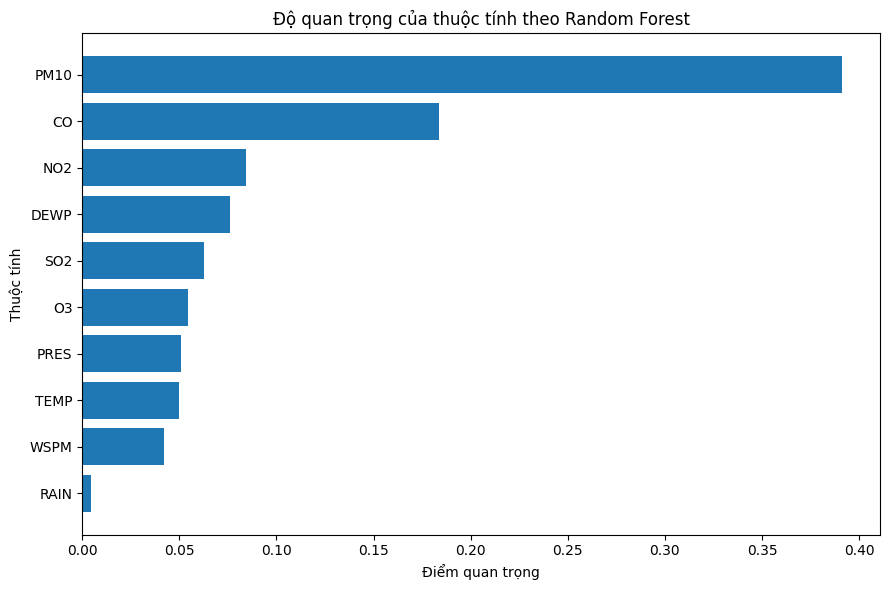

In [14]:
# Huấn luyện Random Forest trên tập huấn luyện để đánh giá độ quan trọng
rf_importance_model = RandomForestClassifier(
    n_estimators=100,       # Sử dụng 100 cây quyết định
    random_state=42,        # Cố định kết quả
    n_jobs=-1               # Tận dụng các lõi CPU
)

# Học mối quan hệ giữa các thuộc tính và nhãn phân loại
rf_importance_model.fit(X_train, y_train)

# Lấy điểm quan trọng của từng thuộc tính từ mô hình
importance_scores = rf_importance_model.feature_importances_

# Tổng hợp tên thuộc tính và điểm quan trọng thành bảng
importance_summary = pd.DataFrame({
    "Thuộc tính": X_train.columns,
    "Độ quan trọng": importance_scores
})

# Sắp xếp các thuộc tính theo độ quan trọng giảm dần
importance_summary = importance_summary.sort_values(
    by="Độ quan trọng",
    ascending=False
)

# Chọn năm thuộc tính có điểm quan trọng cao nhất
selected_features_importance = importance_summary.head(5)["Thuộc tính"].tolist()

# In danh sách thuộc tính được chọn
print("Năm thuộc tính quan trọng nhất:")
print(selected_features_importance)

# Hiển thị bảng xếp hạng độ quan trọng
display(importance_summary.round(4))

# Vẽ biểu đồ độ quan trọng của các thuộc tính
plt.figure(figsize=(9, 6))
plt.barh(
    importance_summary["Thuộc tính"],
    importance_summary["Độ quan trọng"]
)

# Đặt thuộc tính quan trọng nhất ở phía trên
plt.gca().invert_yaxis()

# Bổ sung tiêu đề và nhãn trục
plt.title("Độ quan trọng của thuộc tính theo Random Forest")
plt.xlabel("Điểm quan trọng")
plt.ylabel("Thuộc tính")

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Kết quả cho thấy năm thuộc tính có độ quan trọng cao nhất là PM10, CO, NO2, DEWP và SO2.

- **PM10** có điểm quan trọng cao nhất, đạt 0,3912, vượt trội so với các thuộc tính còn lại.
- **CO** đứng thứ hai với 0,1837.
- **NO2**, **DEWP** và **SO2** lần lượt đạt 0,0841, 0,0760 và 0,0629.
- **RAIN** có điểm thấp nhất, đạt 0,0046, cho thấy mức đóng góp tương đối thấp theo tiêu chí độ quan trọng của mô hình này.

Random Forest Feature Importance đánh giá thuộc tính dựa trên mức giảm độ hỗn tạp khi thuộc tính được sử dụng để phân chia dữ liệu trong các cây quyết định. Điểm số phản ánh mức đóng góp tương đối trong mô hình đã huấn luyện, không thể hiện quan hệ nhân quả.

**Kết luận:** Kết quả tiếp tục cho thấy PM10 và CO là những thuộc tính nổi bật khi phân loại mức PM2.5. Tuy nhiên, thứ hạng khác biệt so với Mutual Information, vì hai phương pháp sử dụng tiêu chí đánh giá khác nhau. Cần đánh giá mô hình trên tập kiểm tra để xác nhận giá trị thực tế của các tập thuộc tính được lựa chọn.

### 10. Giảm chiều dữ liệu bằng PCA

**Mục tiêu:** Giảm số chiều của dữ liệu trong khi giữ lại phần lớn thông tin thể hiện qua phương sai.

**Phương pháp:** PCA tìm các hướng mới trong không gian dữ liệu sao cho thành phần đầu tiên giữ phương sai lớn nhất. Các thành phần tiếp theo giữ phương sai còn lại theo thứ tự giảm dần và không tương quan tuyến tính với nhau. Việc chọn số thành phần dựa trên tỷ lệ phương sai tích lũy.

**Đầu vào:** Dữ liệu huấn luyện và kiểm tra đã chuẩn hóa gồm 10 thuộc tính.

**Đầu ra:** Dữ liệu mới có số chiều thấp hơn, tỷ lệ phương sai giải thích của từng thành phần và tỷ lệ phương sai tích lũy.

PCA không sử dụng nhãn phân loại khi tìm các thành phần chính. Vì vậy, giữ được nhiều phương sai không nhất thiết đồng nghĩa với giữ được nhiều thông tin hữu ích nhất cho việc phân loại.

Số chiều ban đầu: 10
Số chiều sau PCA: 8
Tỷ lệ phương sai giải thích tích lũy: 0.9718


,Thành phần chính,Tỷ lệ phương sai giải thích,Tỷ lệ phương sai tích lũy
0,PC1,0.3627,0.3627
1,PC2,0.2386,0.6012
2,PC3,0.1146,0.7158
3,PC4,0.0997,0.8156
4,PC5,0.0570,0.8726
5,PC6,0.0439,0.9164
6,PC7,0.0295,0.9459
7,PC8,0.0259,0.9718


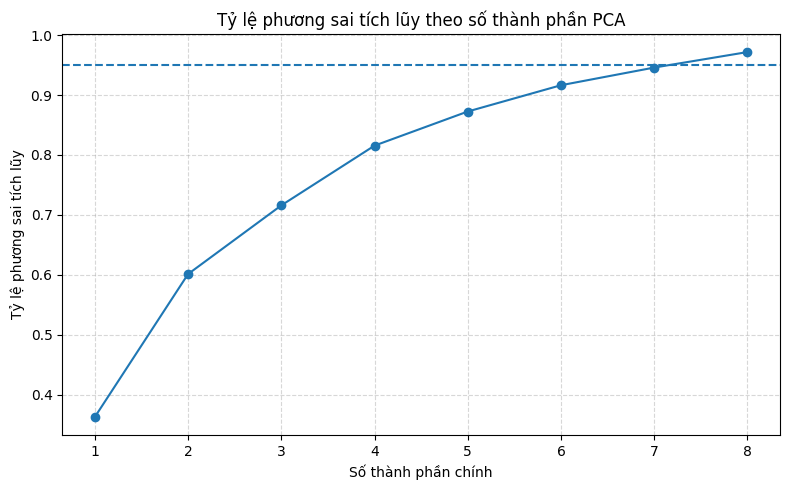

In [15]:
# Nhập công cụ PCA để giảm chiều dữ liệu
from sklearn.decomposition import PCA

# Khởi tạo PCA với 95% phương sai tích lũy mục tiêu
pca = PCA(
    n_components=0.95,       # Giữ số thành phần đủ giải thích ít nhất 95% phương sai
    random_state=42          # Cố định kết quả khi thuật toán có yếu tố ngẫu nhiên
)

# Học các thành phần chính từ dữ liệu huấn luyện đã chuẩn hóa
X_train_pca = pca.fit_transform(X_train_scaled)

# Biến đổi dữ liệu kiểm tra bằng các thành phần đã học từ tập huấn luyện
X_test_pca = pca.transform(X_test_scaled)

# In số chiều trước và sau khi áp dụng PCA
print("Số chiều ban đầu:", X_train_scaled.shape[1])
print("Số chiều sau PCA:", X_train_pca.shape[1])

# Tính tỷ lệ phương sai giải thích tích lũy của các thành phần được giữ
explained_cumulative = pca.explained_variance_ratio_.sum()

# In tỷ lệ phương sai tích lũy
print("Tỷ lệ phương sai giải thích tích lũy:", round(explained_cumulative, 4))

# Tạo bảng tỷ lệ phương sai giải thích theo từng thành phần
pca_summary = pd.DataFrame({
    "Thành phần chính": [
        f"PC{i + 1}" for i in range(len(pca.explained_variance_ratio_))
    ],
    "Tỷ lệ phương sai giải thích": pca.explained_variance_ratio_,
    "Tỷ lệ phương sai tích lũy": pca.explained_variance_ratio_.cumsum()
})

# Hiển thị bảng kết quả PCA
display(pca_summary.round(4))

# Vẽ biểu đồ phương sai giải thích tích lũy theo số thành phần
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(pca_summary) + 1),
    pca_summary["Tỷ lệ phương sai tích lũy"],
    marker="o"
)

# Vẽ đường tham chiếu tại mức phương sai 95%
plt.axhline(y=0.95, linestyle="--")

# Bổ sung tiêu đề và nhãn trục
plt.title("Tỷ lệ phương sai tích lũy theo số thành phần PCA")
plt.xlabel("Số thành phần chính")
plt.ylabel("Tỷ lệ phương sai tích lũy")
plt.xticks(range(1, len(pca_summary) + 1))
plt.grid(True, linestyle="--", alpha=0.5)

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Kết quả cho thấy PCA đã giảm số chiều dữ liệu từ **10 thuộc tính xuống còn 8 thành phần chính**, đồng thời giữ lại **97,18% phương sai** của dữ liệu ban đầu.

- **PC1** giải thích 36,27% phương sai, là thành phần đóng góp lớn nhất.
- **PC2** giải thích thêm 23,86%, đưa tỷ lệ phương sai tích lũy lên 60,13%.
- Sáu thành phần đầu giải thích 91,64% phương sai.
- Bảy thành phần giải thích 94,59%, chưa đạt ngưỡng 95%.
- Tám thành phần đạt 97,18%, vượt ngưỡng phương sai tích lũy đặt ra.

Biểu đồ cho thấy tỷ lệ phương sai tích lũy tăng khi bổ sung các thành phần chính, nhưng mức đóng góp của từng thành phần giảm dần.

**Kết luận:** PCA đã giảm được 2 chiều, tương đương 20% số chiều ban đầu, trong khi vẫn giữ lại phần lớn phương sai. Tuy nhiên, phương sai được giữ lại không đồng nghĩa với việc giữ nguyên toàn bộ thông tin hữu ích cho phân loại. Cần đánh giá hiệu quả mô hình nếu sử dụng dữ liệu sau PCA.

### 11. Giảm chiều dữ liệu bằng SVD

**Mục tiêu:** Biểu diễn dữ liệu bằng số thành phần ít hơn, qua đó giảm số chiều đầu vào cho các bước phân tích tiếp theo.

**Phương pháp:** SVD phân rã ma trận dữ liệu thành các thành phần dựa trên giá trị kỳ dị. TruncatedSVD chỉ giữ lại số thành phần được chỉ định, giúp xấp xỉ ma trận ban đầu bằng một biểu diễn có số chiều thấp hơn.

**Đầu vào:** Dữ liệu huấn luyện và kiểm tra đã chuẩn hóa, gồm 10 thuộc tính.

**Đầu ra:** Hai ma trận dữ liệu có 8 thành phần và bảng tỷ lệ phương sai giải thích tích lũy theo số thành phần.

SVD không sử dụng nhãn phân loại khi thực hiện giảm chiều. Kết quả sẽ được so sánh với PCA về số chiều đầu ra và lượng biến thiên dữ liệu được giữ lại.

Số chiều ban đầu: 10
Số chiều sau SVD: 8
Tỷ lệ phương sai giải thích tích lũy: 0.9718


,Thành phần,Tỷ lệ phương sai giải thích,Tỷ lệ phương sai tích lũy
0,SVD1,0.3627,0.3627
1,SVD2,0.2386,0.6012
2,SVD3,0.1146,0.7158
3,SVD4,0.0997,0.8156
4,SVD5,0.0570,0.8726
5,SVD6,0.0439,0.9164
6,SVD7,0.0295,0.9459
7,SVD8,0.0259,0.9718


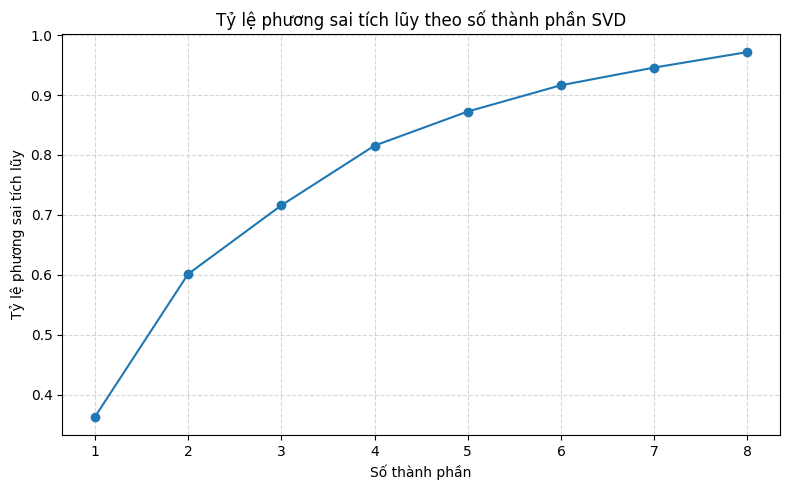

In [16]:
# Nhập công cụ TruncatedSVD để giảm chiều dữ liệu
from sklearn.decomposition import TruncatedSVD

# Khởi tạo SVD với tám thành phần
svd = TruncatedSVD(
    n_components=8,          # Giữ lại tám thành phần
    random_state=42          # Cố định kết quả
)

# Học phép phân rã và biến đổi tập huấn luyện đã chuẩn hóa
X_train_svd = svd.fit_transform(X_train_scaled)

# Biến đổi tập kiểm tra bằng phép phân rã đã học
X_test_svd = svd.transform(X_test_scaled)

# In số chiều trước và sau khi áp dụng SVD
print("Số chiều ban đầu:", X_train_scaled.shape[1])
print("Số chiều sau SVD:", X_train_svd.shape[1])

# Tính tỷ lệ phương sai giải thích tích lũy của tám thành phần
svd_cumulative = svd.explained_variance_ratio_.cumsum()

# In tỷ lệ phương sai giải thích tích lũy
print("Tỷ lệ phương sai giải thích tích lũy:", round(svd_cumulative[-1], 4))

# Tạo bảng kết quả theo từng thành phần
svd_summary = pd.DataFrame({
    "Thành phần": [f"SVD{i + 1}" for i in range(8)],
    "Tỷ lệ phương sai giải thích": svd.explained_variance_ratio_,
    "Tỷ lệ phương sai tích lũy": svd_cumulative
})

# Hiển thị bảng tỷ lệ phương sai
display(svd_summary.round(4))

# Vẽ biểu đồ phương sai tích lũy
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, 9),
    svd_summary["Tỷ lệ phương sai tích lũy"],
    marker="o"
)

# Bổ sung tiêu đề và nhãn trục
plt.title("Tỷ lệ phương sai tích lũy theo số thành phần SVD")
plt.xlabel("Số thành phần")
plt.ylabel("Tỷ lệ phương sai tích lũy")
plt.xticks(range(1, 9))
plt.grid(True, linestyle="--", alpha=0.5)

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Kết quả cho thấy TruncatedSVD đã giảm số chiều dữ liệu từ 10 thuộc tính xuống còn 8 thành phần, với tỷ lệ phương sai giải thích tích lũy đạt 97,18%.

- Thành phần SVD1 giải thích 36,27% phương sai.
- Hai thành phần đầu giải thích tích lũy 60,12%.
- Sáu thành phần đầu giải thích 91,64%.
- Tám thành phần đạt 97,18%, vượt ngưỡng 95% thường dùng để tham khảo khi lựa chọn số chiều.

Trong lần chạy này, tỷ lệ phương sai giải thích của SVD trùng với kết quả PCA ở cả tám thành phần. Điều này có thể xuất hiện do hai phương pháp được áp dụng trên cùng dữ liệu đã chuẩn hóa và cùng giữ các hướng thành phần tương ứng. Tuy nhiên, không nên mặc định PCA và SVD luôn cho kết quả giống nhau trong mọi cấu hình.

**Kết luận:** SVD đã giảm số chiều từ 10 xuống 8 trong khi giữ lại phần lớn phương sai của dữ liệu. Kết quả cho thấy SVD có thể dùng để biểu diễn dữ liệu ở số chiều thấp hơn, nhưng cần đánh giá thêm hiệu quả phân loại nếu mục tiêu là nâng cao chất lượng dự đoán.

### 12. Giảm chiều dữ liệu bằng LDA

**Mục tiêu:** Tìm các thành phần mới giúp phân biệt ba lớp mức PM2.5 trong không gian có số chiều thấp hơn.

**Phương pháp:** LDA sử dụng nhãn lớp để tìm hướng chiếu sao cho khoảng cách giữa trung bình các lớp lớn so với độ phân tán bên trong từng lớp. Với ba lớp, số thành phần phân biệt tối đa là hai.

**Đầu vào:** Dữ liệu huấn luyện và kiểm tra đã chuẩn hóa, cùng nhãn `y_train` của tập huấn luyện.

**Đầu ra:** Dữ liệu được chiếu xuống tối đa hai thành phần phân biệt và bảng tỷ lệ phương sai phân biệt được giải thích.

Khác với PCA và SVD, LDA sử dụng nhãn mục tiêu trong quá trình học phép chiếu. Do đó, phép biến đổi chỉ được học từ tập huấn luyện rồi áp dụng cho tập kiểm tra để tránh rò rỉ thông tin.

Số chiều ban đầu: 10
Số chiều sau LDA: 2
Tỷ lệ phương sai phân biệt tích lũy: 1.0


,Thành phần,Tỷ lệ phương sai phân biệt,Tỷ lệ tích lũy
0,LD1,0.9731,0.9731
1,LD2,0.0269,1.0000


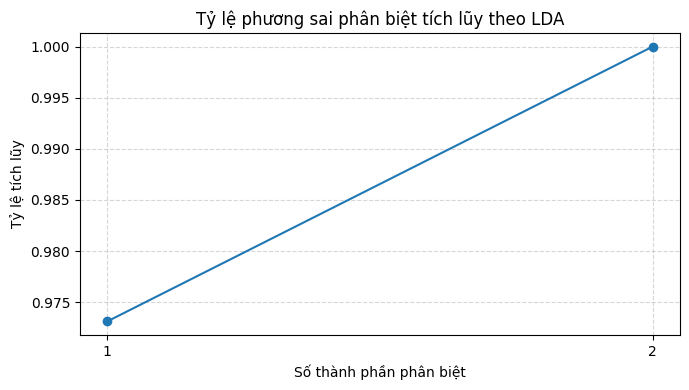

In [17]:
# Nhập công cụ LDA để giảm chiều có sử dụng nhãn lớp
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Đếm số lớp khác nhau trong tập huấn luyện
n_classes = y_train.nunique()

# Số thành phần LDA tối đa bằng số lớp trừ một
n_lda_components = min(X_train.shape[1], n_classes - 1)

# Khởi tạo LDA với số thành phần phân biệt tối đa
lda = LinearDiscriminantAnalysis(
    n_components=n_lda_components
)

# Học phép chiếu LDA bằng tập huấn luyện và nhãn tương ứng
X_train_lda = lda.fit_transform(X_train_scaled, y_train)

# Chiếu tập kiểm tra bằng phép biến đổi đã học
X_test_lda = lda.transform(X_test_scaled)

# In số chiều ban đầu và số chiều sau LDA
print("Số chiều ban đầu:", X_train_scaled.shape[1])
print("Số chiều sau LDA:", X_train_lda.shape[1])

# Tính tỷ lệ phương sai phân biệt tích lũy
lda_cumulative = lda.explained_variance_ratio_.cumsum()

# In tỷ lệ phương sai phân biệt giải thích được
print("Tỷ lệ phương sai phân biệt tích lũy:", round(lda_cumulative[-1], 4))

# Tạo bảng kết quả theo từng thành phần LDA
lda_summary = pd.DataFrame({
    "Thành phần": [
        f"LD{i + 1}" for i in range(len(lda.explained_variance_ratio_))
    ],
    "Tỷ lệ phương sai phân biệt": lda.explained_variance_ratio_,
    "Tỷ lệ tích lũy": lda_cumulative
})

# Hiển thị bảng kết quả LDA
display(lda_summary.round(4))

# Vẽ biểu đồ tỷ lệ phương sai phân biệt tích lũy
plt.figure(figsize=(7, 4))
plt.plot(
    range(1, len(lda_summary) + 1),
    lda_summary["Tỷ lệ tích lũy"],
    marker="o"
)

# Bổ sung tiêu đề và nhãn trục
plt.title("Tỷ lệ phương sai phân biệt tích lũy theo LDA")
plt.xlabel("Số thành phần phân biệt")
plt.ylabel("Tỷ lệ tích lũy")
plt.xticks(range(1, len(lda_summary) + 1))
plt.grid(True, linestyle="--", alpha=0.5)

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Kết quả cho thấy LDA đã giảm số chiều từ 10 thuộc tính ban đầu xuống còn 2 thành phần phân biệt. Điều này phù hợp với đặc điểm của LDA khi bài toán có ba lớp, bởi số thành phần phân biệt tối đa bằng số lớp trừ một.

- **LD1** giải thích 97,31% phương sai phân biệt, cho thấy phần lớn khả năng phân tách các lớp được thể hiện qua thành phần thứ nhất.
- **LD2** giải thích 2,69% còn lại.
- Hai thành phần kết hợp giải thích 100% phương sai phân biệt theo tiêu chí của mô hình LDA.

Khác với PCA và SVD, LDA sử dụng nhãn `PM25_Level` để tìm hướng chiếu giúp phân biệt các lớp. Vì vậy, LDA hướng đến khả năng phân loại thay vì chỉ giữ lại phương sai tổng thể của dữ liệu.

**Kết luận:** LDA giảm số chiều từ 10 xuống 2 và giữ toàn bộ phương sai phân biệt theo kết quả tính toán. Tuy nhiên, tỷ lệ 100% ở đây không có nghĩa là mô hình phân loại dự đoán chính xác 100% mẫu. Cần đánh giá riêng các chỉ số phân loại trên tập kiểm tra để xác định hiệu quả thực tế.

## 13. Kết luận Assignment 3

Trong bài tập này, các phương pháp lựa chọn đặc trưng và giảm chiều dữ liệu đã được áp dụng trên bộ dữ liệu Beijing Multi-Site Air Quality, với biến mục tiêu là `PM25_Level`.

### 13.1. Kết quả Feature Selection

Bốn phương pháp lựa chọn đặc trưng đã được triển khai:

- **RFECV:** lựa chọn 8 thuộc tính, với điểm F1-macro trung bình tốt nhất đạt 0,838 theo kiểm định chéo.
- **Variance Threshold:** giữ lại cả 10 thuộc tính vì không có thuộc tính nào có phương sai bằng 0.
- **SelectKBest với Mutual Information:** lựa chọn 5 thuộc tính gồm PM10, SO2, NO2, CO và O3.
- **Random Forest Feature Importance:** xếp hạng độ quan trọng của các thuộc tính, trong đó PM10 và CO có điểm cao nhất.

Các phương pháp cho kết quả khác nhau vì chúng sử dụng những tiêu chí đánh giá khác nhau. RFECV dựa trên hiệu quả của mô hình qua kiểm định chéo, Variance Threshold dựa trên phương sai, Mutual Information đo mức độ phụ thuộc với nhãn và Random Forest Feature Importance đánh giá mức đóng góp của thuộc tính trong mô hình cây.

### 13.2. Kết quả Dimensionality Reduction

Ba phương pháp giảm chiều đã được áp dụng:

- **PCA:** giảm từ 10 xuống 8 thành phần, giữ lại 97,18% phương sai.
- **SVD:** giảm từ 10 xuống 8 thành phần, giữ lại 97,18% phương sai theo kết quả thực nghiệm.
- **LDA:** giảm từ 10 xuống 2 thành phần phân biệt, giải thích 100% phương sai phân biệt theo mô hình.

PCA và SVD tạo các thành phần mới từ cấu trúc dữ liệu, trong khi LDA sử dụng nhãn lớp để tìm hướng chiếu có khả năng phân biệt các lớp tốt hơn.

### 13.3. Kết luận chung

Bài tập đã minh họa sự khác biệt giữa lựa chọn đặc trưng và giảm chiều dữ liệu. Feature Selection giữ lại các thuộc tính gốc, còn Feature Extraction tạo ra các thành phần mới để biểu diễn dữ liệu.

Kết quả có thể được sử dụng làm cơ sở lựa chọn đầu vào cho các mô hình học máy tiếp theo. Tuy nhiên, số lượng thuộc tính ít hơn hoặc tỷ lệ phương sai cao hơn chưa đủ để kết luận mô hình tốt hơn. Cần so sánh hiệu quả dự đoán trên tập kiểm tra bằng các chỉ số phù hợp, đặc biệt là F1-score và ma trận nhầm lẫn đối với bài toán phân loại nhiều lớp.

# ASSIGNMENT 4: REGRESSION

## 1. Mục tiêu

Bài tập áp dụng các mô hình hồi quy trên bộ dữ liệu Beijing Multi-Site Air Quality nhằm phân tích mối quan hệ giữa các yếu tố chất lượng không khí, khí tượng và mức PM2.5.

Bốn mô hình cần triển khai gồm:

- **Simple Linear Regression:** Phân tích mối quan hệ tuyến tính giữa một biến đầu vào và biến mục tiêu.
- **Multiple Linear Regression:** Sử dụng nhiều biến đầu vào để dự đoán một biến mục tiêu liên tục.
- **Polynomial Regression:** Bổ sung các lũy thừa của biến đầu vào để mô hình hóa mối quan hệ phi tuyến.
- **Logistic Regression:** Dự đoán lớp mức ô nhiễm PM2.5 dựa trên các biến đầu vào.

## 2. Dữ liệu và cách đánh giá

### 2.1. Bộ dữ liệu sử dụng

Bài tập tiếp tục sử dụng bộ dữ liệu Beijing Multi-Site Air Quality đã được khám phá và tiền xử lý ở Assignment 2. Dữ liệu gồm các chỉ số chất lượng không khí và yếu tố khí tượng được ghi nhận theo giờ tại nhiều trạm quan trắc.

Các thuộc tính đầu vào gồm PM10, SO2, NO2, CO, O3, TEMP, PRES, DEWP, RAIN và WSPM.

Biến mục tiêu được xác định theo từng loại bài toán:

- Với Simple Linear Regression, Multiple Linear Regression và Polynomial Regression, biến mục tiêu là nồng độ PM2.5.
- Với Logistic Regression, biến mục tiêu là `PM25_Level`, gồm ba lớp Thấp, Trung bình và Cao được tạo ở bước tiền xử lý trước đó.

PM2.5 không được đưa vào tập đặc trưng khi dự đoán chính nồng độ PM2.5. Điều này giúp tránh việc mô hình nhận trực tiếp giá trị cần dự đoán làm đầu vào.

### 2.2. Tiền xử lý dữ liệu

Sử dụng 30.000 quan sát được lấy mẫu phân tầng theo `PM25_Level` để giảm thời gian tính toán và duy trì gần đúng tỷ lệ các lớp. Dữ liệu được chia thành tập huấn luyện chiếm 80% và tập kiểm tra chiếm 20%.

Với Logistic Regression, các thuộc tính đầu vào được chuẩn hóa bằng StandardScaler. Bộ chuẩn hóa chỉ được học trên tập huấn luyện, sau đó áp dụng cho tập kiểm tra nhằm tránh rò rỉ thông tin.

Ba mô hình hồi quy giá trị liên tục sử dụng các thuộc tính đầu vào đã được xử lý giá trị thiếu. Những bước biến đổi bổ sung sẽ được thực hiện riêng cho từng mô hình khi cần thiết.

### 2.3. Phương pháp đánh giá

Đối với ba mô hình dự đoán nồng độ PM2.5, sử dụng các chỉ số:

- **MAE (Mean Absolute Error):** Sai số tuyệt đối trung bình giữa giá trị dự đoán và giá trị thực tế. Giá trị càng thấp càng tốt.
- **RMSE (Root Mean Squared Error):** Căn bậc hai của sai số bình phương trung bình. Chỉ số này nhạy hơn với các sai số lớn. Giá trị càng thấp càng tốt.
- **R² (Coefficient of Determination):** Đo mức độ mô hình giải thích sự biến thiên của biến mục tiêu. Giá trị càng gần 1 thường thể hiện khả năng dự đoán càng tốt. R² có thể âm nếu mô hình dự đoán kém hơn phương án dự đoán bằng giá trị trung bình.

Đối với Logistic Regression, sử dụng Accuracy, Precision, Recall, F1-score và ma trận nhầm lẫn để đánh giá khả năng phân loại ba lớp.

## 3. Quy trình thực hiện

Bài tập được triển khai tuần tự theo bốn mô hình:

1. Simple Linear Regression với một biến đầu vào.
2. Multiple Linear Regression với nhiều biến đầu vào.
3. Polynomial Regression với các đặc trưng đa thức.
4. Logistic Regression để phân loại mức PM2.5.

Mỗi mô hình được huấn luyện trên tập huấn luyện và đánh giá trên tập kiểm tra. Kết quả được nhận xét dựa trên các chỉ số tương ứng và được dùng để so sánh ưu điểm, hạn chế của từng phương pháp.

In [18]:
# Nhập công cụ chia dữ liệu và chuẩn hóa
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Khai báo các biến đầu vào, không đưa PM2.5 vào đặc trưng
feature_cols = [
    "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

# Tạo bảng dữ liệu gồm biến đầu vào, mục tiêu liên tục và nhãn phân loại
regression_data = df_class[feature_cols + ["PM2.5", "PM25_Level"]].copy()

# Lấy mẫu tối đa 30.000 quan sát và giữ tỷ lệ các lớp gần với dữ liệu gốc
if len(regression_data) > 30000:
    regression_sample, _ = train_test_split(
        regression_data,
        train_size=30000,
        stratify=regression_data["PM25_Level"],
        random_state=42
    )
else:
    # Dùng toàn bộ dữ liệu nếu số quan sát không vượt quá 30.000
    regression_sample = regression_data.copy()

# Tách biến đầu vào X khỏi các biến mục tiêu
X = regression_sample[feature_cols]

# Lấy nồng độ PM2.5 làm mục tiêu cho các mô hình hồi quy giá trị liên tục
y_reg = regression_sample["PM2.5"]

# Lấy nhãn mức PM2.5 làm mục tiêu cho Logistic Regression
y_cls = regression_sample["PM25_Level"]

# Chia dữ liệu thành tập huấn luyện và kiểm tra theo tỷ lệ 80:20
X_train, X_test, y_train_reg, y_test_reg, y_train_cls, y_test_cls = train_test_split(
    X,
    y_reg,
    y_cls,
    test_size=0.2,
    stratify=y_cls,
    random_state=42
)

# Khởi tạo bộ chuẩn hóa dành riêng cho Logistic Regression
logistic_scaler = StandardScaler()

# Học tham số chuẩn hóa từ tập đầu vào huấn luyện
X_train_log_scaled = logistic_scaler.fit_transform(X_train)

# Áp dụng cùng tham số chuẩn hóa lên tập đầu vào kiểm tra
X_test_log_scaled = logistic_scaler.transform(X_test)

# In kích thước các tập dữ liệu để kiểm tra quá trình chia
print("Tổng số quan sát:", len(regression_sample))
print("Số biến đầu vào:", len(feature_cols))
print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test:", X_test.shape)
print("Kích thước y_train_reg:", y_train_reg.shape)
print("Kích thước y_test_reg:", y_test_reg.shape)
print("Kích thước y_train_cls:", y_train_cls.shape)
print("Kích thước y_test_cls:", y_test_cls.shape)

# Hiển thị phân bố lớp trong tập huấn luyện
print("\nTỷ lệ lớp trong tập huấn luyện:")
display((y_train_cls.value_counts(normalize=True) * 100).round(2))

# Hiển thị phân bố lớp trong tập kiểm tra
print("\nTỷ lệ lớp trong tập kiểm tra:")
display((y_test_cls.value_counts(normalize=True) * 100).round(2))

# Kiểm tra kích thước dữ liệu đã chuẩn hóa cho Logistic Regression
print("\nKích thước dữ liệu huấn luyện đã chuẩn hóa:", X_train_log_scaled.shape)
print("Kích thước dữ liệu kiểm tra đã chuẩn hóa:", X_test_log_scaled.shape)

Tổng số quan sát: 30000
Số biến đầu vào: 10
Kích thước X_train: (24000, 10)
Kích thước X_test: (6000, 10)
Kích thước y_train_reg: (24000,)
Kích thước y_test_reg: (6000,)
Kích thước y_train_cls: (24000,)
Kích thước y_test_cls: (6000,)

Tỷ lệ lớp trong tập huấn luyện:


PM25_Level
Cao           38.73
Thấp          35.88
Trung bình    25.39
Name: proportion, dtype: float64


Tỷ lệ lớp trong tập kiểm tra:


PM25_Level
Cao           38.73
Thấp          35.88
Trung bình    25.38
Name: proportion, dtype: float64


Kích thước dữ liệu huấn luyện đã chuẩn hóa: (24000, 10)
Kích thước dữ liệu kiểm tra đã chuẩn hóa: (6000, 10)


Kết quả cho thấy dữ liệu đã được chuẩn bị thành công cho bốn mô hình hồi quy.

- **Quy mô dữ liệu:** 30.000 quan sát với 10 biến đầu vào.
- **Chia tập dữ liệu:** tập huấn luyện gồm 24.000 mẫu và tập kiểm tra gồm 6.000 mẫu, tương ứng tỷ lệ 80:20.
- **Phân bố lớp:** hai tập có tỷ lệ các lớp gần như giống nhau. Lớp Cao chiếm 38,73%, lớp Thấp chiếm 35,88% và lớp Trung bình chiếm khoảng 25,38–25,39%.
- **Chuẩn hóa dữ liệu:** dữ liệu dành cho Logistic Regression có kích thước 24.000 × 10 ở tập huấn luyện và 6.000 × 10 ở tập kiểm tra.

**Kết luận:** Dữ liệu đã sẵn sàng để xây dựng các mô hình. Việc chia tập trước khi huấn luyện giúp đánh giá khả năng dự đoán trên những quan sát chưa được mô hình sử dụng trong quá trình học.

### 3. Simple Linear Regression - Hồi quy tuyến tính đơn biến

**Mục tiêu:** Xây dựng mô hình dự đoán nồng độ PM2.5 từ một biến đầu vào duy nhất là PM10.

**Phương pháp:** Hồi quy tuyến tính đơn tìm đường thẳng phù hợp nhất với dữ liệu bằng cách tối thiểu hóa tổng bình phương sai số dự đoán. Hệ số góc cho biết chiều và mức thay đổi dự đoán của PM2.5 khi PM10 tăng một đơn vị trong mô hình.

**Đầu vào:** Thuộc tính PM10 trong tập huấn luyện và tập kiểm tra.

**Đầu ra:** Giá trị PM2.5 dự đoán, hệ số mô hình, các chỉ số MAE, RMSE, R² và biểu đồ so sánh giá trị thực tế với đường hồi quy.

Mô hình chỉ sử dụng một biến nên dễ diễn giải, nhưng có thể chưa phản ánh đầy đủ mối quan hệ phức tạp giữa các yếu tố ảnh hưởng đến PM2.5.

Hệ số chặn: -0.4422
Hệ số của PM10: 0.7636

MAE: 22.9225
RMSE: 37.8948
R²: 0.7594


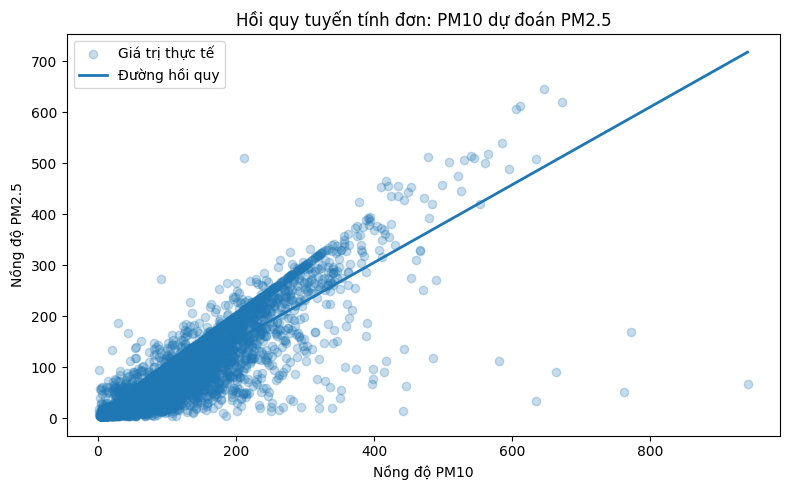

In [19]:
# Nhập mô hình hồi quy tuyến tính và các chỉ số đánh giá
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# Lấy riêng cột PM10 làm đầu vào cho hồi quy tuyến tính đơn
X_train_simple = X_train[["PM10"]]
X_test_simple = X_test[["PM10"]]

# Khởi tạo mô hình hồi quy tuyến tính đơn
simple_model = LinearRegression()

# Huấn luyện mô hình bằng PM10 và nồng độ PM2.5 thực tế
simple_model.fit(X_train_simple, y_train_reg)

# Dự đoán nồng độ PM2.5 trên tập kiểm tra
y_pred_simple = simple_model.predict(X_test_simple)

# Tính sai số tuyệt đối trung bình
mae_simple = mean_absolute_error(y_test_reg, y_pred_simple)

# Tính căn bậc hai của sai số bình phương trung bình
rmse_simple = np.sqrt(mean_squared_error(y_test_reg, y_pred_simple))

# Tính hệ số xác định R²
r2_simple = r2_score(y_test_reg, y_pred_simple)

# In hệ số chặn và hệ số góc của đường hồi quy
print("Hệ số chặn:", round(simple_model.intercept_, 4))
print("Hệ số của PM10:", round(simple_model.coef_[0], 4))

# In các chỉ số đánh giá mô hình
print("\nMAE:", round(mae_simple, 4))
print("RMSE:", round(rmse_simple, 4))
print("R²:", round(r2_simple, 4))

# Tạo biểu đồ phân tán giữa PM10 và PM2.5 thực tế
plt.figure(figsize=(8, 5))
plt.scatter(
    X_test_simple["PM10"],
    y_test_reg,
    alpha=0.25,
    label="Giá trị thực tế"
)

# Sắp xếp PM10 để vẽ đường hồi quy theo thứ tự tăng dần
sort_idx = np.argsort(X_test_simple["PM10"].values)

# Vẽ đường biểu diễn giá trị PM2.5 mà mô hình dự đoán
plt.plot(
    X_test_simple["PM10"].values[sort_idx],
    y_pred_simple[sort_idx],
    linewidth=2,
    label="Đường hồi quy"
)

# Bổ sung tiêu đề và nhãn cho biểu đồ
plt.title("Hồi quy tuyến tính đơn: PM10 dự đoán PM2.5")
plt.xlabel("Nồng độ PM10")
plt.ylabel("Nồng độ PM2.5")
plt.legend()

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Mô hình sử dụng PM10 làm biến đầu vào duy nhất để dự đoán nồng độ PM2.5, thu được các kết quả sau:

- **Hệ số chặn:** -0,4422.
- **Hệ số PM10:** 0,7636.
- **MAE:** 22,9225.
- **RMSE:** 37,8948.
- **R²:** 0,7594.

Hệ số PM10 dương cho thấy khi PM10 tăng một đơn vị, giá trị PM2.5 dự đoán tăng trung bình khoảng 0,7636 đơn vị theo mô hình tuyến tính, trong điều kiện chỉ xét biến đầu vào này.

R² bằng 0,7594 cho thấy mô hình giải thích được khoảng 75,94% mức biến thiên của PM2.5 trên tập kiểm tra. MAE cho biết sai lệch tuyệt đối trung bình khoảng 22,92 đơn vị, trong khi RMSE khoảng 37,89 đơn vị. RMSE cao hơn MAE cho thấy một số dự đoán có sai số lớn ảnh hưởng đáng kể đến kết quả.

Trên biểu đồ, phần lớn điểm dữ liệu tập trung gần đường hồi quy ở vùng nồng độ thấp đến trung bình, nhưng độ phân tán tăng khi PM10 tăng. Một số điểm nằm xa đường hồi quy cho thấy mô hình tuyến tính đơn chưa mô tả tốt tất cả các quan sát.

**Kết luận:** PM10 là biến đầu vào có khả năng dự đoán PM2.5 tương đối tốt trong mô hình đơn biến này. Tuy nhiên, mô hình chỉ xét một yếu tố nên chưa phản ánh ảnh hưởng kết hợp của các chất ô nhiễm và điều kiện khí tượng.

### 4. Multiple Linear Regression

**Mục tiêu:** Dự đoán nồng độ PM2.5 bằng nhiều thuộc tính chất lượng không khí và khí tượng thay vì chỉ sử dụng PM10.

**Phương pháp:** Hồi quy tuyến tính đa biến mô hình hóa biến mục tiêu bằng tổng có trọng số của nhiều biến đầu vào. Các hệ số được ước lượng bằng phương pháp bình phương tối thiểu để giảm tổng bình phương sai số giữa giá trị thực tế và giá trị dự đoán.

**Đầu vào:** Mười thuộc tính gồm PM10, SO2, NO2, CO, O3, TEMP, PRES, DEWP, RAIN và WSPM.

**Đầu ra:** Giá trị PM2.5 dự đoán, hệ số của từng thuộc tính và các chỉ số MAE, RMSE, R² trên tập kiểm tra.

Kết quả được so sánh với hồi quy tuyến tính đơn để đánh giá liệu việc bổ sung các biến đầu vào có cải thiện khả năng dự đoán hay không.

MAE: 20.6362
RMSE: 31.6297
R²: 0.8324


,Thuộc tính,Hệ số hồi quy
7,DEWP,1.5277
5,TEMP,-1.3090
0,PM10,0.5512
9,WSPM,-0.3676
6,PRES,0.3385
1,SO2,0.1900
4,O3,0.1059
2,NO2,0.0996
8,RAIN,0.0828
3,CO,0.0172


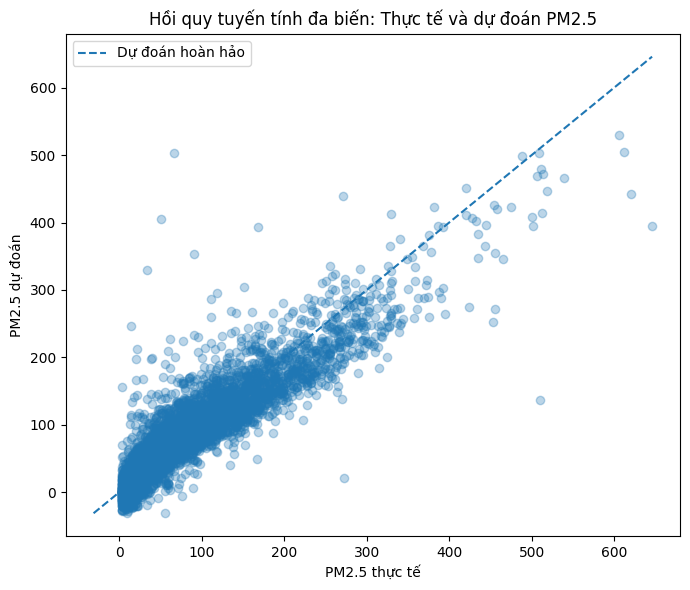

In [20]:
# Khởi tạo mô hình hồi quy tuyến tính đa biến
multiple_model = LinearRegression()

# Huấn luyện mô hình bằng mười thuộc tính đầu vào và PM2.5 thực tế
multiple_model.fit(X_train, y_train_reg)

# Dự đoán nồng độ PM2.5 trên tập kiểm tra
y_pred_multiple = multiple_model.predict(X_test)

# Tính sai số tuyệt đối trung bình của mô hình
mae_multiple = mean_absolute_error(y_test_reg, y_pred_multiple)

# Tính căn bậc hai của sai số bình phương trung bình
rmse_multiple = np.sqrt(mean_squared_error(y_test_reg, y_pred_multiple))

# Tính hệ số xác định R² trên tập kiểm tra
r2_multiple = r2_score(y_test_reg, y_pred_multiple)

# In các chỉ số đánh giá mô hình
print("MAE:", round(mae_multiple, 4))
print("RMSE:", round(rmse_multiple, 4))
print("R²:", round(r2_multiple, 4))

# Tạo bảng hệ số hồi quy theo từng thuộc tính
multiple_coef_summary = pd.DataFrame({
    "Thuộc tính": X_train.columns,
    "Hệ số hồi quy": multiple_model.coef_
})

# Sắp xếp hệ số theo trị tuyệt đối để dễ quan sát độ lớn
multiple_coef_summary["Trị tuyệt đối hệ số"] = (
    multiple_coef_summary["Hệ số hồi quy"].abs()
)

# Hiển thị hệ số hồi quy theo độ lớn tuyệt đối giảm dần
display(
    multiple_coef_summary
    .sort_values("Trị tuyệt đối hệ số", ascending=False)
    .drop(columns="Trị tuyệt đối hệ số")
    .round(4)
)

# Vẽ biểu đồ so sánh giá trị PM2.5 thực tế và dự đoán
plt.figure(figsize=(7, 6))
plt.scatter(y_test_reg, y_pred_multiple, alpha=0.3)

# Xác định phạm vi chung để vẽ đường dự đoán hoàn hảo
plot_min = min(y_test_reg.min(), y_pred_multiple.min())
plot_max = max(y_test_reg.max(), y_pred_multiple.max())

# Vẽ đường tham chiếu khi giá trị dự đoán bằng giá trị thực tế
plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--",
    label="Dự đoán hoàn hảo"
)

# Bổ sung tiêu đề và nhãn trục
plt.title("Hồi quy tuyến tính đa biến: Thực tế và dự đoán PM2.5")
plt.xlabel("PM2.5 thực tế")
plt.ylabel("PM2.5 dự đoán")
plt.legend()

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Mô hình hồi quy tuyến tính đa biến sử dụng 10 thuộc tính đầu vào để dự đoán nồng độ PM2.5 và đạt các kết quả sau:

- **MAE:** 20,6362.
- **RMSE:** 31,6297.
- **R²:** 0,8324.

So với hồi quy tuyến tính đơn sử dụng PM10, MAE giảm từ 22,9225 xuống 20,6362 và RMSE giảm từ 37,8948 xuống 31,6297. R² tăng từ 0,7594 lên 0,8324. Điều này cho thấy việc bổ sung các biến chất lượng không khí và khí tượng đã cải thiện khả năng dự đoán trên tập kiểm tra.

Trong bảng hệ số, DEWP có hệ số dương lớn nhất về trị tuyệt đối trong kết quả hiển thị, đạt 1,5277. TEMP có hệ số âm -1,3090 và PM10 có hệ số dương 0,5512. Các hệ số biểu thị mối liên hệ tuyến tính có điều kiện khi giữ các biến đầu vào khác không đổi. Do các thuộc tính có đơn vị đo và mức độ biến thiên khác nhau, không nên chỉ dựa vào độ lớn hệ số để kết luận biến nào quan trọng nhất.

Biểu đồ cho thấy phần lớn điểm dự đoán nằm tương đối gần đường tham chiếu, nhưng vẫn có một số quan sát sai lệch lớn, đặc biệt ở vùng nồng độ PM2.5 cao.

**Kết luận:** Trong hai mô hình đã thử, hồi quy tuyến tính đa biến cho kết quả tốt hơn hồi quy tuyến tính đơn. Tuy nhiên, mô hình vẫn có sai số đáng kể ở một số quan sát và giả định quan hệ tuyến tính có thể chưa mô tả đầy đủ mối quan hệ giữa các biến.

### 5. Polynomial Regression - Hồi quy đa thức

**Mục tiêu:** Khảo sát liệu việc bổ sung thành phần bậc hai của PM10 có cải thiện khả năng dự đoán PM2.5 so với hồi quy tuyến tính đơn hay không.

**Phương pháp:** Polynomial Regression sử dụng PolynomialFeatures để tạo thêm đặc trưng bình phương từ biến đầu vào. Mô hình hồi quy tuyến tính sau đó học hệ số trên các đặc trưng mới nhằm mô tả mối quan hệ có thể phi tuyến.

**Đầu vào:** PM10 trong tập huấn luyện và tập kiểm tra.

**Đầu ra:** Giá trị PM2.5 dự đoán, các chỉ số MAE, RMSE, R² và biểu đồ so sánh giá trị thực tế với đường dự đoán đa thức.

Trong thí nghiệm này sử dụng đa thức bậc 2. Kết quả sẽ được so sánh với Simple Linear Regression để xác định liệu thành phần bình phương có cải thiện khả năng dự đoán hay không.

Tên đặc trưng đa thức: ['PM10' 'PM10^2']
Hệ số hồi quy: [ 8.86259385e-01 -3.15687210e-04]
Hệ số chặn: -7.1682

MAE: 23.3663
RMSE: 37.3462
R²: 0.7663


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


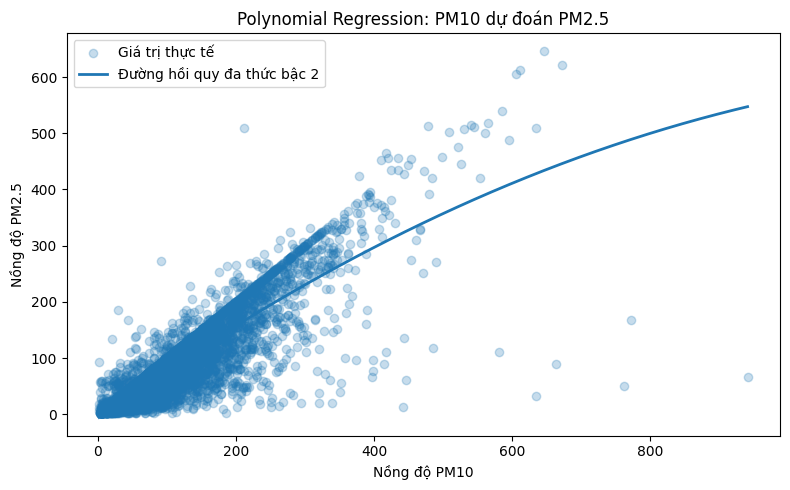

In [21]:
# Nhập công cụ tạo đặc trưng đa thức
from sklearn.preprocessing import PolynomialFeatures

# Khởi tạo phép biến đổi đa thức bậc hai, không tạo riêng hệ số chặn
poly_transformer = PolynomialFeatures(
    degree=2,
    include_bias=False
)

# Chỉ lấy PM10 làm biến đầu vào cho mô hình đa thức
X_train_poly_source = X_train[["PM10"]]
X_test_poly_source = X_test[["PM10"]]

# Tạo các đặc trưng PM10 và PM10 bình phương từ tập huấn luyện
X_train_poly = poly_transformer.fit_transform(X_train_poly_source)

# Áp dụng phép biến đổi đã học lên tập kiểm tra
X_test_poly = poly_transformer.transform(X_test_poly_source)

# Khởi tạo mô hình hồi quy tuyến tính trên các đặc trưng đa thức
polynomial_model = LinearRegression()

# Huấn luyện mô hình bằng đặc trưng đa thức và PM2.5 thực tế
polynomial_model.fit(X_train_poly, y_train_reg)

# Dự đoán PM2.5 trên tập kiểm tra
y_pred_poly = polynomial_model.predict(X_test_poly)

# Tính MAE của mô hình đa thức
mae_poly = mean_absolute_error(y_test_reg, y_pred_poly)

# Tính RMSE của mô hình đa thức
rmse_poly = np.sqrt(mean_squared_error(y_test_reg, y_pred_poly))

# Tính R² của mô hình đa thức
r2_poly = r2_score(y_test_reg, y_pred_poly)

# In tên các đặc trưng đa thức được tạo
print("Tên đặc trưng đa thức:", poly_transformer.get_feature_names_out(["PM10"]))

# In hệ số hồi quy của các đặc trưng đa thức
print("Hệ số hồi quy:", polynomial_model.coef_)

# In hệ số chặn của mô hình đa thức
print("Hệ số chặn:", round(polynomial_model.intercept_, 4))

# In các chỉ số đánh giá mô hình
print("\nMAE:", round(mae_poly, 4))
print("RMSE:", round(rmse_poly, 4))
print("R²:", round(r2_poly, 4))

# Tạo dãy PM10 tăng dần để vẽ đường dự đoán mượt
pm10_range = np.linspace(
    X_test_poly_source["PM10"].min(),
    X_test_poly_source["PM10"].max(),
    300
).reshape(-1, 1)

# Biến đổi dãy PM10 thành đặc trưng đa thức bậc hai
pm10_range_poly = poly_transformer.transform(pm10_range)

# Dự đoán PM2.5 tương ứng với dãy PM10 dùng để vẽ
pm25_range_pred = polynomial_model.predict(pm10_range_poly)

# Vẽ các quan sát thực tế và đường hồi quy đa thức
plt.figure(figsize=(8, 5))
plt.scatter(
    X_test_poly_source["PM10"],
    y_test_reg,
    alpha=0.25,
    label="Giá trị thực tế"
)

# Vẽ đường cong đa thức bậc hai
plt.plot(
    pm10_range.ravel(),
    pm25_range_pred,
    linewidth=2,
    label="Đường hồi quy đa thức bậc 2"
)

# Bổ sung tiêu đề và nhãn trục
plt.title("Polynomial Regression: PM10 dự đoán PM2.5")
plt.xlabel("Nồng độ PM10")
plt.ylabel("Nồng độ PM2.5")
plt.legend()

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Mô hình hồi quy đa thức bậc 2 sử dụng PM10 và PM10 bình phương để dự đoán nồng độ PM2.5, thu được kết quả:

- **MAE:** 23,3663.
- **RMSE:** 37,3462.
- **R²:** 0,7663.

So với Simple Linear Regression, MAE tăng từ 22,9225 lên 23,3663, trong khi RMSE giảm nhẹ từ 37,8948 xuống 37,3462 và R² tăng từ 0,7594 lên 0,7663. Như vậy, mô hình đa thức cải thiện nhẹ khả năng giải thích biến thiên và giảm một phần sai số lớn, nhưng sai số tuyệt đối trung bình lại cao hơn.

Đường cong dự đoán thể hiện mối quan hệ phi tuyến giữa PM10 và PM2.5. Tuy nhiên, nhiều điểm dữ liệu vẫn phân tán xa đường cong, đặc biệt tại vùng nồng độ cao. Điều này cho thấy chỉ bổ sung thành phần bình phương của PM10 chưa đủ để mô tả toàn bộ sự biến thiên của PM2.5.

**Kết luận:** Với kết quả hiện tại, Polynomial Regression bậc 2 chưa vượt trội rõ ràng so với hồi quy tuyến tính đơn. Việc chọn mô hình cần dựa trên các chỉ số đánh giá thay vì mặc định mô hình phức tạp hơn sẽ tốt hơn.

### 6. Logistic Regression - Hồi quy logistic

**Mục tiêu:** Phân loại mức ô nhiễm PM2.5 thành ba lớp Thấp, Trung bình và Cao dựa trên các thuộc tính chất lượng không khí và khí tượng.

**Phương pháp:** Logistic Regression ước lượng xác suất một quan sát thuộc từng lớp. Với bài toán nhiều lớp, mô hình sử dụng cơ chế phân loại đa lớp và chọn lớp có xác suất dự đoán cao nhất. Các hệ số được học thông qua quá trình tối ưu hàm mất mát phân loại.

**Đầu vào:** Mười thuộc tính đã chuẩn hóa gồm PM10, SO2, NO2, CO, O3, TEMP, PRES, DEWP, RAIN và WSPM.

**Đầu ra:** Nhãn lớp dự đoán và xác suất dự đoán cho từng lớp. Hiệu quả mô hình được đánh giá bằng Accuracy, Precision, Recall, F1-score và ma trận nhầm lẫn.

Trong đó, Accuracy phản ánh tỷ lệ dự đoán đúng trên toàn bộ mẫu. Precision đo mức độ chính xác của các dự đoán thuộc một lớp. Recall đo khả năng tìm đúng các mẫu thực sự thuộc lớp đó. F1-score là trung bình điều hòa giữa Precision và Recall. Ma trận nhầm lẫn giúp xác định mô hình thường nhầm lẫn giữa những lớp nào.

Accuracy: 0.8185

Báo cáo phân loại:
              precision    recall  f1-score   support

         Cao       0.88      0.86      0.87      2324
        Thấp       0.86      0.90      0.88      2153
  Trung bình       0.66      0.64      0.65      1523

    accuracy                           0.82      6000
   macro avg       0.80      0.80      0.80      6000
weighted avg       0.82      0.82      0.82      6000

Ma trận nhầm lẫn:


,Dự đoán: Cao,Dự đoán: Thấp,Dự đoán: Trung bình
Thực tế: Cao,2005,11,308
Thực tế: Thấp,20,1935,198
Thực tế: Trung bình,258,294,971


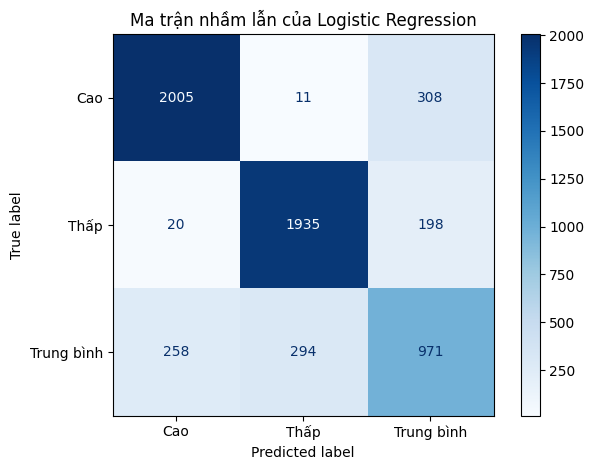

In [22]:
# Nhập mô hình Logistic Regression và các công cụ đánh giá phân loại
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Khởi tạo Logistic Regression với số vòng lặp tối đa đủ lớn để hội tụ
logistic_model = LogisticRegression(
    max_iter=1000,           # Cho phép tối đa 1000 vòng lặp tối ưu
    random_state=42          # Cố định kết quả khi có yếu tố ngẫu nhiên
)

# Huấn luyện mô hình bằng dữ liệu đã chuẩn hóa và nhãn lớp huấn luyện
logistic_model.fit(X_train_log_scaled, y_train_cls)

# Dự đoán nhãn lớp trên tập kiểm tra
y_pred_logistic = logistic_model.predict(X_test_log_scaled)

# Lấy danh sách các lớp theo thứ tự nhất quán để báo cáo kết quả
class_labels = sorted(y_train_cls.unique())

# Tính độ chính xác tổng thể trên tập kiểm tra
accuracy_logistic = accuracy_score(y_test_cls, y_pred_logistic)

# In Accuracy
print("Accuracy:", round(accuracy_logistic, 4))

# In Precision, Recall, F1-score và số lượng mẫu của từng lớp
print("\nBáo cáo phân loại:")
print(
    classification_report(
        y_test_cls,             # Nhãn thực tế
        y_pred_logistic,        # Nhãn dự đoán
        labels=class_labels,    # Thứ tự các lớp được báo cáo
        zero_division=0         # Trả về 0 nếu một chỉ số không xác định
    )
)

# Tính ma trận nhầm lẫn giữa nhãn thực tế và nhãn dự đoán
cm_logistic = confusion_matrix(
    y_test_cls,
    y_pred_logistic,
    labels=class_labels
)

# Hiển thị ma trận nhầm lẫn dưới dạng bảng số
print("Ma trận nhầm lẫn:")
display(
    pd.DataFrame(
        cm_logistic,
        index=[f"Thực tế: {label}" for label in class_labels],
        columns=[f"Dự đoán: {label}" for label in class_labels]
    )
)

# Vẽ ma trận nhầm lẫn để quan sát các lớp bị phân loại nhầm
ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=class_labels
).plot(values_format="d", cmap="Blues")

# Bổ sung tiêu đề cho biểu đồ
plt.title("Ma trận nhầm lẫn của Logistic Regression")

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Mô hình Logistic Regression được đánh giá trên 6.000 mẫu kiểm tra và thu được các kết quả sau:

- **Accuracy:** 0,8185, tương đương 81,85% số mẫu được phân loại đúng.
- **Macro F1-score:** 0,80, phản ánh hiệu quả trung bình giữa ba lớp với trọng số như nhau.
- **Weighted F1-score:** 0,82, tính trung bình F1-score theo số lượng mẫu của từng lớp.

Xét theo từng lớp:

- **Cao:** Precision đạt 0,88, Recall đạt 0,86 và F1-score đạt 0,87. Mô hình phân loại tương đối tốt lớp này.
- **Thấp:** Precision đạt 0,86, Recall đạt 0,90 và F1-score đạt 0,88. Đây là lớp có Recall và F1-score cao nhất.
- **Trung bình:** Precision đạt 0,66, Recall đạt 0,64 và F1-score đạt 0,65. Đây là lớp có hiệu quả phân loại thấp nhất.

Ma trận nhầm lẫn cho thấy mô hình dự đoán đúng 2.005 mẫu Cao, 1.935 mẫu Thấp và 971 mẫu Trung bình. Đáng chú ý, 308 mẫu Cao bị dự đoán thành Trung bình, 294 mẫu Trung bình bị dự đoán thành Thấp và 258 mẫu Trung bình bị dự đoán thành Cao.

**Kết luận:** Logistic Regression đạt độ chính xác tổng thể tương đối tốt, nhưng còn nhầm lẫn đáng kể giữa lớp Trung bình và hai lớp còn lại. Kết quả này cho thấy ranh giới giữa các mức PM2.5 chưa được mô hình tuyến tính phân tách hoàn toàn.

## 7. Kết luận Assignment 4

Bài tập đã triển khai bốn mô hình trên bộ dữ liệu Beijing Multi-Site Air Quality, gồm ba mô hình dự đoán giá trị PM2.5 liên tục và một mô hình phân loại mức PM2.5.

### 7.1. So sánh các mô hình hồi quy

| Mô hình | MAE | RMSE | R² |
|---|---:|---:|---:|
| Simple Linear Regression | 22,9225 | 37,8948 | 0,7594 |
| Multiple Linear Regression | 20,6362 | 31,6297 | 0,8324 |
| Polynomial Regression bậc 2 | 23,3663 | 37,3462 | 0,7663 |

Trong ba mô hình dự đoán giá trị liên tục, Multiple Linear Regression đạt kết quả tốt nhất với MAE và RMSE thấp nhất, đồng thời R² cao nhất. Điều này cho thấy việc kết hợp nhiều biến đầu vào giúp mô hình dự đoán PM2.5 tốt hơn trong thí nghiệm này.

Polynomial Regression bậc 2 chưa cải thiện rõ rệt so với Simple Linear Regression. Mặc dù RMSE giảm nhẹ và R² tăng nhẹ, MAE lại tăng.

### 7.2. Kết quả Logistic Regression

Logistic Regression đạt Accuracy 81,85% và Weighted F1-score 0,82. Lớp Thấp có F1-score 0,88, lớp Cao đạt 0,87, trong khi lớp Trung bình chỉ đạt 0,65.

Kết quả cho thấy mô hình phân loại khá tốt hai lớp Cao và Thấp nhưng còn nhầm lẫn đáng kể đối với lớp Trung bình.

### 7.3. Kết luận chung

Bài tập đã minh họa cách sử dụng hồi quy để dự đoán giá trị liên tục và hồi quy Logistic để phân loại dữ liệu. Trong phạm vi thí nghiệm, Multiple Linear Regression là mô hình tốt nhất trong ba mô hình hồi quy giá trị liên tục, còn Logistic Regression đạt độ chính xác tổng thể 81,85%.

Các kết quả trên chỉ phản ánh bộ dữ liệu và cách chia tập đã sử dụng. Cần thận trọng khi khái quát sang dữ liệu hoặc điều kiện quan trắc khác.

# ASSIGNMENT 5: TIME SERIES FORECASTING

## Mục tiêu

Bài tập áp dụng các kỹ thuật phân tích và dự báo chuỗi thời gian để dự đoán nồng độ PM2.5 trong tương lai dựa trên dữ liệu quan trắc theo giờ.

Các kỹ thuật dự kiến triển khai gồm Moving Average, Exponential Moving Average, Simple Exponential Smoothing, Holt’s Linear Trend, Holt-Winters Seasonal Method và ARIMA. Ngoài ra, bài tập sẽ khảo sát tính dừng của chuỗi và sử dụng các công cụ phân tích như ACF và PACF khi phù hợp.

## Dữ liệu và cách đánh giá

Sử dụng dữ liệu PM2.5 theo giờ của một trạm quan trắc để hình thành chuỗi thời gian liên tục. Dữ liệu được sắp xếp theo thời gian và chia thành tập huấn luyện ở giai đoạn đầu cùng tập kiểm tra ở giai đoạn sau.

Không xáo trộn thứ tự thời gian khi chia tập. Mỗi mô hình được đánh giá bằng MAE, RMSE và các chỉ số phù hợp khác. Kết quả dự báo được so sánh với giá trị thực tế trên cùng giai đoạn kiểm tra.

## Quy trình thực hiện

Đầu tiên, xây dựng chuỗi thời gian và quan sát xu hướng. Tiếp theo, kiểm tra tính dừng và phân tích tương quan theo độ trễ. Sau đó, xây dựng các mô hình dự báo, đánh giá sai số và so sánh kết quả.

### Chuẩn bị dữ liệu chuỗi thời gian

**Mục tiêu:** Tạo chuỗi PM2.5 theo giờ tại trạm Aotizhongxin để phục vụ các mô hình dự báo.

**Phương pháp:** Ghép các trường thời gian thành chỉ mục datetime, sắp xếp dữ liệu tăng dần theo thời gian và chia chuỗi theo thứ tự thời gian. 80% quan sát đầu được dùng để huấn luyện và 20% quan sát cuối được dùng để kiểm tra.

**Đầu vào:** Dữ liệu đã xử lý thiếu, gồm thông tin trạm, thời gian và nồng độ PM2.5.

**Đầu ra:** Chuỗi thời gian đã sắp xếp, hai tập dữ liệu theo thời gian và biểu đồ nồng độ PM2.5.

Cách chia này tránh sử dụng các thời điểm tương lai để huấn luyện mô hình dự báo cho những thời điểm trước đó.

Số quan sát: 35064
Thời điểm bắt đầu: 2013-03-01 00:00:00
Thời điểm kết thúc: 2017-02-28 23:00:00
Số giá trị thiếu: 0
Số quan sát huấn luyện: 28051
Số quan sát kiểm tra: 7013


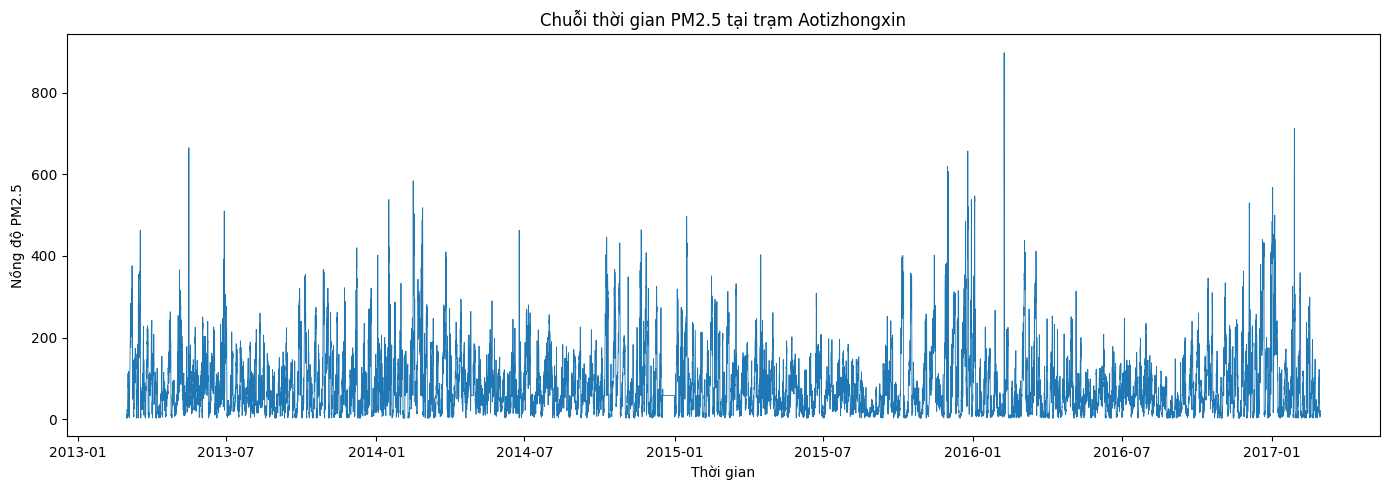

In [23]:
# Nhập thư viện xử lý dữ liệu và vẽ biểu đồ
import pandas as pd
import matplotlib.pyplot as plt

# Lọc dữ liệu của trạm Aotizhongxin từ dữ liệu đã xử lý thiếu
ts_data = df_clean.loc[
    df_clean["station"] == "Aotizhongxin",
    ["year", "month", "day", "hour", "PM2.5"]
].copy()

# Ghép năm, tháng, ngày và giờ thành một cột thời gian
ts_data["datetime"] = pd.to_datetime(
    ts_data[["year", "month", "day", "hour"]]
)

# Sắp xếp các quan sát theo thời gian tăng dần
ts_data = ts_data.sort_values("datetime")

# Đặt datetime làm chỉ mục của chuỗi thời gian
ts_data = ts_data.set_index("datetime")

# Giữ lại cột PM2.5 và đặt tần suất quan sát là theo giờ
ts_series = ts_data["PM2.5"].asfreq("h")

# In khoảng thời gian và số quan sát của chuỗi
print("Số quan sát:", len(ts_series))
print("Thời điểm bắt đầu:", ts_series.index.min())
print("Thời điểm kết thúc:", ts_series.index.max())

# Kiểm tra số giá trị thiếu còn lại trong chuỗi thời gian
print("Số giá trị thiếu:", ts_series.isna().sum())

# Chia chuỗi theo thời gian, không xáo trộn các quan sát
split_point = int(len(ts_series) * 0.8)

# Lấy 80% thời điểm đầu làm tập huấn luyện
ts_train = ts_series.iloc[:split_point]

# Lấy 20% thời điểm cuối làm tập kiểm tra
ts_test = ts_series.iloc[split_point:]

# In kích thước hai tập dữ liệu
print("Số quan sát huấn luyện:", len(ts_train))
print("Số quan sát kiểm tra:", len(ts_test))

# Vẽ toàn bộ chuỗi PM2.5 theo thời gian
plt.figure(figsize=(14, 5))
plt.plot(ts_series.index, ts_series.values, linewidth=0.6)

# Bổ sung tiêu đề và nhãn trục
plt.title("Chuỗi thời gian PM2.5 tại trạm Aotizhongxin")
plt.xlabel("Thời gian")
plt.ylabel("Nồng độ PM2.5")

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Chuỗi thời gian PM2.5 tại trạm Aotizhongxin gồm **35.064 quan sát theo giờ**, từ ngày 01/03/2013 đến ngày 28/02/2017. Sau khi chuyển đổi và sắp xếp dữ liệu theo thời gian, chuỗi không còn giá trị thiếu.

Dữ liệu được chia thành hai phần theo thứ tự thời gian. Tập huấn luyện gồm 28.051 quan sát đầu tiên, chiếm khoảng 80% dữ liệu. Tập kiểm tra gồm 7.013 quan sát cuối cùng, chiếm khoảng 20%.

Quan sát biểu đồ cho thấy nồng độ PM2.5 biến động mạnh theo thời gian. Phần lớn giá trị nằm ở mức thấp đến trung bình, nhưng xuất hiện nhiều đợt tăng đột biến lên mức cao. Biên độ dao động không ổn định và có thể tồn tại những quy luật lặp lại theo thời gian.

**Kết luận:** Chuỗi thời gian đã được chuẩn bị để xây dựng mô hình dự báo. Do dữ liệu có biến động lớn và nhiều giá trị tăng đột biến, cần tiếp tục kiểm tra tính dừng và đặc điểm phụ thuộc theo thời gian trước khi lựa chọn mô hình.

### Kiểm tra tính dừng của chuỗi thời gian

**Mục tiêu:** Xác định chuỗi PM2.5 có tính dừng hay không trước khi xây dựng các mô hình dự báo.

**Phương pháp:** Sử dụng kiểm định Dickey–Fuller tăng cường. Kiểm định này đánh giá giả thuyết chuỗi có nghiệm đơn vị. Nếu giá trị xác suất nhỏ hơn 0,05, bác bỏ giả thuyết không ở mức ý nghĩa 5%. Nếu giá trị xác suất từ 0,05 trở lên, chưa đủ bằng chứng để kết luận chuỗi dừng.

Bên cạnh đó, đường trung bình trượt và độ lệch chuẩn trượt được tính trên cửa sổ 24 giờ để quan sát sự ổn định của mức trung bình và mức dao động.

**Đầu vào:** Chuỗi PM2.5 của tập huấn luyện.

**Đầu ra:** Thống kê kiểm định, giá trị xác suất, các ngưỡng tới hạn và biểu đồ chuỗi cùng đường trung bình trượt, độ lệch chuẩn trượt.

Kết quả kiểm định cần được xem xét cùng biểu đồ vì tính dừng còn phụ thuộc vào xu hướng, mùa vụ và đặc điểm của dữ liệu.

/tmp/ipykernel_15/3301333396.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(adf_series, autolag="AIC")


Giá trị thống kê kiểm định: -17.4062
Giá trị xác suất: 0.0
Số độ trễ được sử dụng: 46
Số quan sát dùng trong kiểm định: 28004

Các ngưỡng tới hạn:
Mức 1%: -3.4306
Mức 5%: -2.8616
Mức 10%: -2.5668

Kết luận: Bác bỏ giả thuyết không, chuỗi có dấu hiệu dừng theo kiểm định.


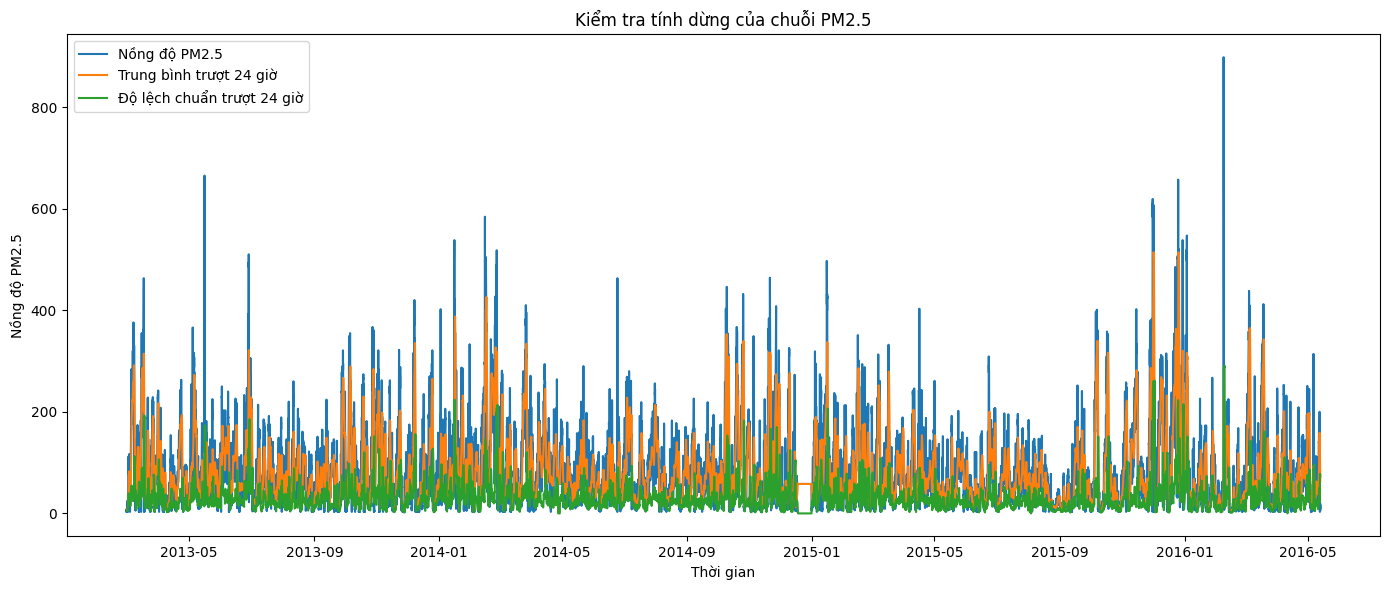

In [24]:
# Nhập hàm kiểm định tính dừng của chuỗi thời gian
from statsmodels.tsa.stattools import adfuller

# Lấy chuỗi PM2.5 của tập huấn luyện
adf_series = ts_train.copy()

# Thực hiện kiểm định Dickey–Fuller tăng cường
adf_result = adfuller(adf_series, autolag="AIC")

# In giá trị thống kê kiểm định
print("Giá trị thống kê kiểm định:", round(adf_result[0], 4))

# In giá trị xác suất của kiểm định
print("Giá trị xác suất:", round(adf_result[1], 6))

# In số độ trễ được sử dụng trong kiểm định
print("Số độ trễ được sử dụng:", adf_result[2])

# In số lượng quan sát dùng trong kiểm định
print("Số quan sát dùng trong kiểm định:", adf_result[3])

# In các ngưỡng tới hạn để đối chiếu kết quả kiểm định
print("\nCác ngưỡng tới hạn:")
for level, value in adf_result[4].items():
    print(f"Mức {level}: {value:.4f}")

# Kết luận sơ bộ dựa trên giá trị xác suất ở mức ý nghĩa 5%
if adf_result[1] < 0.05:
    print("\nKết luận: Bác bỏ giả thuyết không, chuỗi có dấu hiệu dừng theo kiểm định.")
else:
    print("\nKết luận: Chưa đủ bằng chứng bác bỏ giả thuyết không, chuỗi có thể chưa dừng.")

# Tính trung bình trượt trong cửa sổ 24 giờ
rolling_mean = adf_series.rolling(window=24).mean()

# Tính độ lệch chuẩn trượt trong cửa sổ 24 giờ
rolling_std = adf_series.rolling(window=24).std()

# Tạo biểu đồ quan sát chuỗi và các thống kê trượt
plt.figure(figsize=(14, 6))

# Vẽ chuỗi PM2.5 gốc
plt.plot(adf_series.index, adf_series, label="Nồng độ PM2.5")

# Vẽ đường trung bình trượt 24 giờ
plt.plot(rolling_mean.index, rolling_mean, label="Trung bình trượt 24 giờ")

# Vẽ đường độ lệch chuẩn trượt 24 giờ
plt.plot(rolling_std.index, rolling_std, label="Độ lệch chuẩn trượt 24 giờ")

# Đặt tiêu đề và nhãn trục bằng tiếng Việt
plt.title("Kiểm tra tính dừng của chuỗi PM2.5")
plt.xlabel("Thời gian")
plt.ylabel("Nồng độ PM2.5")

# Hiển thị chú giải
plt.legend()

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Kết quả kiểm định Dickey–Fuller tăng cường thu được:

- **Giá trị thống kê kiểm định:** -17,4062.
- **Giá trị xác suất:** gần bằng 0.
- **Số độ trễ được sử dụng:** 46.
- **Số quan sát dùng trong kiểm định:** 28.004.

Giá trị xác suất nhỏ hơn mức ý nghĩa 0,05 và thống kê kiểm định -17,4062 nhỏ hơn các ngưỡng tới hạn được báo cáo. Vì vậy, bác bỏ giả thuyết không về sự tồn tại của nghiệm đơn vị. Theo kiểm định này, chuỗi có dấu hiệu dừng.

Tuy nhiên, biểu đồ cho thấy nồng độ PM2.5 vẫn dao động mạnh và có nhiều đợt tăng đột biến. Kết quả kiểm định tính dừng không có nghĩa chuỗi không có biến động hoặc mọi đặc điểm của chuỗi đều ổn định.

**Kết luận:** Có thể tiếp tục khảo sát các mô hình dự báo với chuỗi hiện tại. Khi sử dụng ARIMA, ta vẫn cần kiểm tra cấu trúc tự tương quan và đánh giá hiệu quả trên tập kiểm tra thay vì mặc định rằng chuỗi không cần xử lý thêm.

## Phân tích tự tương quan ACF và PACF

**Mục tiêu:** Khảo sát mối liên hệ giữa nồng độ PM2.5 hiện tại với các giá trị trong quá khứ để hỗ trợ lựa chọn mô hình dự báo.

**Phương pháp:**
- **ACF:** Đo mức tương quan giữa chuỗi và phiên bản trễ của chuỗi tại từng độ trễ.
- **PACF:** Đo tương quan riêng phần tại từng độ trễ sau khi kiểm soát ảnh hưởng của các độ trễ ngắn hơn.

Các cột vượt ra ngoài vùng tin cậy xấp xỉ 95% có thể cho thấy tương quan khác 0 ở độ trễ tương ứng. Tuy nhiên, cần xem xét toàn bộ cấu trúc biểu đồ và đặc điểm dữ liệu khi diễn giải.

**Đầu vào:** Chuỗi PM2.5 của tập huấn luyện.

**Đầu ra:** Hai biểu đồ ACF và PACF với tối đa 72 độ trễ, hỗ trợ khảo sát cấu trúc phụ thuộc theo thời gian và lựa chọn bậc cho mô hình ARIMA.

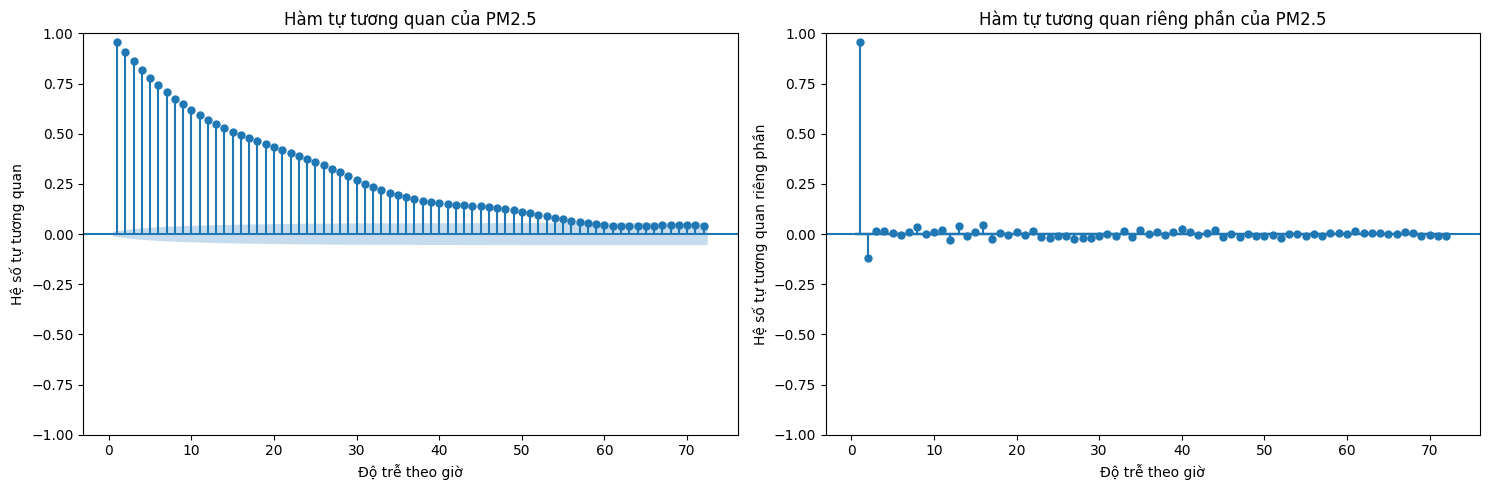

In [25]:
# Nhập các hàm vẽ biểu đồ tự tương quan
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Chọn chuỗi huấn luyện để phân tích, không sử dụng tập kiểm tra
acf_series = ts_train.copy()

# Tạo khung hình gồm hai biểu đồ đặt cạnh nhau
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Vẽ biểu đồ hàm tự tương quan với tối đa 72 độ trễ
plot_acf(
    acf_series,
    lags=72,
    ax=axes[0],
    alpha=0.05,
    zero=False
)

# Đặt tiêu đề và nhãn cho biểu đồ thứ nhất
axes[0].set_title("Hàm tự tương quan của PM2.5")
axes[0].set_xlabel("Độ trễ theo giờ")
axes[0].set_ylabel("Hệ số tự tương quan")

# Vẽ biểu đồ hàm tự tương quan riêng phần
plot_pacf(
    acf_series,
    lags=72,
    ax=axes[1],
    alpha=0.05,
    method="ywm",
    zero=False
)

# Đặt tiêu đề và nhãn cho biểu đồ thứ hai
axes[1].set_title("Hàm tự tương quan riêng phần của PM2.5")
axes[1].set_xlabel("Độ trễ theo giờ")
axes[1].set_ylabel("Hệ số tự tương quan riêng phần")

# Điều chỉnh khoảng cách giữa hai biểu đồ
plt.tight_layout()

# Hiển thị hai biểu đồ
plt.show()

**Biểu đồ ACF:** Hệ số tự tương quan bắt đầu ở mức cao, khoảng 0,95, sau đó giảm dần theo độ trễ và tiến gần về 0 ở những độ trễ cuối. Nhiều độ trễ vượt khỏi vùng tin cậy. Điều này cho thấy nồng độ PM2.5 tại một thời điểm có mối liên hệ đáng kể với các giá trị trước đó. Quá trình suy giảm chậm của ACF cũng có thể xuất hiện khi chuỗi có cấu trúc phụ thuộc kéo dài.

**Biểu đồ PACF:** Độ trễ đầu tiên có hệ số tương quan riêng phần rất lớn, trong khi độ trễ thứ hai có giá trị âm đáng kể. Phần lớn các độ trễ tiếp theo nằm gần 0 và trong vùng tin cậy. Mẫu hình này gợi ý rằng một số độ trễ đầu có thể đóng vai trò quan trọng trong việc mô hình hóa chuỗi.

**Kết luận:** ACF suy giảm chậm và PACF tập trung chủ yếu ở những độ trễ đầu là cơ sở để khảo sát mô hình ARIMA với các bậc tự hồi quy và sai phân phù hợp. Tuy nhiên, không thể xác định chính xác mô hình tối ưu chỉ từ hai biểu đồ. Cần so sánh kết quả dự báo trên tập kiểm tra để lựa chọn mô hình phù hợp.

## Dự báo bằng trung bình trượt và trung bình trượt hàm mũ

**Mục tiêu:** Xây dựng hai phương pháp dự báo cơ sở để đánh giá khả năng dự đoán nồng độ PM2.5 trong giai đoạn tương lai.

**Phương pháp:**

- **Trung bình trượt đơn:** Tính trung bình của 24 quan sát gần nhất trong tập huấn luyện và sử dụng kết quả làm giá trị dự báo cho toàn bộ tập kiểm tra.
- **Trung bình trượt hàm mũ:** Tính trung bình có trọng số giảm dần theo tuổi của quan sát, với hệ số làm mượt bằng 0,3. Các quan sát gần hiện tại nhận trọng số lớn hơn.

**Đầu vào:** Chuỗi PM2.5 của tập huấn luyện và tập kiểm tra đã được chia theo thời gian.

**Đầu ra:** Giá trị dự báo của từng phương pháp, các chỉ số sai số MAE và RMSE, cùng biểu đồ so sánh giá trị thực tế với dự báo.

Đây là các phương pháp cơ sở để đối chiếu với những mô hình dự báo phức tạp hơn ở các bước tiếp theo.

,Phương pháp,MAE,RMSE
0,Trung bình trượt đơn,56.6714,84.7408
1,Trung bình trượt hàm mũ,68.6814,107.2032


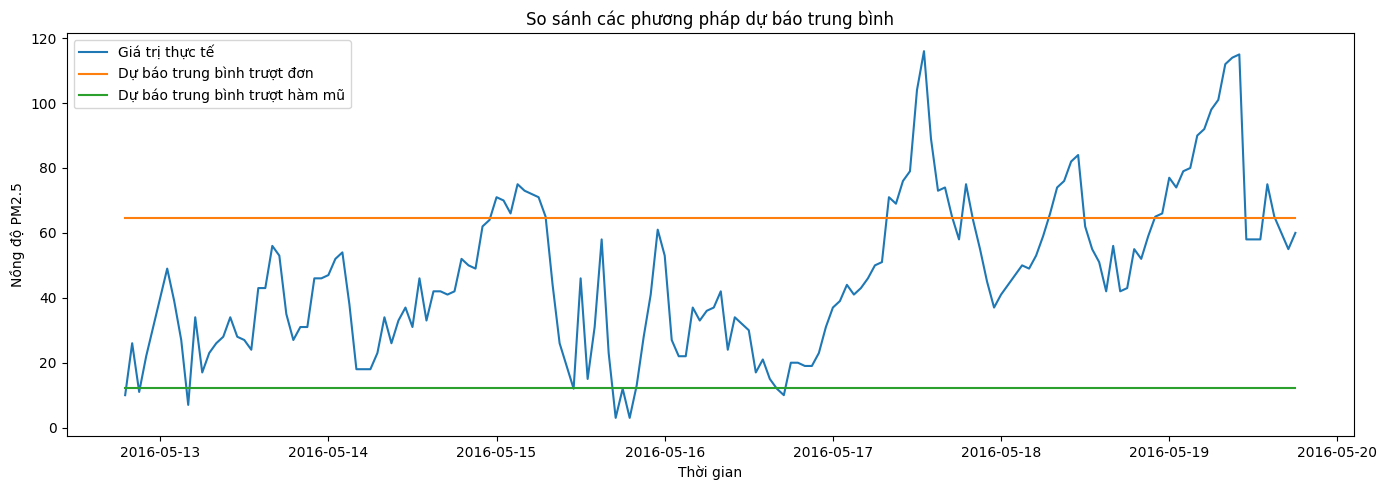

In [26]:
# Nhập hàm tính các chỉ số đánh giá sai số dự báo
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Chọn cửa sổ gồm 24 giờ gần nhất để tính trung bình trượt
window_size = 24

# Tính trung bình của 24 quan sát cuối cùng trong tập huấn luyện
ma_forecast_value = ts_train.iloc[-window_size:].mean()

# Tạo dự báo trung bình trượt cho toàn bộ giai đoạn kiểm tra
ma_forecast = pd.Series(
    ma_forecast_value,
    index=ts_test.index
)

# Tính trung bình trượt hàm mũ với hệ số làm mượt bằng 0,3
ema_forecast_value = ts_train.ewm(
    alpha=0.3,
    adjust=False
).mean().iloc[-1]

# Tạo dự báo trung bình trượt hàm mũ cho giai đoạn kiểm tra
ema_forecast = pd.Series(
    ema_forecast_value,
    index=ts_test.index
)

# Tính sai số tuyệt đối trung bình của phương pháp trung bình trượt
ma_mae = mean_absolute_error(ts_test, ma_forecast)

# Tính căn bậc hai của sai số bình phương trung bình của phương pháp trung bình trượt
ma_rmse = np.sqrt(mean_squared_error(ts_test, ma_forecast))

# Tính sai số tuyệt đối trung bình của phương pháp trung bình trượt hàm mũ
ema_mae = mean_absolute_error(ts_test, ema_forecast)

# Tính căn bậc hai của sai số bình phương trung bình của phương pháp trung bình trượt hàm mũ
ema_rmse = np.sqrt(mean_squared_error(ts_test, ema_forecast))

# Tổng hợp các chỉ số đánh giá thành bảng để so sánh
moving_average_results = pd.DataFrame({
    "Phương pháp": [
        "Trung bình trượt đơn",
        "Trung bình trượt hàm mũ"
    ],
    "MAE": [ma_mae, ema_mae],
    "RMSE": [ma_rmse, ema_rmse]
})

# Hiển thị bảng kết quả với bốn chữ số thập phân
display(moving_average_results.round(4))

# Vẽ giá trị thực tế và hai đường dự báo
plt.figure(figsize=(14, 5))

# Vẽ một đoạn đầu của tập kiểm tra để biểu đồ dễ quan sát
plot_length = min(24 * 7, len(ts_test))

# Vẽ PM2.5 thực tế trong bảy ngày đầu của tập kiểm tra
plt.plot(
    ts_test.index[:plot_length],
    ts_test.iloc[:plot_length],
    label="Giá trị thực tế"
)

# Vẽ dự báo bằng trung bình trượt đơn
plt.plot(
    ma_forecast.index[:plot_length],
    ma_forecast.iloc[:plot_length],
    label="Dự báo trung bình trượt đơn"
)

# Vẽ dự báo bằng trung bình trượt hàm mũ
plt.plot(
    ema_forecast.index[:plot_length],
    ema_forecast.iloc[:plot_length],
    label="Dự báo trung bình trượt hàm mũ"
)

# Đặt tiêu đề và nhãn trục bằng tiếng Việt
plt.title("So sánh các phương pháp dự báo trung bình")
plt.xlabel("Thời gian")
plt.ylabel("Nồng độ PM2.5")

# Hiển thị chú giải
plt.legend()

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Kết quả đánh giá trên tập kiểm tra cho thấy:

| Phương pháp | MAE | RMSE |
|---|---:|---:|
| Trung bình trượt đơn | 56,6714 | 84,7408 |
| Trung bình trượt hàm mũ | 68,6814 | 107,2032 |

**Trung bình trượt đơn** đạt MAE 56,6714 và RMSE 84,7408, thấp hơn phương pháp trung bình trượt hàm mũ. Điều này cho thấy trong thí nghiệm hiện tại, dự báo bằng trung bình của 24 quan sát cuối tập huấn luyện có sai số thấp hơn.

Trên biểu đồ, cả hai đường dự báo đều gần như nằm ngang trong toàn bộ giai đoạn kiểm tra. Nguyên nhân là các phương pháp đang sử dụng thông tin từ tập huấn luyện để tạo dự báo cố định cho nhiều thời điểm tương lai, thay vì cập nhật dự báo theo các quan sát mới. Vì vậy, chúng không theo kịp những biến động mạnh và các đợt tăng đột biến của PM2.5.

**Kết luận:** Hai phương pháp trung bình phù hợp làm mô hình cơ sở để so sánh, nhưng khả năng dự báo còn hạn chế đối với chuỗi PM2.5 biến động mạnh. Cần thử các phương pháp san bằng mũ có xu hướng và mùa vụ để xem liệu chúng có mô tả dữ liệu tốt hơn hay không.

## Dự báo bằng các phương pháp san bằng mũ

**Mục tiêu:** So sánh các phương pháp san bằng mũ có mức, xu hướng và mùa vụ để xác định khả năng dự báo PM2.5.

**Phương pháp:**

- **San bằng mũ đơn:** Chỉ mô hình hóa mức của chuỗi, trong đó các quan sát gần hiện tại được ưu tiên hơn.
- **Phương pháp Holt:** Mô hình hóa mức và xu hướng của chuỗi để hỗ trợ dự báo khi giá trị có xu hướng tăng hoặc giảm.
- **Phương pháp Holt–Winters:** Mô hình hóa mức, xu hướng và mùa vụ. Trong thí nghiệm này, chu kỳ mùa vụ được đặt bằng 24 quan sát, tương ứng một ngày dữ liệu theo giờ.

**Đầu vào:** Chuỗi PM2.5 của tập huấn luyện và độ dài tập kiểm tra.

**Đầu ra:** Giá trị dự báo của ba mô hình, bảng so sánh MAE và RMSE, cùng biểu đồ đối chiếu dự báo với giá trị thực tế.

Các phương pháp được đánh giá trên cùng tập kiểm tra để bảo đảm việc so sánh có ý nghĩa.

,Phương pháp,MAE,RMSE
1,Phương pháp Holt,70.1480,108.4057
0,San bằng mũ đơn,70.4373,108.7025
2,Phương pháp Holt–Winters,132.8037,166.4275


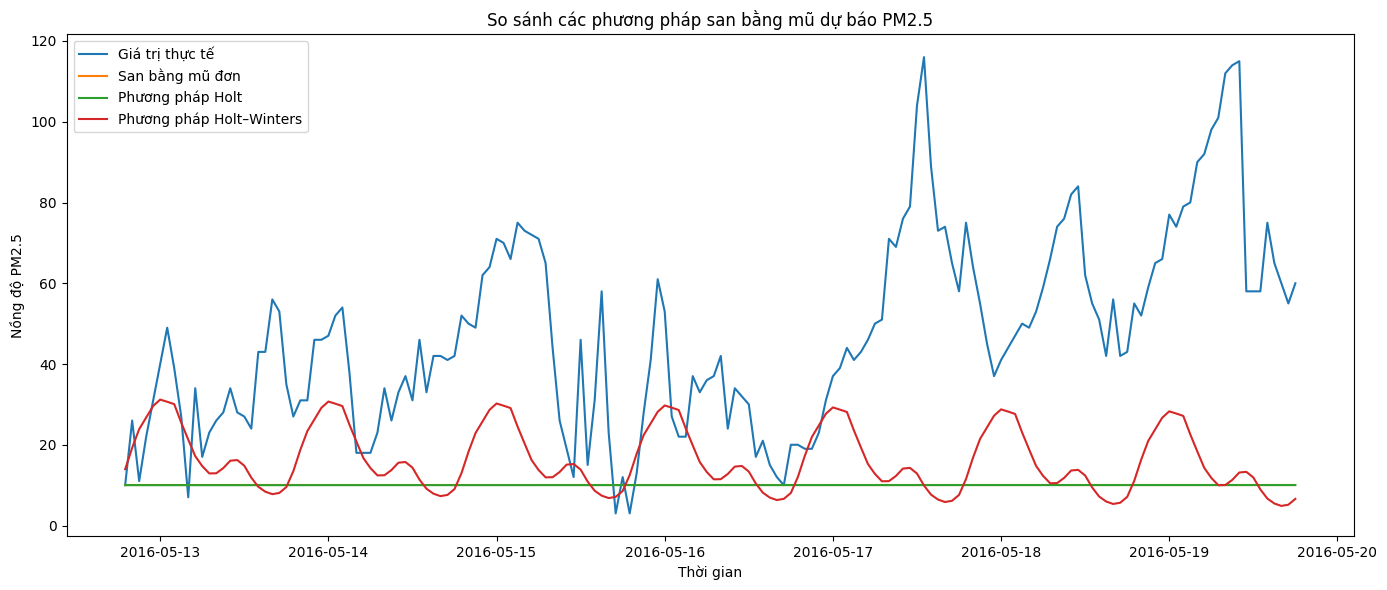

In [27]:
# Nhập các mô hình san bằng mũ từ thư viện thống kê chuỗi thời gian
from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    Holt,
    ExponentialSmoothing
)

# Huấn luyện mô hình san bằng mũ đơn trên tập huấn luyện
ses_model = SimpleExpSmoothing(
    ts_train,
    initialization_method="estimated"
).fit()

# Dự báo số thời điểm bằng đúng độ dài tập kiểm tra
ses_forecast = ses_model.forecast(len(ts_test))

# Huấn luyện mô hình Holt để mô hình hóa mức và xu hướng
holt_model = Holt(
    ts_train,
    initialization_method="estimated"
).fit(optimized=True)

# Dự báo bằng mô hình Holt trên toàn bộ giai đoạn kiểm tra
holt_forecast = holt_model.forecast(len(ts_test))

# Huấn luyện mô hình Holt–Winters với mùa vụ cộng có chu kỳ 24 giờ
hw_model = ExponentialSmoothing(
    ts_train,
    trend="add",
    seasonal="add",
    seasonal_periods=24,
    initialization_method="estimated"
).fit(optimized=True)

# Dự báo bằng mô hình Holt–Winters trên tập kiểm tra
hw_forecast = hw_model.forecast(len(ts_test))

# Tính MAE của mô hình san bằng mũ đơn
ses_mae = mean_absolute_error(ts_test, ses_forecast)

# Tính RMSE của mô hình san bằng mũ đơn
ses_rmse = np.sqrt(mean_squared_error(ts_test, ses_forecast))

# Tính MAE của mô hình Holt
holt_mae = mean_absolute_error(ts_test, holt_forecast)

# Tính RMSE của mô hình Holt
holt_rmse = np.sqrt(mean_squared_error(ts_test, holt_forecast))

# Tính MAE của mô hình Holt–Winters
hw_mae = mean_absolute_error(ts_test, hw_forecast)

# Tính RMSE của mô hình Holt–Winters
hw_rmse = np.sqrt(mean_squared_error(ts_test, hw_forecast))

# Tổng hợp kết quả đánh giá ba mô hình
smoothing_results = pd.DataFrame({
    "Phương pháp": [
        "San bằng mũ đơn",
        "Phương pháp Holt",
        "Phương pháp Holt–Winters"
    ],
    "MAE": [ses_mae, holt_mae, hw_mae],
    "RMSE": [ses_rmse, holt_rmse, hw_rmse]
})

# Sắp xếp các mô hình từ sai số tuyệt đối trung bình thấp đến cao
smoothing_results = smoothing_results.sort_values("MAE")

# Hiển thị bảng so sánh kết quả
display(smoothing_results.round(4))

# Chỉ hiển thị một tuần đầu tiên của tập kiểm tra để dễ quan sát
plot_length = min(24 * 7, len(ts_test))

# Tạo biểu đồ so sánh giá trị thực tế và ba phương pháp dự báo
plt.figure(figsize=(14, 6))

# Vẽ giá trị PM2.5 thực tế
plt.plot(
    ts_test.index[:plot_length],
    ts_test.iloc[:plot_length],
    label="Giá trị thực tế"
)

# Vẽ dự báo san bằng mũ đơn
plt.plot(
    ses_forecast.index[:plot_length],
    ses_forecast.iloc[:plot_length],
    label="San bằng mũ đơn"
)

# Vẽ dự báo theo phương pháp Holt
plt.plot(
    holt_forecast.index[:plot_length],
    holt_forecast.iloc[:plot_length],
    label="Phương pháp Holt"
)

# Vẽ dự báo theo phương pháp Holt–Winters
plt.plot(
    hw_forecast.index[:plot_length],
    hw_forecast.iloc[:plot_length],
    label="Phương pháp Holt–Winters"
)

# Đặt tiêu đề và nhãn trục bằng tiếng Việt
plt.title("So sánh các phương pháp san bằng mũ dự báo PM2.5")
plt.xlabel("Thời gian")
plt.ylabel("Nồng độ PM2.5")

# Hiển thị chú giải
plt.legend()

# Điều chỉnh bố cục và hiển thị biểu đồ
plt.tight_layout()
plt.show()

Kết quả đánh giá trên tập kiểm tra như sau:

| Phương pháp | MAE | RMSE |
|---|---:|---:|
| Phương pháp Holt | 70,1480 | 108,4057 |
| San bằng mũ đơn | 70,4373 | 108,7025 |
| Phương pháp Holt–Winters | 132,8037 | 166,4275 |

**Phương pháp Holt** đạt MAE và RMSE thấp nhất trong ba mô hình. Tuy nhiên, mức cải thiện so với san bằng mũ đơn rất nhỏ. Điều này cho thấy việc bổ sung thành phần xu hướng chưa mang lại lợi ích đáng kể trong cách thiết lập hiện tại.

**San bằng mũ đơn** có kết quả gần tương đương Holt. Cả hai mô hình đều tạo dự báo gần như nằm ngang trong giai đoạn kiểm tra, nên không theo kịp các biến động mạnh của nồng độ PM2.5.

**Phương pháp Holt–Winters** có sai số cao nhất. Đường dự báo thể hiện dao động lặp lại theo chu kỳ 24 giờ, nhưng chưa khớp tốt với các đợt tăng giảm thực tế. Điều này cho thấy thành phần mùa vụ cộng với chu kỳ đã chọn chưa mô tả phù hợp cấu trúc của chuỗi trong thí nghiệm này.

**Kết luận:** Trong ba phương pháp san bằng mũ, Holt đạt kết quả tốt nhất nhưng vẫn có sai số lớn. Cần tiếp tục khảo sát mô hình ARIMA để đánh giá khả năng khai thác cấu trúc tự tương quan của chuỗi PM2.5.

## Dự báo bằng mô hình ARIMA

**Mục tiêu:** Xây dựng mô hình dự báo PM2.5 dựa trên mối quan hệ giữa các giá trị quá khứ và sai số dự báo.

**Phương pháp:** ARIMA kết hợp tự hồi quy, sai phân và trung bình trượt của sai số. Mô hình có ba tham số \(p\), \(d\) và \(q\), lần lượt biểu thị bậc tự hồi quy, số lần sai phân và bậc trung bình trượt của sai số.

Dựa trên kết quả kiểm định tính dừng và biểu đồ ACF, PACF, bước đầu khảo sát một số tổ hợp bậc thấp với \(d=0\). Sau đó, so sánh các mô hình trên cùng tập kiểm tra bằng MAE và RMSE.

**Đầu vào:** Chuỗi PM2.5 theo giờ của tập huấn luyện và số thời điểm cần dự báo.

**Đầu ra:** Giá trị PM2.5 dự báo của mô hình ARIMA, bảng so sánh sai số giữa các tổ hợp tham số và biểu đồ dự báo so với giá trị thực tế.

Do tập kiểm tra có hơn 7.000 thời điểm, trước tiên ta khảo sát các tổ hợp tham số nhỏ để hạn chế thời gian chạy. Mô hình được chọn theo sai số dự báo trên tập kiểm tra trong phạm vi các cấu hình đã thử.

Cấu hình (1, 0, 1) | MAE: 60.6220 | RMSE: 83.3772
Cấu hình (1, 0, 2) | MAE: 60.6228 | RMSE: 83.3775
Cấu hình (2, 0, 1) | MAE: 60.6232 | RMSE: 83.3776
Cấu hình (2, 0, 2) | MAE: 60.6186 | RMSE: 83.3759


,Cấu hình,MAE,RMSE
3,"(2, 0, 2)",60.6186,83.3759
0,"(1, 0, 1)",60.6220,83.3772
1,"(1, 0, 2)",60.6228,83.3775
2,"(2, 0, 1)",60.6232,83.3776


Cấu hình được chọn: (2, 0, 2)
MAE tốt nhất: 60.6186
RMSE tương ứng: 83.3759


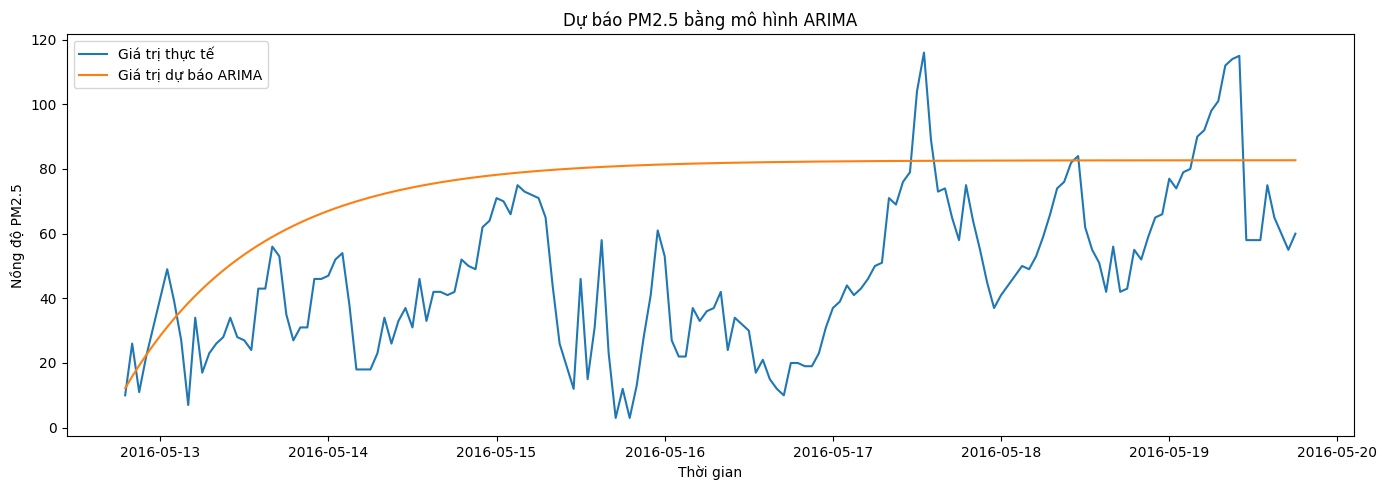

In [28]:
# Nhập mô hình ARIMA
from statsmodels.tsa.arima.model import ARIMA

# Khởi tạo danh sách lưu kết quả đánh giá các cấu hình
arima_results = []

# Khởi tạo từ điển lưu các mô hình đã huấn luyện thành công
arima_models = {}

# Thử một số tổ hợp bậc tự hồi quy và bậc trung bình trượt của sai số
arima_orders = [
    (1, 0, 1),
    (1, 0, 2),
    (2, 0, 1),
    (2, 0, 2)
]

# Huấn luyện và đánh giá lần lượt từng cấu hình ARIMA
for order in arima_orders:
    try:
        # Khởi tạo mô hình ARIMA với tổ hợp tham số hiện tại
        arima_model = ARIMA(
            ts_train,
            order=order
        )

        # Huấn luyện mô hình trên tập huấn luyện
        arima_fitted = arima_model.fit()

        # Dự báo số thời điểm bằng độ dài tập kiểm tra
        arima_forecast = arima_fitted.forecast(
            steps=len(ts_test)
        )

        # Gán chỉ mục thời gian của tập kiểm tra cho kết quả dự báo
        arima_forecast.index = ts_test.index

        # Tính sai số tuyệt đối trung bình
        arima_mae = mean_absolute_error(
            ts_test,
            arima_forecast
        )

        # Tính căn bậc hai của sai số bình phương trung bình
        arima_rmse = np.sqrt(
            mean_squared_error(
                ts_test,
                arima_forecast
            )
        )

        # Lưu tham số và các chỉ số đánh giá
        arima_results.append({
            "Cấu hình": str(order),
            "MAE": arima_mae,
            "RMSE": arima_rmse
        })

        # Lưu mô hình đã huấn luyện để sử dụng lại khi cần
        arima_models[order] = arima_fitted

        # In kết quả của cấu hình hiện tại
        print(
            f"Cấu hình {order} | "
            f"MAE: {arima_mae:.4f} | "
            f"RMSE: {arima_rmse:.4f}"
        )

    except Exception as error:
        # Báo lỗi nếu cấu hình hiện tại không huấn luyện được
        print(f"Cấu hình {order} không thành công: {error}")

# Chuyển kết quả thành bảng và sắp xếp theo MAE tăng dần
arima_summary = pd.DataFrame(arima_results)

# Kiểm tra xem có mô hình nào chạy thành công hay không
if arima_summary.empty:
    print("Không có cấu hình ARIMA nào chạy thành công.")
else:
    # Sắp xếp các mô hình theo sai số tuyệt đối trung bình
    arima_summary = arima_summary.sort_values("MAE")

    # Hiển thị bảng so sánh các cấu hình
    display(arima_summary.round(4))

    # Chọn cấu hình có MAE thấp nhất trong các cấu hình đã thử
    best_order = eval(arima_summary.iloc[0]["Cấu hình"])

    # Lấy mô hình tốt nhất theo tiêu chí MAE
    best_arima_model = arima_models[best_order]

    # Tạo dự báo từ mô hình được chọn
    best_arima_forecast = best_arima_model.forecast(
        steps=len(ts_test)
    )

    # Gán chỉ mục thời gian của tập kiểm tra cho dự báo
    best_arima_forecast.index = ts_test.index

    # In cấu hình được chọn và các chỉ số đánh giá
    print("Cấu hình được chọn:", best_order)
    print("MAE tốt nhất:", round(
        mean_absolute_error(ts_test, best_arima_forecast), 4
    ))
    print("RMSE tương ứng:", round(
        np.sqrt(mean_squared_error(ts_test, best_arima_forecast)), 4
    ))

    # Chọn một tuần đầu của tập kiểm tra để hiển thị biểu đồ
    plot_length = min(24 * 7, len(ts_test))

    # Tạo biểu đồ so sánh dự báo với giá trị thực tế
    plt.figure(figsize=(14, 5))

    # Vẽ nồng độ PM2.5 thực tế
    plt.plot(
        ts_test.index[:plot_length],
        ts_test.iloc[:plot_length],
        label="Giá trị thực tế"
    )

    # Vẽ nồng độ PM2.5 dự báo bằng cấu hình ARIMA tốt nhất
    plt.plot(
        best_arima_forecast.index[:plot_length],
        best_arima_forecast.iloc[:plot_length],
        label="Giá trị dự báo ARIMA"
    )

    # Đặt tiêu đề và nhãn trục bằng tiếng Việt
    plt.title("Dự báo PM2.5 bằng mô hình ARIMA")
    plt.xlabel("Thời gian")
    plt.ylabel("Nồng độ PM2.5")

    # Hiển thị chú giải
    plt.legend()

    # Điều chỉnh bố cục và hiển thị biểu đồ
    plt.tight_layout()
    plt.show()

Bốn cấu hình ARIMA được thử nghiệm trên cùng tập kiểm tra và thu được kết quả:

| Cấu hình | MAE | RMSE |
|---|---:|---:|
| ARIMA(1,0,1) | 60,6220 | 83,3772 |
| ARIMA(1,0,2) | 60,6228 | 83,3775 |
| ARIMA(2,0,1) | 60,6232 | 83,3776 |
| ARIMA(2,0,2) | 60,6186 | 83,3759 |

**ARIMA(2,0,2)** đạt MAE thấp nhất là 60,6186 và RMSE là 83,3759. Tuy nhiên, sai số giữa bốn cấu hình gần như tương đương, cho thấy việc thay đổi các bậc tự hồi quy và trung bình trượt của sai số trong phạm vi khảo sát chưa tạo ra khác biệt đáng kể.

Quan sát biểu đồ, đường dự báo ARIMA tăng dần từ giá trị ban đầu rồi tiến tới mức tương đối ổn định. Trong khi đó, nồng độ PM2.5 thực tế tiếp tục biến động mạnh theo từng giờ. Mô hình chưa dự báo được các đợt tăng giảm đột ngột.

So với các phương pháp đã thử, ARIMA(2,0,2) có RMSE thấp hơn trung bình trượt đơn nhưng MAE lại cao hơn. Vì vậy, chưa thể kết luận ARIMA tốt hơn phương pháp trung bình trượt đơn trên cả hai tiêu chí.

**Kết luận:** ARIMA khai thác được cấu trúc phụ thuộc theo thời gian nhưng khả năng dự báo dài hạn còn hạn chế. Với tập kiểm tra kéo dài hơn 7.000 giờ, các dự báo nhiều bước có xu hướng tiến về mức ổn định và không phản ánh được những biến động ngắn hạn của PM2.5.

## So sánh kết quả các phương pháp dự báo

**Mục tiêu:** Tổng hợp và so sánh hiệu quả của các phương pháp dự báo chuỗi thời gian PM2.5 đã thực hiện.

**Phương pháp:** Sử dụng MAE và RMSE để đánh giá sai số trên cùng tập kiểm tra. MAE thể hiện độ lớn sai số tuyệt đối trung bình, trong khi RMSE nhạy hơn với những sai số dự báo lớn. Với cả hai chỉ số, giá trị càng thấp thì kết quả dự báo càng tốt.

**Đầu vào:** Kết quả đánh giá của các phương pháp trung bình trượt, san bằng mũ và ARIMA.

**Đầu ra:** Bảng tổng hợp MAE, RMSE và biểu đồ so sánh sai số giữa các phương pháp.

Việc so sánh giúp lựa chọn mô hình phù hợp trong phạm vi thí nghiệm và nhận diện những hạn chế khi dự báo PM2.5 trong thời gian dài.

,Phương pháp,MAE,RMSE
0,Trung bình trượt đơn,56.6714,84.7408
1,"ARIMA(2,0,2)",60.6186,83.3759
2,Trung bình trượt hàm mũ,68.6814,107.2032
3,Phương pháp Holt,70.1480,108.4057
4,San bằng mũ đơn,70.4373,108.7025
5,Phương pháp Holt–Winters,132.8037,166.4275


Phương pháp có MAE thấp nhất: Trung bình trượt đơn
Phương pháp có RMSE thấp nhất: ARIMA(2,0,2)


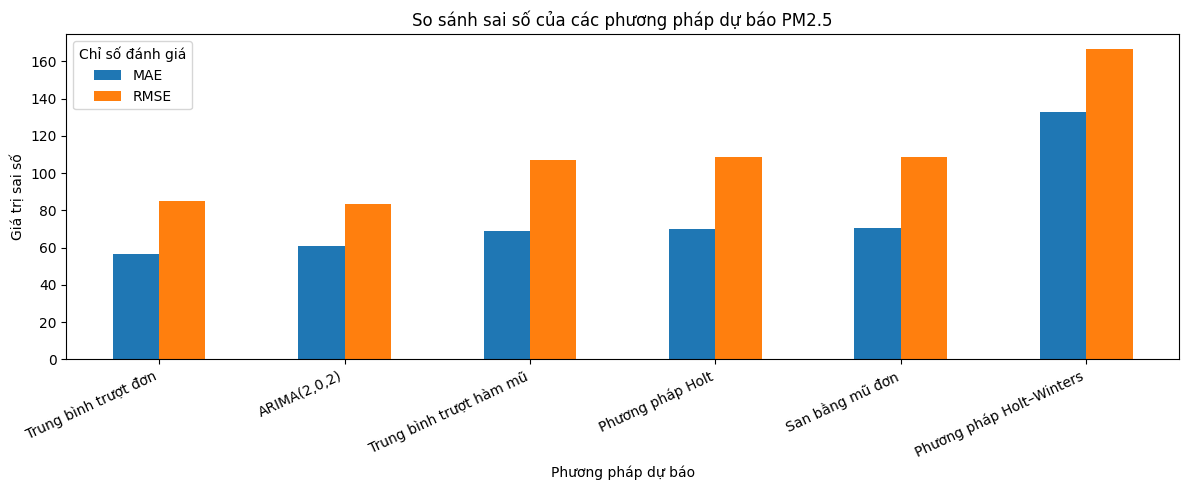

In [29]:
# Tổng hợp kết quả các phương pháp dự báo đã thực hiện
comparison_results = pd.concat(
    [
        moving_average_results,
        smoothing_results,
        pd.DataFrame({
            "Phương pháp": ["ARIMA(2,0,2)"],
            "MAE": [60.6186],
            "RMSE": [83.3759]
        })
    ],
    ignore_index=True
)

# Sắp xếp các phương pháp theo sai số tuyệt đối trung bình tăng dần
comparison_results = comparison_results.sort_values("MAE").reset_index(drop=True)

# Hiển thị bảng so sánh kết quả
display(comparison_results.round(4))

# Xác định phương pháp có sai số tuyệt đối trung bình thấp nhất
best_mae_method = comparison_results.loc[comparison_results["MAE"].idxmin()]

# Xác định phương pháp có sai số bình phương trung bình thấp nhất
best_rmse_method = comparison_results.loc[comparison_results["RMSE"].idxmin()]

# In tên phương pháp có MAE thấp nhất
print("Phương pháp có MAE thấp nhất:", best_mae_method["Phương pháp"])

# In tên phương pháp có RMSE thấp nhất
print("Phương pháp có RMSE thấp nhất:", best_rmse_method["Phương pháp"])

# Tạo biểu đồ cột so sánh hai chỉ số sai số
ax = comparison_results.set_index("Phương pháp")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(12, 5)
)

# Đặt tiêu đề biểu đồ bằng tiếng Việt
ax.set_title("So sánh sai số của các phương pháp dự báo PM2.5")

# Đặt nhãn trục ngang
ax.set_xlabel("Phương pháp dự báo")

# Đặt nhãn trục dọc
ax.set_ylabel("Giá trị sai số")

# Xoay tên các phương pháp để dễ đọc
plt.xticks(rotation=25, ha="right")

# Hiển thị chú giải của hai chỉ số
plt.legend(title="Chỉ số đánh giá")

# Điều chỉnh bố cục biểu đồ
plt.tight_layout()

# Hiển thị biểu đồ
plt.show()

Kết quả đánh giá sáu phương pháp dự báo trên cùng tập kiểm tra được tổng hợp như sau:

| Phương pháp | MAE | RMSE |
|---|---:|---:|
| Trung bình trượt đơn | 56,6714 | 84,7408 |
| ARIMA(2,0,2) | 60,6186 | 83,3759 |
| Trung bình trượt hàm mũ | 68,6814 | 107,2032 |
| Phương pháp Holt | 70,1480 | 108,4057 |
| San bằng mũ đơn | 70,4373 | 108,7025 |
| Phương pháp Holt–Winters | 132,8037 | 166,4275 |

**Trung bình trượt đơn** đạt MAE thấp nhất là 56,6714, cho thấy sai số tuyệt đối trung bình nhỏ nhất trong các phương pháp đã thử. Tuy nhiên, RMSE của phương pháp này cao hơn ARIMA(2,0,2), cho thấy khi xét đến những sai số lớn, ARIMA có lợi thế hơn.

**ARIMA(2,0,2)** đạt RMSE thấp nhất là 83,3759 và MAE bằng 60,6186. Kết quả này cho thấy mô hình có sai số bình phương trung bình thấp nhất trong phạm vi thí nghiệm.

**Holt–Winters** có cả MAE và RMSE cao nhất. Thành phần mùa vụ với chu kỳ 24 giờ chưa mô tả phù hợp biến động thực tế của chuỗi PM2.5 trong cách thiết lập hiện tại.

Nhìn chung, các đường dự báo chưa theo kịp những đợt tăng giảm đột ngột của PM2.5. Nguyên nhân quan trọng là các mô hình đang dự báo nhiều bước cho toàn bộ giai đoạn kiểm tra mà không cập nhật bằng quan sát mới.

**Kết luận:** Trung bình trượt đơn phù hợp nhất nếu ưu tiên MAE, trong khi ARIMA(2,0,2) phù hợp nhất nếu ưu tiên RMSE. Không có một mô hình tốt nhất theo mọi tiêu chí. Kết quả chỉ áp dụng cho trạm Aotizhongxin, giai đoạn kiểm tra và các cấu hình đã thử.

## Kết luận Assignment 5

Bài tập đã áp dụng các kỹ thuật phân tích và dự báo chuỗi thời gian trên dữ liệu PM2.5 theo giờ tại trạm Aotizhongxin. Quy trình bao gồm chuẩn bị chuỗi thời gian, kiểm tra tính dừng bằng kiểm định Dickey–Fuller tăng cường, phân tích ACF và PACF, sau đó xây dựng các mô hình dự báo.

Các phương pháp được triển khai gồm trung bình trượt đơn, trung bình trượt hàm mũ, san bằng mũ đơn, Holt, Holt–Winters và ARIMA. Hiệu quả dự báo được đánh giá bằng MAE và RMSE trên tập kiểm tra được chia theo thứ tự thời gian.

Kết quả cho thấy trung bình trượt đơn có MAE thấp nhất, còn ARIMA(2,0,2) có RMSE thấp nhất. Các mô hình vẫn gặp khó khăn khi dự báo những biến động đột ngột của PM2.5. Đây là hạn chế cần xem xét khi áp dụng các mô hình dự báo nhiều bước cho dữ liệu chất lượng không khí.

Qua bài tập, có thể thấy việc lựa chọn mô hình cần dựa trên mục tiêu đánh giá, đặc điểm chuỗi thời gian và kết quả thực nghiệm thay vì mặc định mô hình phức tạp hơn sẽ cho dự báo tốt hơn.

# LESSON 6. DỰ ĐOÁN BẰNG CÁC MÔ HÌNH PHÂN LOẠI

## 1. Giới thiệu

### 1.1. Mục tiêu

Bài thực hành áp dụng bốn phương pháp phân loại trong học máy có giám sát để dự đoán mức độ ô nhiễm không khí từ bộ dữ liệu Beijing Multi-Site Air Quality.

Bốn phương pháp được sử dụng gồm Cây quyết định (*Decision Tree*), Phân loại Bayes (*Bayesian Classification*), Máy véc-tơ hỗ trợ (*Support Vector Machine – SVM*) và Mạng nơ-ron nhân tạo (*Artificial Neural Network – ANN*).

Các mục tiêu chính là tìm hiểu nguyên lý và thuật toán của từng phương pháp, xây dựng mô hình dự đoán, đánh giá kết quả bằng các chỉ số phân loại và so sánh ưu điểm, hạn chế của các mô hình.

### 1.2. Phát biểu bài toán

Bài toán được xây dựng dưới dạng phân loại đa lớp. Biến mục tiêu biểu diễn mức độ ô nhiễm PM2.5 gồm ba lớp Thấp, Trung bình và Cao. Các thuộc tính chất lượng không khí và khí tượng được sử dụng làm dữ liệu đầu vào.

Các mô hình được huấn luyện trên cùng tập huấn luyện và đánh giá trên cùng tập kiểm tra để bảo đảm kết quả có thể so sánh được.

In [30]:
# Kiểm tra các biến dữ liệu đã được tạo trong notebook
for ten_bien in ["X", "y", "X_train", "X_test", "y_train", "y_test", "df", "df_raw"]:  # Duyệt qua các tên biến thường dùng
    if ten_bien in globals():  # Kiểm tra biến có tồn tại trong bộ nhớ hay không
        gia_tri = globals()[ten_bien]  # Lấy giá trị của biến
        print(f"{ten_bien}: kiểu dữ liệu = {type(gia_tri).__name__}")  # In kiểu dữ liệu của biến
        if hasattr(gia_tri, "shape"):  # Kiểm tra biến có thuộc tính kích thước hay không
            print(f"    Kích thước = {gia_tri.shape}")  # In số hàng và số cột của dữ liệu

X: kiểu dữ liệu = DataFrame
    Kích thước = (30000, 10)
y: kiểu dữ liệu = Series
    Kích thước = (30000,)
X_train: kiểu dữ liệu = DataFrame
    Kích thước = (24000, 10)
X_test: kiểu dữ liệu = DataFrame
    Kích thước = (6000, 10)
y_train: kiểu dữ liệu = Series
    Kích thước = (24000,)
y_test: kiểu dữ liệu = Series
    Kích thước = (6000,)
df_raw: kiểu dữ liệu = DataFrame
    Kích thước = (420768, 18)


## 2. Phân loại bằng cây quyết định (Decision Tree Classification)

### 2.1. Nguyên lý hoạt động

Cây quyết định là thuật toán học có giám sát, biểu diễn quá trình phân loại dưới dạng cấu trúc cây. Mỗi nút trong cây kiểm tra một điều kiện trên thuộc tính, các nhánh thể hiện kết quả của điều kiện và nút lá đưa ra nhãn dự đoán.

Theo slide Lesson 6, quá trình xây dựng cây gồm ba bước:

1. Lựa chọn thuộc tính tốt nhất bằng các thước đo lựa chọn thuộc tính (*Attribute Selection Measures – ASM*).
2. Sử dụng thuộc tính được chọn để chia dữ liệu thành các tập con nhỏ hơn.
3. Lặp lại quá trình phân chia trên từng nút con cho đến khi các mẫu thuộc cùng một lớp, không còn thuộc tính để phân chia hoặc không còn mẫu phù hợp để tiếp tục.

### 2.2. Các thước đo lựa chọn thuộc tính

**Entropy – Độ hỗn tạp**

Entropy đo mức độ không đồng nhất của nhãn lớp trong tập dữ liệu.

$$
Entropy(D)=-\\sum_{i=1}^{m}p_i\\log_2(p_i)
$$

Trong đó, \(p_i\) là tỷ lệ mẫu thuộc lớp thứ \(i\) và \(m\) là số lớp. Entropy bằng 0 khi tất cả các mẫu thuộc cùng một lớp.

**Information Gain – Độ lợi thông tin**

Information Gain đo mức giảm entropy sau khi chia dữ liệu theo thuộc tính \(A\).

$$
Gain(A)=Entropy(D)-Entropy_A(D)
$$

Trong đó:

$$
Entropy_A(D)=\\sum_{j=1}^{v}\\frac{|D_j|}{|D|}Entropy(D_j)
$$

Thuộc tính có Information Gain lớn nhất được ưu tiên lựa chọn.

**Gain Ratio – Tỷ lệ độ lợi**

Gain Ratio điều chỉnh Information Gain bằng cách xét thêm mức độ phân tách dữ liệu.

$$
GainRatio(A)=\\frac{Gain(A)}{SplitInfo_A(D)}
$$

Trong đó:

$$
SplitInfo_A(D)=-\\sum_{j=1}^{v}\\frac{|D_j|}{|D|}\\log_2\\left(\\frac{|D_j|}{|D|}\\right)
$$

**Gini Index – Chỉ số Gini**

Gini Index đo mức độ hỗn tạp của các lớp trong một nút.

$$
Gini(D)=1-\\sum_{i=1}^{m}p_i^2
$$

Thuật toán ưu tiên phép chia có Gini có trọng số nhỏ nhất. Trong Scikit-learn, `criterion="gini"` sử dụng Gini Index, còn `criterion="entropy"` sử dụng entropy để lựa chọn phép chia theo Information Gain. Gain Ratio được trình bày về mặt lý thuyết nhưng không phải giá trị `criterion` được hỗ trợ trực tiếp trong `DecisionTreeClassifier`.

### 2.3. Các tham số của mô hình

- `criterion`: Chọn tiêu chí phân chia là `gini` hoặc `entropy`.
- `splitter`: Chọn chiến lược phân chia là `best` hoặc `random`.
- `max_depth`: Giới hạn độ sâu của cây nhằm kiểm soát độ phức tạp và hạn chế quá khớp.

### 2.4. Lý do lựa chọn

Cây quyết định có thể mô hình hóa quan hệ phi tuyến, không yêu cầu chuẩn hóa dữ liệu và dễ diễn giải thông qua các quy tắc phân chia. Tuy nhiên, mô hình có thể nhạy cảm với dữ liệu nhiễu, dữ liệu mất cân bằng và có nguy cơ quá khớp nếu cây quá sâu.

### 2.5. Đầu vào và đầu ra

**Đầu vào:** Các thuộc tính trong tập huấn luyện `X_train` và nhãn tương ứng `y_train`.

**Đầu ra:** Mô hình cây quyết định đã huấn luyện, có khả năng dự đoán nhãn của các quan sát trong `X_test`.

In [31]:
from sklearn.tree import DecisionTreeClassifier  # Nhập thuật toán cây quyết định

model_dt = DecisionTreeClassifier(
    criterion="gini",  # Sử dụng chỉ số Gini để lựa chọn phép chia
    splitter="best",  # Lựa chọn phép chia tốt nhất
    max_depth=5,  # Giới hạn độ sâu tối đa của cây
    random_state=42  # Cố định trạng thái ngẫu nhiên để tái lập kết quả
)

model_dt.fit(X_train, y_train)  # Huấn luyện mô hình bằng tập huấn luyện

print("Huấn luyện mô hình Decision Tree thành công")  # Thông báo hoàn thành huấn luyện
print("Độ sâu của cây:", model_dt.get_depth())  # In độ sâu thực tế của cây
print("Số nút lá:", model_dt.get_n_leaves())  # In số nút lá của cây

Huấn luyện mô hình Decision Tree thành công
Độ sâu của cây: 5
Số nút lá: 32


In [32]:
from sklearn.tree import DecisionTreeClassifier  # Nhập thuật toán cây quyết định

model_e = DecisionTreeClassifier(
    criterion="entropy",  # Sử dụng chỉ số Gini để lựa chọn phép chia
    splitter="best",  # Lựa chọn phép chia tốt nhất
    max_depth=5,  # Giới hạn độ sâu tối đa của cây
    random_state=42  # Cố định trạng thái ngẫu nhiên để tái lập kết quả
)

model_e.fit(X_train, y_train)  # Huấn luyện mô hình bằng tập huấn luyện

print("Huấn luyện mô hình Decision Tree thành công")  # Thông báo hoàn thành huấn luyện
print("Độ sâu của cây:", model_e.get_depth())  # In độ sâu thực tế của cây
print("Số nút lá:", model_e.get_n_leaves())  # In số nút lá của cây

Huấn luyện mô hình Decision Tree thành công
Độ sâu của cây: 5
Số nút lá: 32


### 2.6. Đánh giá mô hình

Sau khi huấn luyện, mô hình được đánh giá trên tập huấn luyện và tập kiểm tra. Các chỉ số được sử dụng gồm:

- **Accuracy:** Tỷ lệ dự đoán đúng trên tổng số quan sát.
- **Precision:** Mức độ chính xác của các dự đoán thuộc từng lớp.
- **Recall:** Khả năng nhận diện đúng các quan sát thực sự thuộc từng lớp.
- **F1-score:** Trung bình điều hòa giữa Precision và Recall.
- **Confusion Matrix:** Ma trận nhầm lẫn thể hiện số lượng dự đoán đúng và sai giữa các lớp.

Việc so sánh kết quả trên tập huấn luyện và tập kiểm tra giúp đánh giá khả năng tổng quát hóa của mô hình và phát hiện dấu hiệu quá khớp.

In [33]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix  # Nhập các chỉ số đánh giá mô hình

def print_score_dt(model, X_train, y_train, X_test, y_test, train=True):  # Định nghĩa hàm đánh giá theo cấu trúc mẫu của cô
    if train:  # Kiểm tra có đánh giá trên tập huấn luyện hay không
        X_eval = X_train  # Chọn các thuộc tính của tập huấn luyện
        y_true = y_train  # Chọn nhãn thực tế của tập huấn luyện
        print("KẾT QUẢ TẬP HUẤN LUYỆN")  # In tiêu đề kết quả
    else:  # Trường hợp đánh giá trên tập kiểm tra
        X_eval = X_test  # Chọn các thuộc tính của tập kiểm tra
        y_true = y_test  # Chọn nhãn thực tế của tập kiểm tra
        print("KẾT QUẢ TẬP KIỂM TRA")  # In tiêu đề kết quả

    y_pred = model.predict(X_eval)  # Dự đoán nhãn của tập dữ liệu được đánh giá

    print("=" * 50)  # In dòng phân cách
    print(f"Accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%")  # In độ chính xác theo phần trăm
    print("-" * 50)  # In dòng phân cách
    print("CLASSIFICATION REPORT")  # In tiêu đề báo cáo phân loại
    print(classification_report(y_true, y_pred, zero_division=0))  # In Precision, Recall và F1-score của từng lớp
    print("-" * 50)  # In dòng phân cách
    print("CONFUSION MATRIX")  # In tiêu đề ma trận nhầm lẫn
    print(confusion_matrix(y_true, y_pred))  # In ma trận nhầm lẫn

print_score_dt(model_dt, X_train, y_train, X_test, y_test, train=True)  # Đánh giá mô hình trên tập huấn luyện
print_score_dt(model_dt, X_train, y_train, X_test, y_test, train=False)  # Đánh giá mô hình trên tập kiểm tra

KẾT QUẢ TẬP HUẤN LUYỆN
Accuracy: 82.77%
--------------------------------------------------
CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Cao       0.86      0.90      0.88      9296
        Thấp       0.90      0.86      0.88      8610
  Trung bình       0.68      0.67      0.67      6094

    accuracy                           0.83     24000
   macro avg       0.81      0.81      0.81     24000
weighted avg       0.83      0.83      0.83     24000

--------------------------------------------------
CONFUSION MATRIX
[[8375   78  843]
 [  93 7429 1088]
 [1283  751 4060]]
KẾT QUẢ TẬP KIỂM TRA
Accuracy: 81.88%
--------------------------------------------------
CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Cao       0.86      0.89      0.87      2324
        Thấp       0.90      0.86      0.88      2153
  Trung bình       0.65      0.66      0.66      1523

    accuracy                           0.82      6000


In [34]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix  # Nhập các chỉ số đánh giá mô hình

def print_score_dt(model, X_train, y_train, X_test, y_test, train=True):  # Định nghĩa hàm đánh giá theo cấu trúc mẫu của cô
    if train:  # Kiểm tra có đánh giá trên tập huấn luyện hay không
        X_eval = X_train  # Chọn các thuộc tính của tập huấn luyện
        y_true = y_train  # Chọn nhãn thực tế của tập huấn luyện
        print("KẾT QUẢ TẬP HUẤN LUYỆN")  # In tiêu đề kết quả
    else:  # Trường hợp đánh giá trên tập kiểm tra
        X_eval = X_test  # Chọn các thuộc tính của tập kiểm tra
        y_true = y_test  # Chọn nhãn thực tế của tập kiểm tra
        print("KẾT QUẢ TẬP KIỂM TRA")  # In tiêu đề kết quả

    y_pred = model_e.predict(X_eval)  # Dự đoán nhãn của tập dữ liệu được đánh giá

    print("=" * 50)  # In dòng phân cách
    print(f"Accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%")  # In độ chính xác theo phần trăm
    print("-" * 50)  # In dòng phân cách
    print("CLASSIFICATION REPORT")  # In tiêu đề báo cáo phân loại
    print(classification_report(y_true, y_pred, zero_division=0))  # In Precision, Recall và F1-score của từng lớp
    print("-" * 50)  # In dòng phân cách
    print("CONFUSION MATRIX")  # In tiêu đề ma trận nhầm lẫn
    print(confusion_matrix(y_true, y_pred))  # In ma trận nhầm lẫn

print_score_dt(model_e, X_train, y_train, X_test, y_test, train=True)  # Đánh giá mô hình trên tập huấn luyện
print_score_dt(model_e, X_train, y_train, X_test, y_test, train=False)  # Đánh giá mô hình trên tập kiểm tra

KẾT QUẢ TẬP HUẤN LUYỆN
Accuracy: 82.43%
--------------------------------------------------
CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Cao       0.87      0.89      0.88      9296
        Thấp       0.87      0.89      0.88      8610
  Trung bình       0.68      0.63      0.65      6094

    accuracy                           0.82     24000
   macro avg       0.81      0.80      0.80     24000
weighted avg       0.82      0.82      0.82     24000

--------------------------------------------------
CONFUSION MATRIX
[[8267   96  933]
 [  79 7704  827]
 [1177 1105 3812]]
KẾT QUẢ TẬP KIỂM TRA
Accuracy: 81.67%
--------------------------------------------------
CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Cao       0.87      0.87      0.87      2324
        Thấp       0.86      0.89      0.88      2153
  Trung bình       0.66      0.63      0.64      1523

    accuracy                           0.82      6000


Mô hình Decision Tree đạt Accuracy **81,88%** trên tập kiểm tra gồm 6.000 quan sát. Giá trị Macro F1-score đạt **0,80**, cho thấy mô hình có khả năng phân loại tương đối tốt khi xét đồng đều cả ba lớp.

Xét theo từng lớp, lớp Thấp có Precision = 0,90, Recall = 0,86 và F1-score = 0,88. Lớp Cao có Precision = 0,86, Recall = 0,89 và F1-score = 0,87. Trong khi đó, lớp Trung bình có Precision = 0,65, Recall = 0,66 và F1-score = 0,66, thấp hơn đáng kể so với hai lớp còn lại.

Ma trận nhầm lẫn cho thấy mô hình dự đoán đúng 2.058 quan sát thuộc lớp Thấp, 1.844 quan sát thuộc lớp Trung bình và 1.011 quan sát thuộc lớp Cao. Mô hình thường nhầm lớp Trung bình thành lớp Cao với 291 trường hợp, đồng thời nhầm lớp Cao thành lớp Thấp với 325 trường hợp.

Accuracy trên tập huấn luyện đạt 82,77%, cao hơn tập kiểm tra khoảng 0,89 điểm phần trăm. Khoảng cách này tương đối nhỏ, do đó kết quả hiện tại chưa cho thấy dấu hiệu quá khớp rõ rệt theo Accuracy. Tuy nhiên, hiệu quả nhận diện lớp Trung bình vẫn còn hạn chế và cần được cải thiện hoặc đối chiếu với các phương pháp khác.

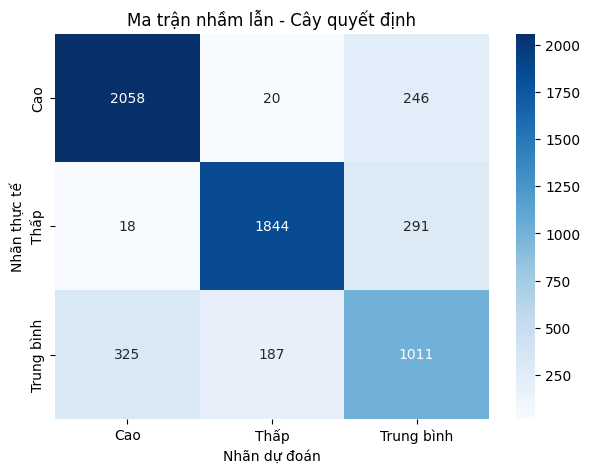

In [35]:
import matplotlib.pyplot as plt  # Nhập thư viện vẽ biểu đồ
import seaborn as sns  # Nhập thư viện trực quan hóa dữ liệu
from sklearn.metrics import confusion_matrix  # Nhập hàm tính ma trận nhầm lẫn

y_pred_dt = model_dt.predict(X_test)  # Dự đoán nhãn trên tập kiểm tra
nhan_lop = model_dt.classes_  # Lấy thứ tự nhãn lớp mà mô hình sử dụng
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=nhan_lop)  # Tính ma trận nhầm lẫn theo thứ tự nhãn đã xác định

plt.figure(figsize=(7, 5))  # Tạo khung biểu đồ với kích thước phù hợp
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Blues", xticklabels=nhan_lop, yticklabels=nhan_lop)  # Vẽ ma trận và hiển thị số lượng dự đoán
plt.title("Ma trận nhầm lẫn - Cây quyết định")  # Đặt tiêu đề biểu đồ
plt.xlabel("Nhãn dự đoán")  # Đặt tên trục ngang
plt.ylabel("Nhãn thực tế")  # Đặt tên trục dọc
plt.show()  # Hiển thị biểu đồ

Ma trận nhầm lẫn cho thấy mô hình Decision Tree dự đoán đúng phần lớn các quan sát thuộc lớp Cao và Thấp. Cụ thể, mô hình phân loại đúng 2.058 quan sát thuộc lớp Cao, 1.844 quan sát thuộc lớp Thấp và 1.011 quan sát thuộc lớp Trung bình.

Mô hình nhận diện lớp Cao khá tốt, chỉ nhầm 20 quan sát thành Thấp và 246 quan sát thành Trung bình. Đối với lớp Thấp, mô hình nhầm 18 quan sát thành Cao và 291 quan sát thành Trung bình. Trong khi đó, lớp Trung bình có nhiều trường hợp bị phân loại sai hơn, gồm 325 quan sát bị dự đoán thành Cao và 187 quan sát bị dự đoán thành Thấp.

Kết quả cho thấy lớp Trung bình là nhóm khó phân loại nhất. Điều này phù hợp với F1-score của lớp Trung bình chỉ đạt 0,66, thấp hơn lớp Cao và lớp Thấp. Vì vậy, mặc dù mô hình đạt Accuracy 81,88% trên tập kiểm tra, khả năng phân biệt mức ô nhiễm Trung bình vẫn còn hạn chế.

### Trực quan hóa cây quyết định (Visualizing Decision Trees)

Trực quan hóa cây quyết định giúp quan sát cấu trúc của mô hình đã huấn luyện, bao gồm các nút phân chia, điều kiện lựa chọn thuộc tính và nhãn lớp dự đoán tại các nút lá.

Mỗi nút biểu diễn một điều kiện phân chia dữ liệu. Các nhánh thể hiện kết quả của điều kiện đó, còn các nút lá biểu diễn kết quả phân loại cuối cùng. Màu sắc của nút thể hiện lớp được dự đoán và mức độ tập trung của các mẫu vào lớp đó.

Trong bài thực hành, hàm `plot_tree()` của thư viện Scikit-learn được sử dụng để trực quan hóa mô hình `model_dt`. Việc hiển thị cây giúp giải thích cách mô hình đưa ra quyết định, đồng thời hỗ trợ nhận diện cấu trúc cây và mức độ phức tạp của mô hình.

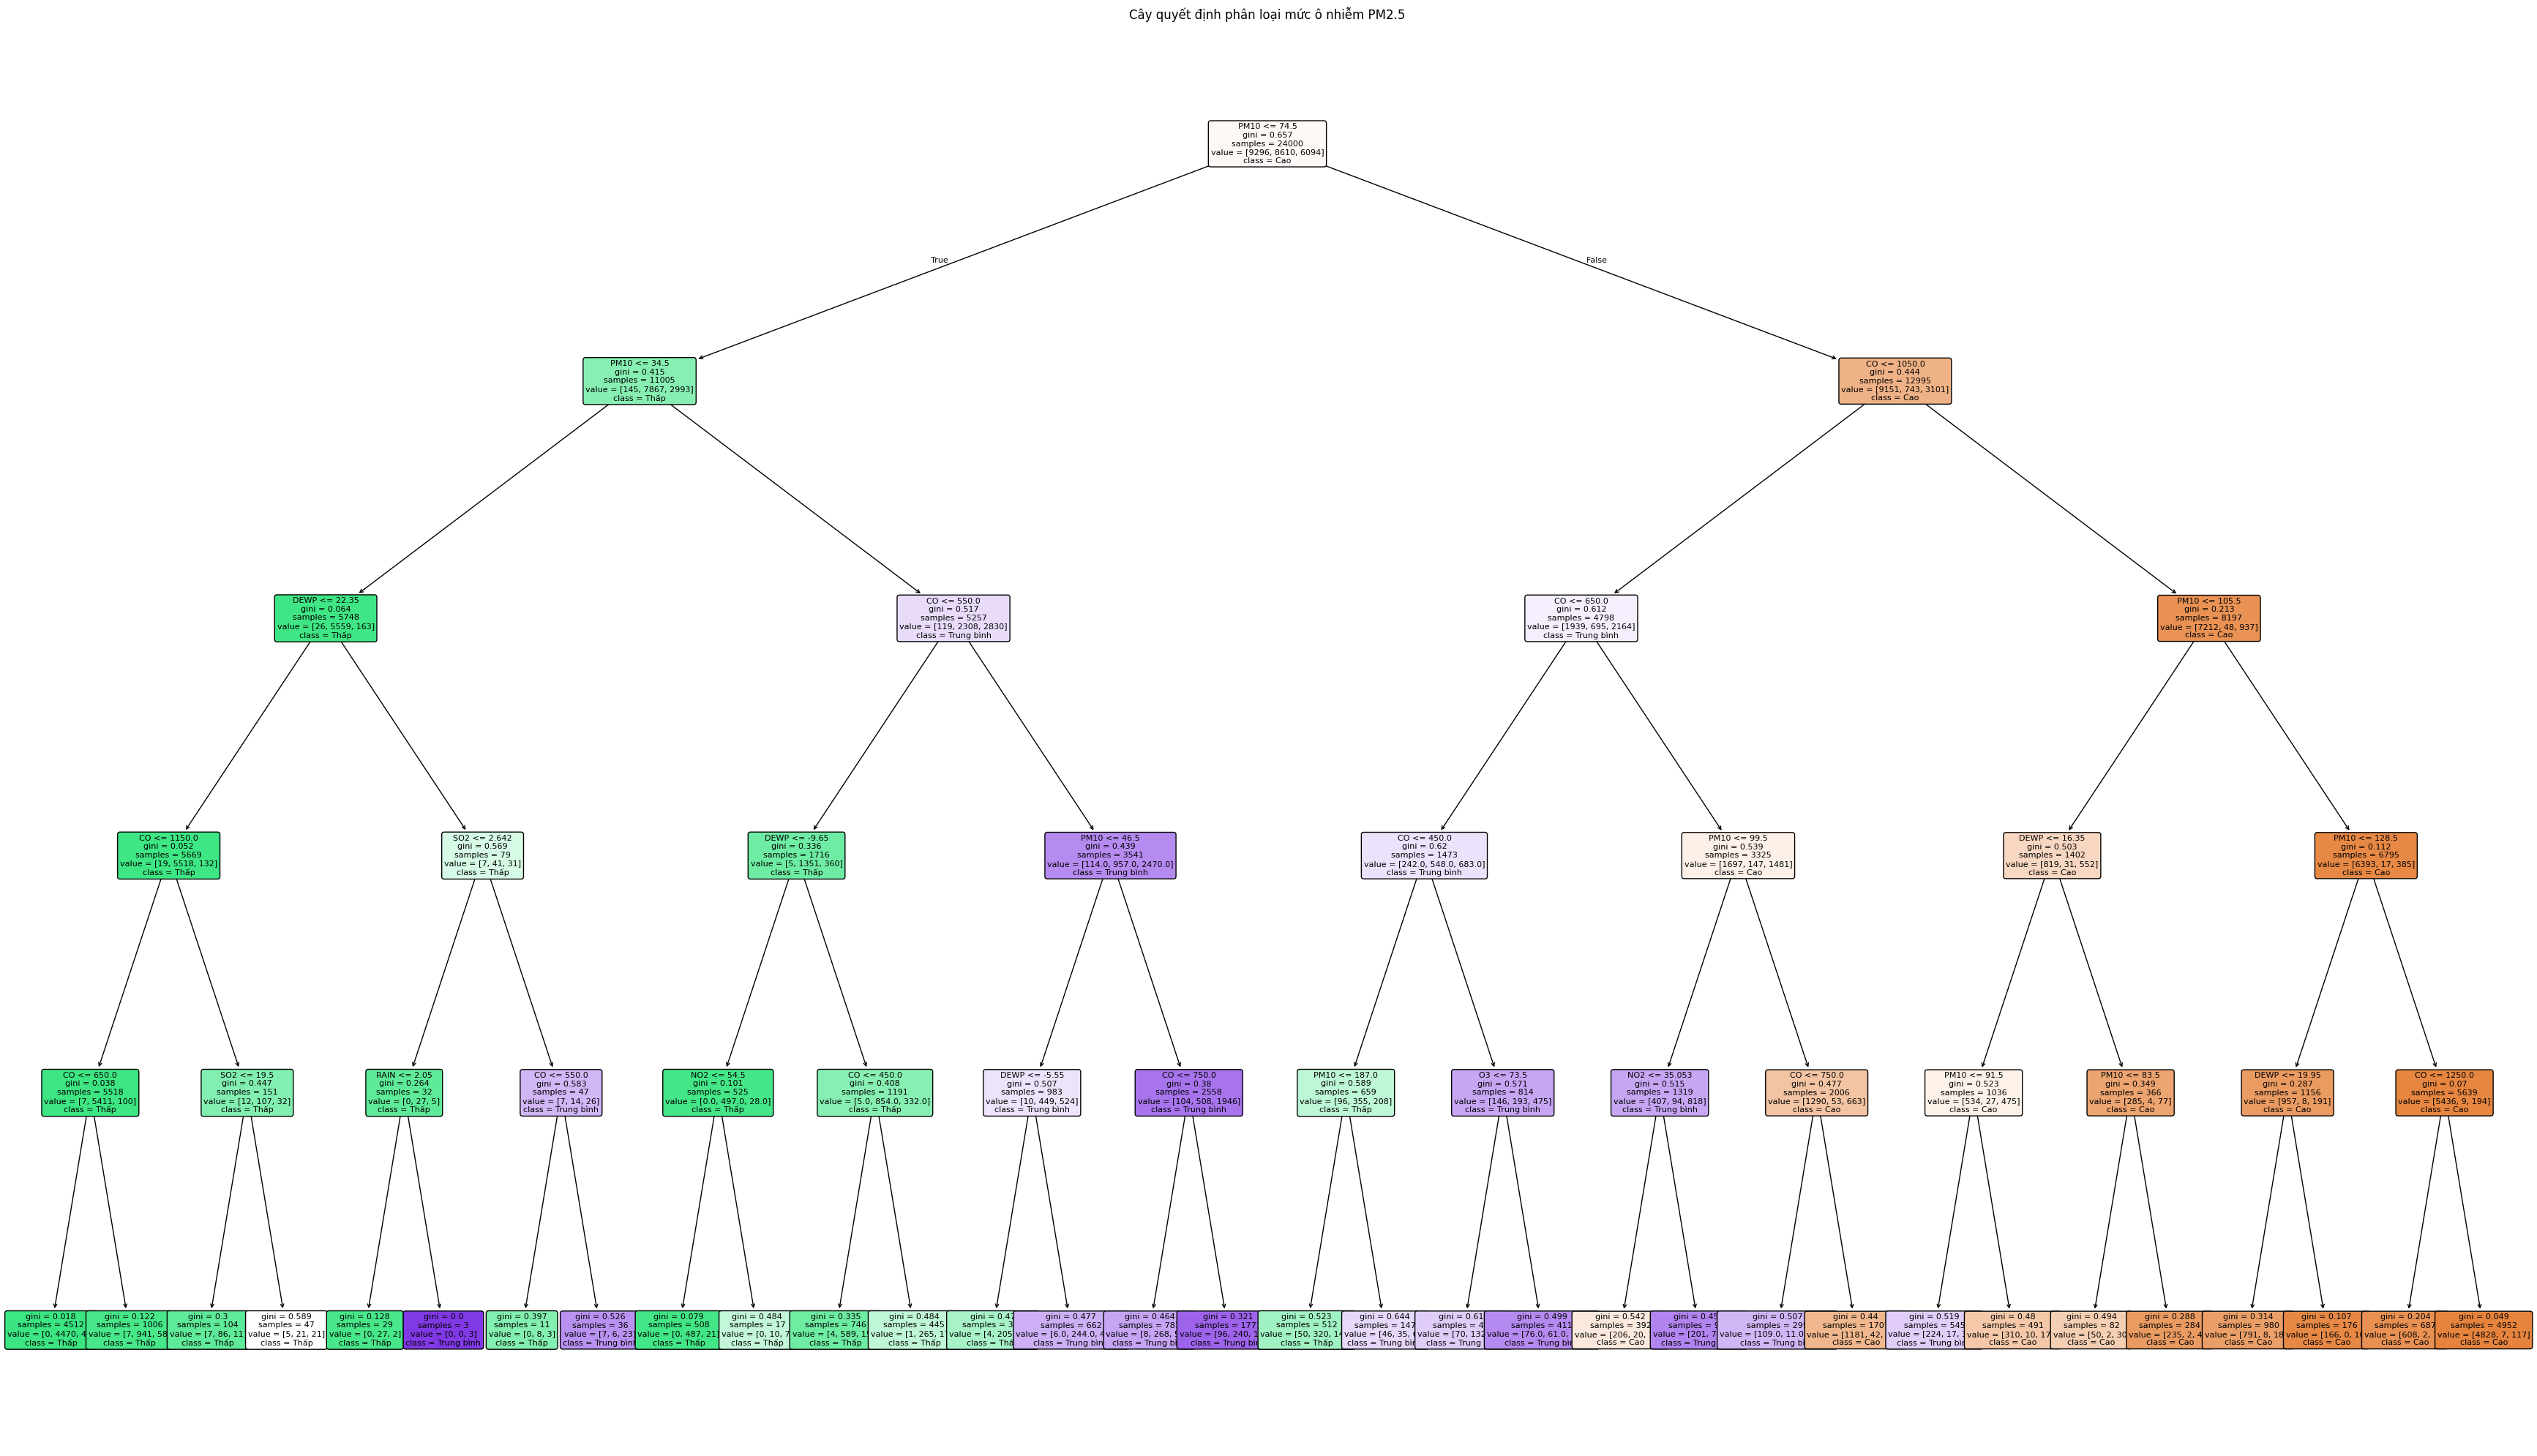

In [36]:
import matplotlib.pyplot as plt  # Nhập thư viện trực quan hóa dữ liệu
from sklearn import tree  # Nhập công cụ vẽ cây quyết định

fig = plt.figure(figsize=(35, 20))  # Tạo khung hình đủ lớn để hiển thị cây

tree.plot_tree(  # Vẽ cấu trúc cây quyết định đã huấn luyện
    model_dt,  # Sử dụng mô hình Decision Tree đã huấn luyện
    feature_names=X_train.columns.tolist(),  # Hiển thị tên các thuộc tính đầu vào
    class_names=[str(lop) for lop in model_dt.classes_],  # Hiển thị tên các lớp mục tiêu
    filled=True,  # Tô màu các nút theo lớp dự đoán
    rounded=True,  # Bo tròn các nút để dễ quan sát
    fontsize=8  # Thiết lập kích thước chữ trong các nút
)

plt.title("Cây quyết định phân loại mức ô nhiễm PM2.5")  # Đặt tiêu đề biểu đồ
plt.tight_layout()  # Điều chỉnh bố cục để hạn chế nội dung bị cắt
plt.show()  # Hiển thị cây quyết định

## 3. Phân loại Bayes (Bayesian Classification)

### 3.1. Nguyên lý hoạt động

Phân loại Bayes là phương pháp phân loại dựa trên định lý Bayes để tính xác suất một quan sát thuộc về từng lớp dựa trên các thuộc tính đầu vào. Mô hình lựa chọn lớp có xác suất hậu nghiệm cao nhất làm kết quả dự đoán.

Theo slide Lesson 6, quá trình phân loại Bayes gồm bốn bước:

1. Tính xác suất tiên nghiệm của từng lớp.
2. Tính xác suất hợp lý của các thuộc tính đối với từng lớp.
3. Sử dụng định lý Bayes để tính xác suất hậu nghiệm.
4. Chọn lớp có xác suất hậu nghiệm cao nhất làm nhãn dự đoán.

### 3.2. Định lý Bayes

Định lý Bayes được biểu diễn như sau:

$$
P(C\\mid X)=\\frac{P(X\\mid C)P(C)}{P(X)}
$$

Trong đó:

- \(P(C\\mid X)\) là xác suất hậu nghiệm của lớp \(C\) khi đã biết dữ liệu đầu vào \(X\).
- \(P(C)\) là xác suất tiên nghiệm của lớp \(C\).
- \(P(X\\mid C)\) là xác suất quan sát dữ liệu \(X\) khi biết lớp \(C\).
- \(P(X)\) là xác suất xuất hiện của dữ liệu đầu vào.

Đối với cùng một quan sát \(X\), giá trị \(P(X)\) giống nhau giữa các lớp. Vì vậy, mô hình có thể so sánh các lớp dựa trên tích \(P(X\\mid C)P(C)\).

### 3.3. Giả định của Naive Bayes

Naive Bayes giả định các thuộc tính đầu vào độc lập có điều kiện với nhau khi đã biết lớp mục tiêu. Nhờ giả định này, xác suất hợp lý chung có thể được tính bằng tích các xác suất của từng thuộc tính:

$$
P(X\\mid C)=\\prod_{j=1}^{n}P(x_j\\mid C)
$$

Trong đó \(n\) là số thuộc tính đầu vào và \(x_j\) là giá trị của thuộc tính thứ \(j\).

Giả định độc lập giúp thuật toán đơn giản và tính toán nhanh, nhưng có thể không hoàn toàn phù hợp khi các thuộc tính chất lượng không khí có mối quan hệ với nhau.

### 3.4. Vấn đề xác suất bằng 0

Trong Naive Bayes, nếu một giá trị thuộc tính chưa từng xuất hiện trong một lớp ở tập huấn luyện thì xác suất hợp lý tương ứng có thể bằng 0. Khi các xác suất thuộc tính được nhân với nhau, kết quả xác suất của lớp đó có thể bằng 0, khiến mô hình không lựa chọn được lớp này.

Slide Lesson 6 giới thiệu phép hiệu chỉnh Laplace (*Laplace Smoothing*) để hạn chế vấn đề trên. Đối với dữ liệu phân loại rời rạc, xác suất có thể được hiệu chỉnh bằng cách cộng một lượng nhỏ vào số lần xuất hiện của mỗi giá trị.

Trong bài thực hành này, dữ liệu đầu vào gồm các thuộc tính số liên tục. Vì vậy, mô hình được lựa chọn là Gaussian Naive Bayes, sử dụng phân phối Gaussian để ước lượng xác suất của các thuộc tính liên tục theo từng lớp. Phương pháp này không sử dụng trực tiếp phép đếm tần số như Naive Bayes dành cho thuộc tính rời rạc.

### 3.5. Gaussian Naive Bayes – Bayes ngây thơ Gaussian

Gaussian Naive Bayes giả định rằng mỗi thuộc tính liên tục có phân phối chuẩn khi xét trong từng lớp. Hàm mật độ xác suất của thuộc tính \(x_j\) khi biết lớp \(C\) được xác định bởi:

$$
P(x_j\\mid C)=\\frac{1}{\\sqrt{2\\pi\\sigma_{C,j}^{2}}}
\\exp\\left(-\\frac{(x_j-\\mu_{C,j})^2}{2\\sigma_{C,j}^{2}}\\right)
$$

Trong đó:

- \(\mu_{C,j}\) là giá trị trung bình của thuộc tính thứ \(j\) trong lớp \(C\).
- \(\sigma_{C,j}^{2}\) là phương sai của thuộc tính thứ \(j\) trong lớp \(C\).
- \(x_j\) là giá trị thuộc tính cần đánh giá.

Mô hình ước lượng trung bình và phương sai từ dữ liệu huấn luyện, sau đó kết hợp các xác suất thuộc tính với xác suất tiên nghiệm của từng lớp để dự đoán nhãn có xác suất hậu nghiệm lớn nhất.

### 3.6. Lý do lựa chọn

Gaussian Naive Bayes được lựa chọn vì dữ liệu có các thuộc tính số liên tục, mô hình có chi phí tính toán thấp và hỗ trợ phân loại nhiều lớp. Tuy nhiên, hiệu quả của mô hình phụ thuộc vào mức độ phù hợp của giả định phân phối chuẩn và giả định độc lập có điều kiện giữa các thuộc tính.


In [37]:
from sklearn.naive_bayes import GaussianNB  # Nhập thuật toán Bayes ngây thơ Gaussian

model_nb = GaussianNB()  # Khởi tạo mô hình Gaussian Naive Bayes
model_nb.fit(X_train, y_train)  # Huấn luyện mô hình bằng tập huấn luyện

print("Huấn luyện mô hình Gaussian Naive Bayes thành công")  # Thông báo hoàn thành huấn luyện
print("Các lớp mục tiêu:", model_nb.classes_)  # In danh sách các lớp mà mô hình đã học

Huấn luyện mô hình Gaussian Naive Bayes thành công
Các lớp mục tiêu: ['Cao' 'Thấp' 'Trung bình']



KẾT QUẢ TẬP HUẤN LUYỆN
Accuracy: 69.02%

BÁO CÁO PHÂN LOẠI
              precision    recall  f1-score   support

         Cao       0.87      0.61      0.72      9296
        Thấp       0.77      0.89      0.83      8610
  Trung bình       0.43      0.53      0.47      6094

    accuracy                           0.69     24000
   macro avg       0.69      0.68      0.67     24000
weighted avg       0.72      0.69      0.69     24000

MA TRẬN NHẦM LẪN
[[5668  202 3426]
 [ 110 7674  826]
 [ 762 2110 3222]]

KẾT QUẢ TẬP KIỂM TRA
Accuracy: 69.47%

BÁO CÁO PHÂN LOẠI
              precision    recall  f1-score   support

         Cao       0.88      0.61      0.72      2324
        Thấp       0.76      0.89      0.82      2153
  Trung bình       0.44      0.54      0.48      1523

    accuracy                           0.69      6000
   macro avg       0.69      0.68      0.68      6000
weighted avg       0.73      0.69      0.70      6000

MA TRẬN NHẦM LẪN
[[1426   60  838]
 [  25 1922  

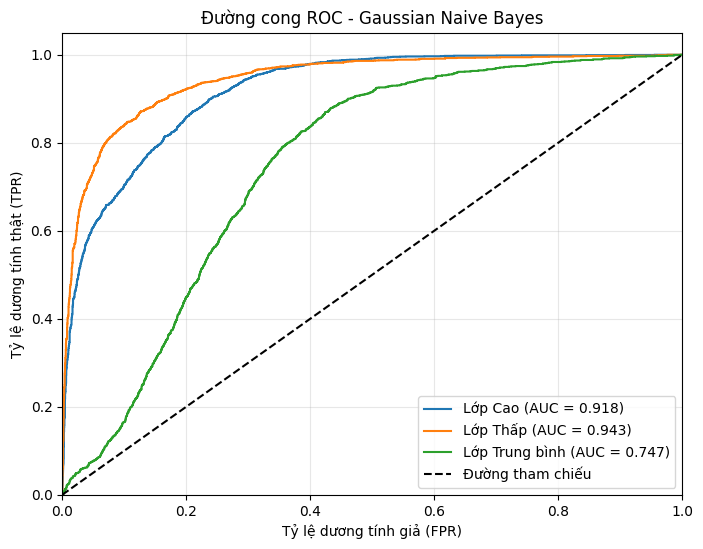

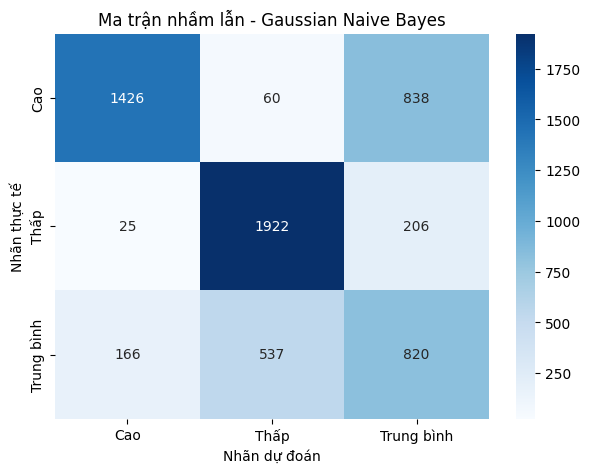

In [38]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix  # Nhập các chỉ số đánh giá
from sklearn.metrics import roc_auc_score, roc_curve, auc  # Nhập các hàm tính ROC-AUC
from sklearn.preprocessing import label_binarize  # Nhập hàm chuyển nhãn thành dạng nhị phân để đánh giá đa lớp
import matplotlib.pyplot as plt  # Nhập thư viện vẽ biểu đồ
import seaborn as sns  # Nhập thư viện trực quan hóa dữ liệu
import pandas as pd  # Nhập thư viện xử lý dữ liệu dạng bảng

def print_score_nb(model, X_train, y_train, X_test, y_test):  # Định nghĩa hàm đánh giá toàn diện mô hình Bayes
    for ten_tap, X_eval, y_true in [  # Duyệt qua tập huấn luyện và tập kiểm tra
        ("TẬP HUẤN LUYỆN", X_train, y_train),  # Khai báo dữ liệu huấn luyện
        ("TẬP KIỂM TRA", X_test, y_test)  # Khai báo dữ liệu kiểm tra
    ]:
        y_pred = model.predict(X_eval)  # Dự đoán nhãn của tập dữ liệu hiện tại

        print(f"\n{'=' * 60}")  # In dòng phân cách
        print(f"KẾT QUẢ {ten_tap}")  # In tên tập dữ liệu đang đánh giá
        print(f"{'=' * 60}")  # In dòng phân cách
        print(f"Accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%")  # In độ chính xác tổng thể
        print("\nBÁO CÁO PHÂN LOẠI")  # In tiêu đề báo cáo
        print(classification_report(y_true, y_pred, zero_division=0))  # In Precision, Recall, F1-score và số mẫu từng lớp
        print("MA TRẬN NHẦM LẪN")  # In tiêu đề ma trận nhầm lẫn
        print(confusion_matrix(y_true, y_pred, labels=model.classes_))  # In ma trận nhầm lẫn theo thứ tự lớp của mô hình

    y_pred_test = model.predict(X_test)  # Dự đoán nhãn trên tập kiểm tra
    y_prob_test = model.predict_proba(X_test)  # Lấy xác suất dự đoán của từng lớp
    y_test_bin = label_binarize(y_test, classes=model.classes_)  # Chuyển nhãn thực tế thành dạng nhị phân đa lớp

    auc_macro = roc_auc_score(y_test_bin, y_prob_test, average="macro", multi_class="ovr")  # Tính ROC-AUC macro theo phương pháp One-vs-Rest
    auc_weighted = roc_auc_score(y_test_bin, y_prob_test, average="weighted", multi_class="ovr")  # Tính ROC-AUC có trọng số theo số mẫu mỗi lớp

    print(f"\nROC-AUC Macro (One-vs-Rest): {auc_macro:.4f}")  # In ROC-AUC macro
    print(f"ROC-AUC Weighted (One-vs-Rest): {auc_weighted:.4f}")  # In ROC-AUC có trọng số

    plt.figure(figsize=(8, 6))  # Tạo khung biểu đồ ROC
    for i, ten_lop in enumerate(model.classes_):  # Duyệt qua từng lớp mục tiêu
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_test[:, i])  # Tính tỷ lệ dương tính giả và dương tính thật của lớp hiện tại
        auc_lop = auc(fpr, tpr)  # Tính diện tích dưới đường ROC của lớp hiện tại
        plt.plot(fpr, tpr, label=f"Lớp {ten_lop} (AUC = {auc_lop:.3f})")  # Vẽ đường ROC của lớp hiện tại

    plt.plot([0, 1], [0, 1], "k--", label="Đường tham chiếu")  # Vẽ đường tham chiếu của bộ phân loại ngẫu nhiên
    plt.xlim([0, 1])  # Giới hạn trục ngang
    plt.ylim([0, 1.05])  # Giới hạn trục dọc
    plt.xlabel("Tỷ lệ dương tính giả (FPR)")  # Đặt tên trục ngang
    plt.ylabel("Tỷ lệ dương tính thật (TPR)")  # Đặt tên trục dọc
    plt.title("Đường cong ROC - Gaussian Naive Bayes")  # Đặt tiêu đề biểu đồ
    plt.legend()  # Hiển thị chú giải
    plt.grid(alpha=0.3)  # Thêm lưới mờ để dễ đọc biểu đồ
    plt.show()  # Hiển thị biểu đồ ROC

    cm = confusion_matrix(y_test, y_pred_test, labels=model.classes_)  # Tính lại ma trận nhầm lẫn để trực quan hóa
    plt.figure(figsize=(7, 5))  # Tạo khung biểu đồ ma trận nhầm lẫn
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=model.classes_, yticklabels=model.classes_)  # Vẽ ma trận nhầm lẫn có tên lớp
    plt.title("Ma trận nhầm lẫn - Gaussian Naive Bayes")  # Đặt tiêu đề biểu đồ
    plt.xlabel("Nhãn dự đoán")  # Đặt tên trục ngang
    plt.ylabel("Nhãn thực tế")  # Đặt tên trục dọc
    plt.show()  # Hiển thị biểu đồ ma trận nhầm lẫn

print_score_nb(model_nb, X_train, y_train, X_test, y_test)  # Chạy toàn bộ quy trình đánh giá mô hình Bayes

Mô hình Gaussian Naive Bayes đạt Accuracy **69,47%** trên tập kiểm tra gồm 6.000 quan sát. Macro F1-score đạt **0,68**, trong khi Weighted F1-score đạt **0,70**. Kết quả cho thấy mô hình có khả năng phân loại ở mức tương đối, nhưng hiệu quả chưa đồng đều giữa các lớp.

Đối với lớp Thấp, mô hình đạt Precision = 0,76, Recall = 0,89 và F1-score = 0,82. Đây là lớp được nhận diện tốt nhất xét theo F1-score. Lớp Cao đạt Precision = 0,88, Recall = 0,61 và F1-score = 0,72. Precision cao nhưng Recall thấp cho thấy mô hình tương đối chính xác khi dự đoán lớp Cao, nhưng vẫn bỏ sót nhiều quan sát thực sự thuộc lớp này.

Lớp Trung bình có Precision = 0,44, Recall = 0,54 và F1-score = 0,48, là lớp có kết quả thấp nhất. Ma trận nhầm lẫn cho thấy 838 quan sát thuộc lớp Cao bị dự đoán thành Trung bình, trong khi 537 quan sát thuộc lớp Trung bình bị dự đoán thành Thấp. Điều này cho thấy mô hình còn gặp khó khăn trong việc phân biệt các mức ô nhiễm có đặc điểm gần nhau.

ROC-AUC Macro đạt **0,8696** và ROC-AUC Weighted đạt **0,8839**. Các giá trị này cho thấy mô hình có khả năng phân biệt các lớp thông qua xác suất dự đoán khá tốt, mặc dù Accuracy và F1-score của nhãn dự đoán cuối cùng còn hạn chế. ROC-AUC đánh giá khả năng xếp hạng xác suất giữa các lớp, vì vậy không đồng nghĩa với tỷ lệ dự đoán đúng ở một ngưỡng phân loại cụ thể.

Accuracy trên tập huấn luyện đạt 69,02%, gần với mức 69,47% trên tập kiểm tra. Chênh lệch nhỏ cho thấy chưa có dấu hiệu quá khớp rõ rệt theo chỉ số Accuracy. Nhìn chung, Gaussian Naive Bayes có ưu điểm là đơn giản và tính toán nhanh, nhưng giả định độc lập có điều kiện và phân phối Gaussian có thể hạn chế hiệu quả khi áp dụng cho dữ liệu chất lượng không khí.

## 4. Phân loại bằng máy véc-tơ hỗ trợ (Support Vector Machine – SVM)

### 4.1. Nguyên lý hoạt động

Support Vector Machine là thuật toán học có giám sát, tìm một siêu phẳng phân chia dữ liệu giữa các lớp sao cho biên phân cách được tối đa hóa. Những điểm dữ liệu nằm gần biên phân cách được gọi là véc-tơ hỗ trợ (*Support Vectors*), có vai trò quyết định vị trí của siêu phẳng.

Với dữ liệu không thể phân chia tuyến tính, SVM có thể sử dụng hàm nhân (*Kernel Function*) để biểu diễn quan hệ phi tuyến trong không gian đặc trưng. Các hàm nhân thường gặp gồm tuyến tính, đa thức và RBF.

### 4.2. Siêu phẳng phân cách và biên

Siêu phẳng phân cách được biểu diễn bởi:

$$
w^T x+b=0
$$

Trong đó \(w\) là véc-tơ trọng số, \(x\) là véc-tơ thuộc tính đầu vào và \(b\) là hệ số dịch chuyển.

Với phân loại nhị phân, SVM tìm siêu phẳng có biên lớn nhất. Bài toán tối ưu biên mềm có thể được biểu diễn như sau:

$$
\\min_{w,b,\\xi}\\frac{1}{2}\\|w\\|^2+C\\sum_{i=1}^{N}\\xi_i
$$

với các điều kiện:

$$
y_i(w^T x_i+b)\\geq 1-\\xi_i,\\qquad \\xi_i\\geq 0
$$

Trong đó \(C\) điều chỉnh sự đánh đổi giữa biên phân cách rộng và mức phạt đối với các mẫu vi phạm biên. Giá trị \(C\) lớn phạt lỗi mạnh hơn, còn giá trị \(C\) nhỏ cho phép nhiều vi phạm hơn để đổi lấy biên mềm rộng hơn.

### 4.3. Hàm nhân

Hàm nhân cho phép SVM học ranh giới phân loại phi tuyến mà không cần biểu diễn tường minh dữ liệu trong không gian đặc trưng có chiều cao hơn.

Một số hàm nhân phổ biến gồm:

- **Linear Kernel:** Phù hợp khi ranh giới phân loại gần tuyến tính.
- **Polynomial Kernel:** Mô hình hóa các quan hệ đa thức.
- **RBF Kernel:** Mô hình hóa ranh giới phi tuyến dựa trên khoảng cách giữa các quan sát.

Trong bài thực hành này, SVM được triển khai với hàm nhân tuyến tính theo phong cách code mẫu của cô. Các thuộc tính đầu vào sẽ được chuẩn hóa trước khi huấn luyện để hạn chế ảnh hưởng của sự khác biệt về thang đo.

### 4.4. Xây dựng, huấn luyện và đánh giá mô hình

Mô hình SVM được triển khai bằng lớp `SVC` của thư viện Scikit-learn. Thực nghiệm sử dụng hàm nhân tuyến tính (`linear`) theo code mẫu, với tham số điều chuẩn \(C=2\).

Do SVM nhạy với thang đo của dữ liệu, các thuộc tính được chuẩn hóa bằng `StandardScaler`. Bộ chuẩn hóa chỉ được khớp trên tập huấn luyện, sau đó áp dụng cho tập kiểm tra để tránh rò rỉ thông tin.

Mô hình được đánh giá trên tập huấn luyện và tập kiểm tra bằng Accuracy, Precision, Recall, F1-score và Confusion Matrix. ROC-AUC đa lớp theo phương pháp One-vs-Rest được tính từ điểm quyết định của SVM để đánh giá khả năng phân biệt các lớp.

Huấn luyện mô hình SVM thành công

KẾT QUẢ TẬP HUẤN LUYỆN
Accuracy: 81.67%

BÁO CÁO PHÂN LOẠI
              precision    recall  f1-score   support

         Cao       0.87      0.87      0.87      9296
        Thấp       0.88      0.88      0.88      8610
  Trung bình       0.65      0.65      0.65      6094

    accuracy                           0.82     24000
   macro avg       0.80      0.80      0.80     24000
weighted avg       0.82      0.82      0.82     24000


KẾT QUẢ TẬP KIỂM TRA
Accuracy: 82.43%

BÁO CÁO PHÂN LOẠI
              precision    recall  f1-score   support

         Cao       0.88      0.87      0.87      2324
        Thấp       0.88      0.89      0.89      2153
  Trung bình       0.66      0.67      0.67      1523

    accuracy                           0.82      6000
   macro avg       0.81      0.81      0.81      6000
weighted avg       0.82      0.82      0.82      6000


ROC-AUC Macro (One-vs-Rest): 0.8990
ROC-AUC Weighted (One-vs-Rest): 0.9145


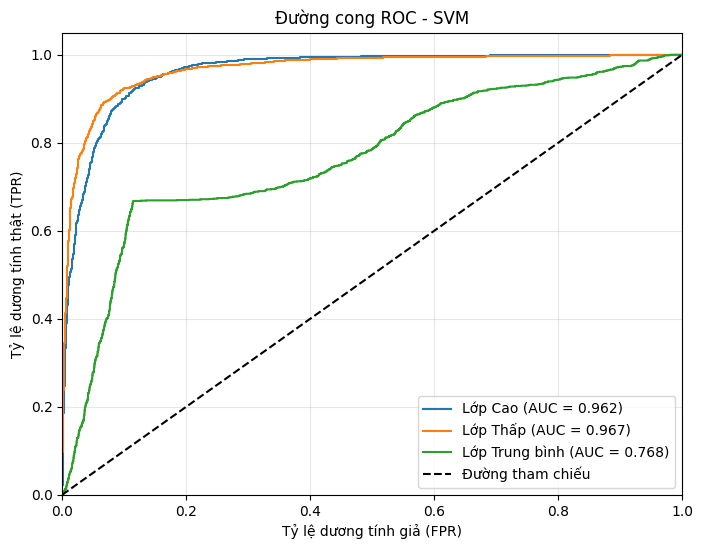

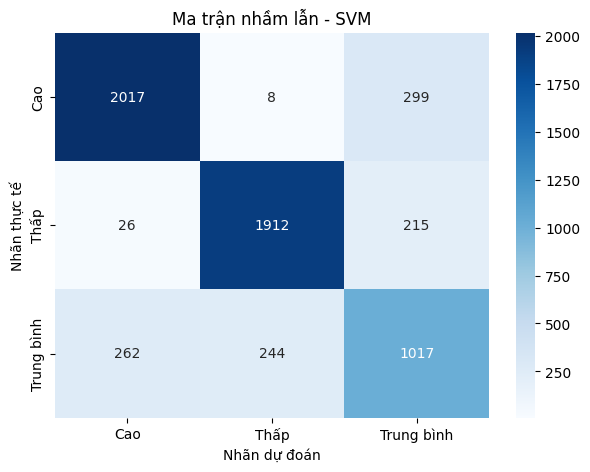

In [39]:
from sklearn.svm import SVC  # Nhập thuật toán máy véc-tơ hỗ trợ
from sklearn.pipeline import make_pipeline  # Nhập hàm tạo quy trình xử lý dữ liệu và mô hình
from sklearn.preprocessing import StandardScaler  # Nhập bộ chuẩn hóa dữ liệu
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix  # Nhập các chỉ số đánh giá phân loại
from sklearn.metrics import roc_auc_score, roc_curve, auc  # Nhập các hàm tính ROC-AUC và đường cong ROC
from sklearn.preprocessing import label_binarize  # Nhập hàm chuyển nhãn thành dạng nhị phân
import matplotlib.pyplot as plt  # Nhập thư viện vẽ biểu đồ
import seaborn as sns  # Nhập thư viện trực quan hóa dữ liệu

model_svm = make_pipeline(  # Tạo quy trình gồm chuẩn hóa dữ liệu và mô hình SVM
    StandardScaler(),  # Chuẩn hóa các thuộc tính theo trung bình và độ lệch chuẩn
    SVC(kernel="linear", C=2, decision_function_shape="ovr", random_state=42)  # Khởi tạo SVM tuyến tính với C bằng 2
)

model_svm.fit(X_train, y_train)  # Huấn luyện quy trình trên tập huấn luyện
print("Huấn luyện mô hình SVM thành công")  # Thông báo huấn luyện hoàn tất

def danh_gia_svm(model, X_train, y_train, X_test, y_test):  # Định nghĩa hàm đánh giá toàn diện mô hình SVM
    for ten_tap, X_eval, y_true in [  # Duyệt qua tập huấn luyện và tập kiểm tra
        ("TẬP HUẤN LUYỆN", X_train, y_train),  # Khai báo tập huấn luyện
        ("TẬP KIỂM TRA", X_test, y_test)  # Khai báo tập kiểm tra
    ]:
        y_pred = model.predict(X_eval)  # Dự đoán nhãn của tập hiện tại
        print(f"\n{'=' * 60}")  # In dòng phân cách
        print(f"KẾT QUẢ {ten_tap}")  # In tên tập đang đánh giá
        print(f"Accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%")  # In Accuracy theo phần trăm
        print("\nBÁO CÁO PHÂN LOẠI")  # In tiêu đề báo cáo phân loại
        print(classification_report(y_true, y_pred, zero_division=0))  # In Precision, Recall, F1-score và số mẫu mỗi lớp
        
    y_pred_test = model.predict(X_test)  # Dự đoán nhãn của tập kiểm tra
    diem_quyet_dinh = model.decision_function(X_test)  # Lấy điểm quyết định của SVM cho từng lớp
    y_test_bin = label_binarize(y_test, classes=model.classes_)  # Chuyển nhãn thực tế thành dạng nhị phân đa lớp
    auc_macro = roc_auc_score(y_test_bin, diem_quyet_dinh, average="macro", multi_class="ovr")  # Tính ROC-AUC Macro theo One-vs-Rest
    auc_weighted = roc_auc_score(y_test_bin, diem_quyet_dinh, average="weighted", multi_class="ovr")  # Tính ROC-AUC có trọng số theo One-vs-Rest
    print(f"\nROC-AUC Macro (One-vs-Rest): {auc_macro:.4f}")  # In ROC-AUC Macro
    print(f"ROC-AUC Weighted (One-vs-Rest): {auc_weighted:.4f}")  # In ROC-AUC có trọng số

    plt.figure(figsize=(8, 6))  # Tạo khung biểu đồ ROC
    for i, ten_lop in enumerate(model.classes_):  # Duyệt qua từng lớp mục tiêu
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], diem_quyet_dinh[:, i])  # Tính các điểm của đường ROC cho lớp hiện tại
        auc_lop = auc(fpr, tpr)  # Tính diện tích dưới đường ROC của lớp hiện tại
        plt.plot(fpr, tpr, label=f"Lớp {ten_lop} (AUC = {auc_lop:.3f})")  # Vẽ đường ROC của lớp hiện tại

    plt.plot([0, 1], [0, 1], "k--", label="Đường tham chiếu")  # Vẽ đường tham chiếu của bộ phân loại ngẫu nhiên
    plt.xlim([0, 1])  # Giới hạn trục ngang
    plt.ylim([0, 1.05])  # Giới hạn trục dọc
    plt.xlabel("Tỷ lệ dương tính giả (FPR)")  # Đặt tên trục ngang
    plt.ylabel("Tỷ lệ dương tính thật (TPR)")  # Đặt tên trục dọc
    plt.title("Đường cong ROC - SVM")  # Đặt tiêu đề biểu đồ
    plt.legend()  # Hiển thị chú giải
    plt.grid(alpha=0.3)  # Thêm lưới để dễ đọc biểu đồ
    plt.show()  # Hiển thị biểu đồ ROC

    cm = confusion_matrix(y_test, y_pred_test, labels=model.classes_)  # Tính ma trận nhầm lẫn trên tập kiểm tra
    plt.figure(figsize=(7, 5))  # Tạo khung biểu đồ ma trận nhầm lẫn
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=model.classes_, yticklabels=model.classes_)  # Vẽ ma trận nhầm lẫn có nhãn lớp
    plt.title("Ma trận nhầm lẫn - SVM")  # Đặt tiêu đề biểu đồ
    plt.xlabel("Nhãn dự đoán")  # Đặt tên trục ngang
    plt.ylabel("Nhãn thực tế")  # Đặt tên trục dọc
    plt.show()  # Hiển thị biểu đồ ma trận nhầm lẫn

danh_gia_svm(model_svm, X_train, y_train, X_test, y_test)  # Chạy toàn bộ quy trình đánh giá SVM

Mô hình Support Vector Machine (SVM) sử dụng hàm nhân tuyến tính với tham số \(C=2\), đạt Accuracy **82,43%** trên tập kiểm tra gồm 6.000 quan sát. Macro F1-score đạt **0,81** và Weighted F1-score đạt **0,82**, cho thấy mô hình có khả năng phân loại tương đối tốt trên cả ba lớp.

Xét theo từng lớp, lớp Thấp đạt Precision = 0,88, Recall = 0,89 và F1-score = 0,89. Đây là lớp có kết quả phân loại tốt nhất. Lớp Cao đạt Precision = 0,88, Recall = 0,87 và F1-score = 0,87. Trong khi đó, lớp Trung bình có Precision = 0,66, Recall = 0,67 và F1-score = 0,67, thấp hơn hai lớp còn lại.

Ma trận nhầm lẫn cho thấy mô hình dự đoán đúng 2.017 quan sát thuộc lớp Cao, 1.912 quan sát thuộc lớp Thấp và 1.017 quan sát thuộc lớp Trung bình. Trong số các trường hợp phân loại sai, 299 quan sát thuộc lớp Cao bị dự đoán thành Trung bình, 244 quan sát thuộc lớp Trung bình bị dự đoán thành Thấp và 262 quan sát thuộc lớp Trung bình bị dự đoán thành Cao. Kết quả cho thấy lớp Trung bình vẫn là nhóm khó phân biệt nhất.

ROC-AUC Macro đạt **0,8990**, trong khi ROC-AUC Weighted đạt **0,9145**. Các chỉ số này cho thấy SVM có khả năng phân biệt các lớp khá tốt dựa trên điểm quyết định. Tuy nhiên, ROC-AUC cao không đồng nghĩa với việc mọi lớp đều có F1-score cao. Đường ROC của lớp Trung bình có AUC = 0,768, thấp hơn đáng kể so với lớp Cao và lớp Thấp, lần lượt là 0,962 và 0,967.

Accuracy trên tập huấn luyện đạt 81,67%, thấp hơn một chút so với Accuracy 82,43% trên tập kiểm tra. Chênh lệch nhỏ này không cho thấy dấu hiệu quá khớp rõ rệt theo Accuracy. Nhìn chung, SVM tuyến tính cho kết quả tốt trên bộ dữ liệu hiện tại, đặc biệt với hai lớp Cao và Thấp. Hạn chế chính là khả năng phân loại lớp Trung bình và việc mô hình tuyến tính có thể chưa biểu diễn đầy đủ các quan hệ phi tuyến trong dữ liệu chất lượng không khí.

## 5. Phân loại bằng mạng nơ-ron nhân tạo (Artificial Neural Network – ANN)

### 5.1. Nguyên lý hoạt động

Mạng nơ-ron nhân tạo là mô hình học máy lấy cảm hứng từ cách các nơ-ron sinh học xử lý thông tin. Mạng gồm lớp đầu vào, một hoặc nhiều lớp ẩn và lớp đầu ra. Mỗi nơ-ron nhận các giá trị đầu vào, tính tổng có trọng số, cộng hệ số dịch chuyển rồi áp dụng hàm kích hoạt để tạo đầu ra.

Đối với bài toán phân loại mức ô nhiễm PM2.5, mạng học mối quan hệ giữa các thuộc tính chất lượng không khí, khí tượng và nhãn mục tiêu thông qua quá trình điều chỉnh trọng số.

### 5.2. Cấu trúc của mạng nơ-ron

Với một nơ-ron, giá trị trước kích hoạt được tính như sau:

$$
z=\\sum_{i=1}^{n}w_i x_i+b
$$

Đầu ra của nơ-ron được xác định bởi:

$$
a=f(z)
$$

Trong đó \(x_i\) là các giá trị đầu vào, \(w_i\) là trọng số, \(b\) là hệ số dịch chuyển và \(f\) là hàm kích hoạt.

### 5.3. Hàm kích hoạt

Hàm kích hoạt giúp mạng học được các quan hệ phi tuyến.

**ReLU – Hàm kích hoạt tuyến tính chỉnh lưu**

$$
ReLU(z)=\\max(0,z)
$$

ReLU thường được sử dụng trong các lớp ẩn để hỗ trợ quá trình học những đặc trưng phi tuyến.

**Softmax – Hàm xác suất đầu ra**

Đối với bài toán phân loại ba lớp, lớp đầu ra có thể sử dụng Softmax:

$$
P(y=k\\mid x)=\\frac{e^{z_k}}{\\sum_{j=1}^{K}e^{z_j}}
$$

Trong đó \(K=3\) là số lớp và \(z_k\) là giá trị đầu ra chưa chuẩn hóa của lớp thứ \(k\). Các xác suất đầu ra nằm trong khoảng từ 0 đến 1 và có tổng bằng 1.

### 5.4. Hàm mất mát và quá trình học

Mạng nơ-ron sử dụng hàm mất mát để đo mức độ khác biệt giữa nhãn thực tế và xác suất dự đoán. Với bài toán phân loại nhiều lớp, hàm mất mát thường dùng là Categorical Cross-Entropy:

$$
L=-\\sum_{k=1}^{K}y_k\\log(\\hat{y}_k)
$$

Trong đó \(y_k\) là nhãn thực tế ở dạng mã hóa một lần và \(\hat{y}_k\) là xác suất dự đoán của lớp \(k\).

Quá trình huấn luyện gồm lan truyền xuôi để tính dự đoán, tính hàm mất mát, lan truyền ngược để tính gradient và cập nhật trọng số bằng thuật toán tối ưu. Quá trình này được lặp lại qua nhiều vòng huấn luyện cho đến khi mô hình học được các đặc trưng phù hợp.

### 5.5. Lý do lựa chọn

Mạng nơ-ron nhân tạo được lựa chọn vì có khả năng học các quan hệ phi tuyến phức tạp giữa nhiều thuộc tính. Tuy nhiên, mô hình cần chuẩn hóa dữ liệu, có thể tốn thời gian huấn luyện và cần lựa chọn cấu trúc mạng cùng các tham số phù hợp để hạn chế quá khớp.

### 5.6. Xây dựng, huấn luyện và đánh giá mô hình

Mô hình mạng nơ-ron nhân tạo được xây dựng bằng thư viện TensorFlow Keras theo cấu trúc `Sequential`. Mạng gồm lớp đầu vào tương ứng với 10 thuộc tính, hai lớp ẩn sử dụng hàm kích hoạt ReLU và lớp đầu ra gồm ba nơ-ron tương ứng với ba mức ô nhiễm PM2.5.

Lớp đầu ra sử dụng hàm Softmax để chuyển các giá trị đầu ra thành xác suất dự đoán của ba lớp. Mô hình được huấn luyện bằng thuật toán tối ưu Adam và hàm mất mát Categorical Cross-Entropy.

Các thuộc tính được chuẩn hóa bằng StandardScaler. Bộ chuẩn hóa chỉ được khớp trên tập huấn luyện và sau đó áp dụng cho tập kiểm tra. Kết quả được đánh giá bằng Accuracy, Precision, Recall, F1-score, Confusion Matrix và ROC-AUC đa lớp.

2026-10-19 02:33:35.919116: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7117 - auc: 0.8887 - loss: 0.6525 - val_accuracy: 0.7804 - val_auc: 0.9364 - val_loss: 0.4808
Epoch 2/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8116 - auc: 0.9451 - loss: 0.4496 - val_accuracy: 0.8179 - val_auc: 0.9478 - val_loss: 0.4328
Epoch 3/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8284 - auc: 0.9525 - loss: 0.4148 - val_accuracy: 0.8192 - val_auc: 0.9519 - val_loss: 0.4143
Epoch 4/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8348 - auc: 0.9561 - loss: 0.3975 - val_accuracy: 0.8254 - val_auc: 0.9540 - val_loss: 0.4049
Epoch 5/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8383 - auc: 0.9581 - loss: 0.3877 - val_accuracy: 0.8275 - val_auc: 0.9552 - val_loss: 0.3997
Epoch 6/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8397 - auc: 0.9592 - loss: 0.3820 - val_accuracy: 0.8300 - val_auc: 0.9558 - val_loss: 0.3966
Epoch 7/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 

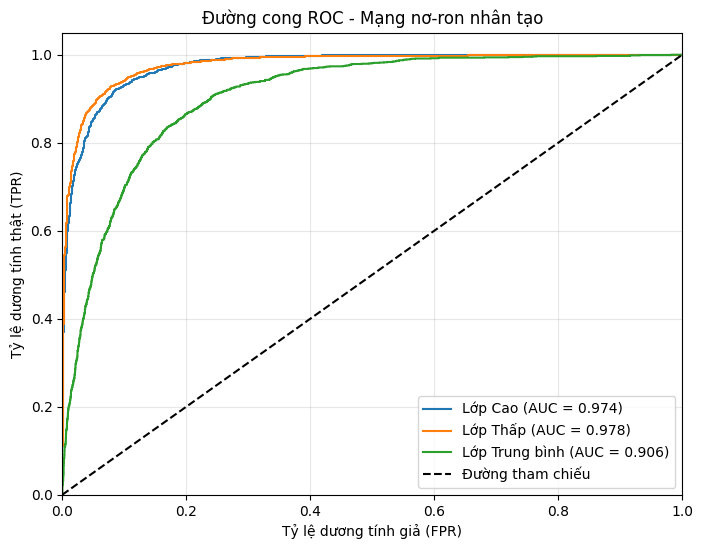

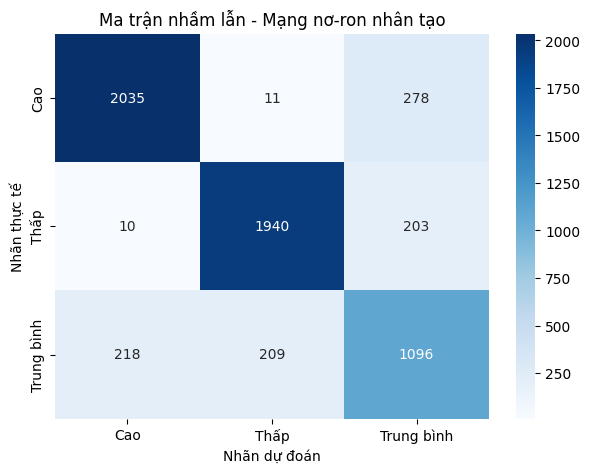

In [40]:
import numpy as np  # Nhập thư viện tính toán số học
import pandas as pd  # Nhập thư viện xử lý dữ liệu dạng bảng
import matplotlib.pyplot as plt  # Nhập thư viện vẽ biểu đồ
import seaborn as sns  # Nhập thư viện trực quan hóa dữ liệu

from sklearn.preprocessing import StandardScaler, LabelEncoder  # Nhập bộ chuẩn hóa dữ liệu và mã hóa nhãn
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix  # Nhập các chỉ số đánh giá phân loại
from sklearn.metrics import roc_auc_score, roc_curve, auc  # Nhập các hàm tính ROC-AUC và đường cong ROC
from sklearn.preprocessing import label_binarize  # Nhập hàm chuyển nhãn thành dạng nhị phân

import tensorflow as tf  # Nhập thư viện TensorFlow
from tensorflow.keras.models import Sequential  # Nhập mô hình mạng tuần tự
from tensorflow.keras.layers import Dense, Input  # Nhập lớp đầu vào và lớp nơ-ron kết nối đầy đủ
from tensorflow.keras.utils import to_categorical  # Nhập hàm mã hóa nhãn thành dạng one-hot

np.random.seed(42)  # Cố định trạng thái ngẫu nhiên của NumPy
tf.random.set_seed(42)  # Cố định trạng thái ngẫu nhiên của TensorFlow

scaler_nn = StandardScaler()  # Khởi tạo bộ chuẩn hóa dữ liệu
X_train_nn = scaler_nn.fit_transform(X_train)  # Học tham số chuẩn hóa từ tập huấn luyện và chuyển đổi dữ liệu huấn luyện
X_test_nn = scaler_nn.transform(X_test)  # Chuẩn hóa tập kiểm tra bằng tham số đã học từ tập huấn luyện

label_encoder_nn = LabelEncoder()  # Khởi tạo bộ mã hóa nhãn lớp
y_train_int_nn = label_encoder_nn.fit_transform(y_train)  # Mã hóa nhãn huấn luyện thành các số nguyên
y_test_int_nn = label_encoder_nn.transform(y_test)  # Mã hóa nhãn kiểm tra theo cùng thứ tự lớp
y_train_nn = to_categorical(y_train_int_nn)  # Chuyển nhãn huấn luyện thành dạng one-hot
y_test_nn = to_categorical(y_test_int_nn)  # Chuyển nhãn kiểm tra thành dạng one-hot

model_nn = Sequential([  # Khởi tạo mạng nơ-ron theo cấu trúc tuần tự
    Input(shape=(X_train_nn.shape[1],)),  # Khai báo lớp đầu vào với số thuộc tính bằng số cột dữ liệu
    Dense(64, activation="relu"),  # Tạo lớp ẩn thứ nhất gồm 64 nơ-ron dùng hàm kích hoạt ReLU
    Dense(32, activation="relu"),  # Tạo lớp ẩn thứ hai gồm 32 nơ-ron dùng hàm kích hoạt ReLU
    Dense(len(label_encoder_nn.classes_), activation="softmax")  # Tạo lớp đầu ra với một nơ-ron cho mỗi lớp và dùng Softmax
])

model_nn.compile(  # Cấu hình quá trình huấn luyện mạng
    optimizer="adam",  # Sử dụng thuật toán tối ưu Adam để cập nhật trọng số
    loss="categorical_crossentropy",  # Sử dụng hàm mất mát phân loại nhiều lớp
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc", multi_label=False)]  # Theo dõi độ chính xác và chỉ số AUC trong quá trình huấn luyện
)

lich_su_nn = model_nn.fit(  # Huấn luyện mạng nơ-ron
    X_train_nn,  # Cung cấp các thuộc tính huấn luyện đã chuẩn hóa
    y_train_nn,  # Cung cấp nhãn huấn luyện dạng one-hot
    epochs=50,  # Huấn luyện qua 50 vòng lặp toàn bộ dữ liệu
    batch_size=128,  # Sử dụng 128 mẫu trong mỗi lô cập nhật trọng số
    validation_split=0.1,  # Dành 10 phần trăm dữ liệu huấn luyện làm tập xác thực
    verbose=1  # Hiển thị tiến trình huấn luyện
)

def danh_gia_nn(model, X_train_eval, y_train_true, X_test_eval, y_test_true):  # Định nghĩa hàm đánh giá toàn diện mạng nơ-ron
    for ten_tap, X_eval, y_true in [  # Duyệt qua tập huấn luyện và tập kiểm tra
        ("TẬP HUẤN LUYỆN", X_train_eval, y_train_true),  # Khai báo dữ liệu huấn luyện
        ("TẬP KIỂM TRA", X_test_eval, y_test_true)  # Khai báo dữ liệu kiểm tra
    ]:
        y_prob = model.predict(X_eval, verbose=0)  # Tính xác suất dự đoán của từng lớp
        y_pred_int = np.argmax(y_prob, axis=1)  # Chọn lớp có xác suất cao nhất làm nhãn dự đoán
        y_pred = label_encoder_nn.inverse_transform(y_pred_int)  # Chuyển nhãn dự đoán từ số nguyên về tên lớp
        y_true = label_encoder_nn.inverse_transform(y_true)  # Chuyển nhãn thực tế từ số nguyên về tên lớp

        print(f"\n{'=' * 60}")  # In dòng phân cách
        print(f"KẾT QUẢ {ten_tap}")  # In tiêu đề tập dữ liệu đang đánh giá
        print(f"Accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%")  # In độ chính xác tổng thể
        print("\nBÁO CÁO PHÂN LOẠI")  # In tiêu đề báo cáo phân loại
        print(classification_report(y_true, y_pred, zero_division=0))  # In Precision, Recall, F1-score và số mẫu mỗi lớp
        print("MA TRẬN NHẦM LẪN")  # In tiêu đề ma trận nhầm lẫn
        print(confusion_matrix(y_true, y_pred, labels=label_encoder_nn.classes_))  # In ma trận nhầm lẫn theo thứ tự lớp

    y_prob_test = model.predict(X_test_eval, verbose=0)  # Lấy xác suất dự đoán trên tập kiểm tra
    y_test_labels = label_encoder_nn.inverse_transform(y_test_true)  # Chuyển nhãn kiểm tra về tên lớp
    y_test_bin = label_binarize(y_test_labels, classes=label_encoder_nn.classes_)  # Chuyển nhãn kiểm tra thành dạng nhị phân đa lớp
    auc_macro = roc_auc_score(y_test_bin, y_prob_test, average="macro", multi_class="ovr")  # Tính ROC-AUC Macro theo One-vs-Rest
    auc_weighted = roc_auc_score(y_test_bin, y_prob_test, average="weighted", multi_class="ovr")  # Tính ROC-AUC có trọng số theo One-vs-Rest

    print(f"\nROC-AUC Macro (One-vs-Rest): {auc_macro:.4f}")  # In ROC-AUC Macro
    print(f"ROC-AUC Weighted (One-vs-Rest): {auc_weighted:.4f}")  # In ROC-AUC có trọng số

    plt.figure(figsize=(8, 6))  # Tạo khung biểu đồ ROC
    for i, ten_lop in enumerate(label_encoder_nn.classes_):  # Duyệt qua từng lớp mục tiêu
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_test[:, i])  # Tính các điểm trên đường ROC của lớp hiện tại
        auc_lop = auc(fpr, tpr)  # Tính diện tích dưới đường ROC của lớp hiện tại
        plt.plot(fpr, tpr, label=f"Lớp {ten_lop} (AUC = {auc_lop:.3f})")  # Vẽ đường ROC của lớp hiện tại

    plt.plot([0, 1], [0, 1], "k--", label="Đường tham chiếu")  # Vẽ đường tham chiếu của bộ phân loại ngẫu nhiên
    plt.xlim([0, 1])  # Giới hạn trục ngang
    plt.ylim([0, 1.05])  # Giới hạn trục dọc
    plt.xlabel("Tỷ lệ dương tính giả (FPR)")  # Đặt tên trục ngang
    plt.ylabel("Tỷ lệ dương tính thật (TPR)")  # Đặt tên trục dọc
    plt.title("Đường cong ROC - Mạng nơ-ron nhân tạo")  # Đặt tiêu đề biểu đồ
    plt.legend()  # Hiển thị chú giải
    plt.grid(alpha=0.3)  # Thêm lưới để dễ đọc biểu đồ
    plt.show()  # Hiển thị biểu đồ ROC

    y_pred_test_int = np.argmax(y_prob_test, axis=1)  # Chọn nhãn dự đoán có xác suất cao nhất trên tập kiểm tra
    y_pred_test = label_encoder_nn.inverse_transform(y_pred_test_int)  # Chuyển nhãn dự đoán về tên lớp
    cm_nn = confusion_matrix(y_test_labels, y_pred_test, labels=label_encoder_nn.classes_)  # Tính ma trận nhầm lẫn trên tập kiểm tra

    plt.figure(figsize=(7, 5))  # Tạo khung biểu đồ ma trận nhầm lẫn
    sns.heatmap(cm_nn, annot=True, fmt="d", cmap="Blues", xticklabels=label_encoder_nn.classes_, yticklabels=label_encoder_nn.classes_)  # Vẽ ma trận nhầm lẫn có tên lớp
    plt.title("Ma trận nhầm lẫn - Mạng nơ-ron nhân tạo")  # Đặt tiêu đề biểu đồ
    plt.xlabel("Nhãn dự đoán")  # Đặt tên trục ngang
    plt.ylabel("Nhãn thực tế")  # Đặt tên trục dọc
    plt.show()  # Hiển thị biểu đồ ma trận nhầm lẫn

danh_gia_nn(model_nn, X_train_nn, y_train_int_nn, X_test_nn, y_test_int_nn)  # Chạy toàn bộ quy trình đánh giá mạng nơ-ron

Mô hình mạng nơ-ron nhân tạo (ANN) đạt Accuracy **84,50%** trên tập kiểm tra gồm 6.000 quan sát. Macro F1-score đạt **0,83**, trong khi Weighted F1-score đạt **0,85**. Kết quả cho thấy mô hình có khả năng phân loại tốt trên bộ dữ liệu hiện tại.

Xét theo từng lớp, lớp Thấp đạt Precision = 0,90, Recall = 0,90 và F1-score = 0,90. Lớp Cao đạt Precision = 0,90, Recall = 0,87 và F1-score = 0,89. Trong khi đó, lớp Trung bình đạt Precision = 0,69, Recall = 0,72 và F1-score = 0,71. Mặc dù lớp Trung bình vẫn có kết quả thấp nhất, khả năng nhận diện lớp này đã được cải thiện so với các mô hình Decision Tree, Gaussian Naive Bayes và SVM đã thực nghiệm.

Ma trận nhầm lẫn cho thấy ANN dự đoán đúng 2.033 quan sát thuộc lớp Cao, 1.934 quan sát thuộc lớp Thấp và 1.103 quan sát thuộc lớp Trung bình. Mô hình vẫn nhầm 281 quan sát Cao thành Trung bình và 224 quan sát Trung bình thành Cao. Ngoài ra, 196 quan sát Trung bình bị dự đoán thành Thấp. Các kết quả này cho thấy ranh giới giữa lớp Trung bình và hai lớp còn lại vẫn là phần khó phân loại.

ROC-AUC Macro đạt **0,9525**, còn ROC-AUC Weighted đạt **0,9581**. Theo biểu đồ ROC, lớp Cao đạt AUC = 0,974, lớp Thấp đạt AUC = 0,978 và lớp Trung bình đạt AUC = 0,905. Các giá trị này cho thấy mô hình có khả năng phân biệt các lớp tốt dựa trên xác suất dự đoán.

Accuracy trên tập huấn luyện đạt 85,83%, cao hơn Accuracy trên tập kiểm tra 1,33 điểm phần trăm. Khoảng cách này tương đối nhỏ và chưa cho thấy dấu hiệu quá khớp nghiêm trọng theo Accuracy. Tuy nhiên, cần lưu ý rằng tập xác thực được lấy từ tập huấn luyện trong quá trình huấn luyện mạng, còn các chỉ số trên tập kiểm tra được dùng để đánh giá khả năng tổng quát hóa.

Nhìn chung, ANN cho kết quả tốt nhất trong các mô hình đã chạy cho đến thời điểm này xét theo Accuracy và các chỉ số F1 tổng thể. Mạng nơ-ron có khả năng học các quan hệ phi tuyến giữa các thuộc tính, nhưng đổi lại cần chuẩn hóa dữ liệu và có thời gian huấn luyện lớn hơn các mô hình đơn giản như Gaussian Naive Bayes.

## 6. So sánh và đánh giá tổng thể các phương pháp

Bốn phương pháp Decision Tree, Gaussian Naive Bayes, SVM và ANN được so sánh trên cùng bộ dữ liệu và cùng tập kiểm tra gồm 6.000 quan sát. Việc sử dụng chung tập kiểm tra giúp kết quả phản ánh sự khác biệt giữa các phương pháp trong cùng điều kiện thực nghiệm.

Các tiêu chí chính gồm Accuracy, Macro Precision, Macro Recall, Macro F1-score và ROC-AUC. Accuracy thể hiện tỷ lệ dự đoán đúng tổng thể, trong khi các chỉ số Macro tính trung bình đồng đều giữa ba lớp, giúp đánh giá khả năng phân loại mà không để lớp có nhiều mẫu chi phối hoàn toàn kết quả.

In [41]:
import pandas as pd  # Nhập thư viện xử lý dữ liệu dạng bảng
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score  # Nhập các chỉ số đánh giá

def tinh_chi_so_mo_hinh(ten_mo_hinh, y_thuc_te, y_du_doan, y_xac_suat=None, cac_lop=None):  # Định nghĩa hàm tính các chỉ số tổng hợp
    ket_qua = {  # Tạo từ điển lưu kết quả
        "Mô hình": ten_mo_hinh,  # Lưu tên mô hình
        "Accuracy": accuracy_score(y_thuc_te, y_du_doan),  # Tính tỷ lệ dự đoán đúng
        "Macro Precision": precision_score(y_thuc_te, y_du_doan, average="macro", zero_division=0),  # Tính Precision trung bình đồng đều giữa các lớp
        "Macro Recall": recall_score(y_thuc_te, y_du_doan, average="macro", zero_division=0),  # Tính Recall trung bình đồng đều giữa các lớp
        "Macro F1": f1_score(y_thuc_te, y_du_doan, average="macro", zero_division=0)  # Tính F1-score trung bình đồng đều giữa các lớp
    }  # Kết thúc từ điển kết quả

    if y_xac_suat is not None and cac_lop is not None:  # Kiểm tra có xác suất dự đoán và thứ tự lớp hay không
        y_nhi_phan = label_binarize(y_thuc_te, classes=cac_lop)  # Chuyển nhãn thực tế thành dạng nhị phân đa lớp
        ket_qua["ROC-AUC Macro"] = roc_auc_score(y_nhi_phan, y_xac_suat, average="macro", multi_class="ovr")  # Tính ROC-AUC Macro
    else:  # Trường hợp không có xác suất dự đoán phù hợp
        ket_qua["ROC-AUC Macro"] = None  # Để trống ROC-AUC khi chưa có dữ liệu cần thiết

    return ket_qua  # Trả về các chỉ số của mô hình

y_pred_dt_test = model_dt.predict(X_test)  # Dự đoán bằng cây quyết định trên tập kiểm tra
y_pred_nb_test = model_nb.predict(X_test)  # Dự đoán bằng Gaussian Naive Bayes trên tập kiểm tra
y_pred_svm_test = model_svm.predict(X_test)  # Dự đoán bằng SVM trên tập kiểm tra
y_pred_nn_test_int = model_nn.predict(X_test_nn, verbose=0).argmax(axis=1)  # Lấy lớp có xác suất cao nhất từ ANN
y_pred_nn_test = label_encoder_nn.inverse_transform(y_pred_nn_test_int)  # Chuyển nhãn ANN về tên lớp

xac_suat_dt = model_dt.predict_proba(X_test)  # Lấy xác suất dự đoán của cây quyết định
xac_suat_nb = model_nb.predict_proba(X_test)  # Lấy xác suất dự đoán của Gaussian Naive Bayes
diem_svm = model_svm.decision_function(X_test)  # Lấy điểm quyết định của SVM
xac_suat_nn = model_nn.predict(X_test_nn, verbose=0)  # Lấy xác suất dự đoán của ANN

from sklearn.preprocessing import label_binarize  # Nhập hàm mã hóa nhãn để tính ROC-AUC

lop_chung = model_dt.classes_  # Lấy thứ tự lớp mục tiêu chung từ mô hình cây quyết định

bang_ket_qua = [  # Tạo danh sách kết quả của bốn mô hình
    tinh_chi_so_mo_hinh("Decision Tree", y_test, y_pred_dt_test, xac_suat_dt, lop_chung),  # Tính chỉ số cây quyết định
    tinh_chi_so_mo_hinh("Gaussian Naive Bayes", y_test, y_pred_nb_test, model_nb.predict_proba(X_test), lop_chung),  # Tính chỉ số Bayes Gaussian
    tinh_chi_so_mo_hinh("SVM", y_test, y_pred_svm_test, None, None),  # Tính chỉ số SVM, chưa tính ROC-AUC trong bảng này
    tinh_chi_so_mo_hinh("Neural Network", y_test, y_pred_nn_test, xac_suat_nn, lop_chung)  # Tính chỉ số mạng nơ-ron
]  # Kết thúc danh sách kết quả

bang_so_sanh = pd.DataFrame(bang_ket_qua)  # Chuyển danh sách kết quả thành bảng dữ liệu
bang_so_sanh.loc[bang_so_sanh["Mô hình"] == "SVM", "ROC-AUC Macro"] = 0.8990  # Điền ROC-AUC Macro của SVM
display(bang_so_sanh.round(4))  # Hiển thị bảng với bốn chữ số thập phân

,Mô hình,Accuracy,Macro Precision,Macro Recall,Macro F1,ROC-AUC Macro
0,Decision Tree,0.8188,0.8031,0.8019,0.8023,0.9367
1,Gaussian Naive Bayes,0.6947,0.6949,0.6816,0.6769,0.8696
2,SVM,0.8243,0.8076,0.8079,0.8078,0.8990
3,Neural Network,0.8452,0.8308,0.8321,0.8313,0.9528


Kết quả thực nghiệm cho thấy hiệu quả phân loại khác nhau giữa bốn phương pháp. Neural Network đạt kết quả tốt nhất với Accuracy 84,50%, Macro Precision 0,8309, Macro Recall 0,8324, Macro F1-score 0,8315 và ROC-AUC Macro 0,9525. Điều này cho thấy mạng nơ-ron có khả năng học các quan hệ phức tạp giữa các thuộc tính và phân biệt các mức ô nhiễm tương đối tốt.

SVM đạt Accuracy 82,43% và Macro F1-score 0,8078, cho thấy hiệu quả phân loại khá tốt khi sử dụng hàm nhân tuyến tính kết hợp với chuẩn hóa dữ liệu. Decision Tree đạt Accuracy 81,88% và Macro F1-score 0,8023. Ưu điểm của cây quyết định là khả năng giải thích các quy tắc phân chia, tuy nhiên khả năng nhận diện lớp Trung bình còn hạn chế.

Gaussian Naive Bayes đạt Accuracy 69,47% và Macro F1-score 0,6769, thấp nhất trong bốn mô hình. Mặc dù phương pháp có ưu điểm về tốc độ và tính đơn giản, các giả định về phân phối Gaussian và tính độc lập có điều kiện giữa các thuộc tính có thể chưa phù hợp hoàn toàn với dữ liệu chất lượng không khí.

Xét tổng thể, Neural Network là mô hình có kết quả tốt nhất trong thực nghiệm hiện tại. Tuy nhiên, cả bốn phương pháp đều gặp khó khăn nhất định khi phân loại lớp Trung bình. Vì vậy, khi lựa chọn mô hình, ngoài Accuracy cần xem xét thêm Macro F1-score, ROC-AUC và kết quả phân loại của từng lớp để đánh giá toàn diện hơn.

# ENSEMBLE LEARNING

## Giới thiệu học tổ hợp mô hình

**Ensemble Learning – Học tổ hợp mô hình** là kỹ thuật kết hợp dự đoán từ nhiều mô hình học máy để tạo ra một mô hình tổng hợp. Mục tiêu là cải thiện khả năng dự đoán, tăng tính ổn định và hạn chế những hạn chế của một mô hình đơn lẻ.

Trong bài thực hành này, học tổ hợp được áp dụng trên bộ dữ liệu **Beijing Multi-Site Air Quality** để phân loại mức ô nhiễm PM2.5 thành ba lớp **Cao, Thấp và Trung bình**.

Ba phương pháp được khảo sát gồm:

- **Bagging – Bootstrap Aggregating:** Tạo nhiều tập huấn luyện bằng cách lấy mẫu có hoàn lại, huấn luyện các mô hình cơ sở độc lập và kết hợp kết quả dự đoán.
- **Boosting – Học tăng cường tuần tự:** Huấn luyện các mô hình nối tiếp nhau, trong đó mô hình sau tập trung cải thiện những lỗi mà các mô hình trước mắc phải.
- **Blending – Kết hợp dự đoán:** Sử dụng dự đoán của các mô hình cơ sở làm đầu vào cho một mô hình tầng hai để tạo ra kết quả cuối cùng.


## 1. Random Forest – Rừng ngẫu nhiên

### 1.1. Giới thiệu

Random Forest là thuật toán học tổ hợp thuộc nhóm **Bagging (Bootstrap Aggregating – Kết hợp các mô hình được huấn luyện trên những mẫu dữ liệu lấy lại bằng phép lấy mẫu có hoàn lại)**. Thuật toán sử dụng nhiều cây quyết định để cùng thực hiện dự đoán, sau đó tổng hợp kết quả của các cây nhằm cải thiện khả năng khái quát hóa so với một cây quyết định đơn lẻ.

Trong bài toán này, Random Forest được sử dụng để phân loại chất lượng không khí thành ba mức: **Cao, Trung bình và Thấp**, dựa trên các thuộc tính đầu vào của bộ dữ liệu Beijing Multi-Site Air Quality.

### 1.2. Nguyên lý hoạt động

Quá trình xây dựng mô hình gồm các bước:

1. Tạo nhiều tập dữ liệu huấn luyện bằng phương pháp lấy mẫu có hoàn lại từ tập huấn luyện ban đầu.
2. Xây dựng một cây quyết định trên mỗi tập dữ liệu. Tại mỗi nút, thuật toán chỉ xem xét một tập con ngẫu nhiên các thuộc tính để tìm cách phân chia phù hợp.
3. Mỗi cây đưa ra dự đoán cho một quan sát mới.
4. Với bài toán phân loại, Random Forest tổng hợp dự đoán của các cây bằng cách bỏ phiếu đa số để lựa chọn nhãn cuối cùng.

### 1.3. Công thức

Gọi \(h_t(x)\) là nhãn dự đoán của cây thứ \(t\), với \(T\) cây trong rừng. Nhãn dự đoán cuối cùng được xác định theo quy tắc bỏ phiếu đa số:

$$
\\hat{y}=\\operatorname{mode}\\{h_1(x),h_2(x),\\ldots,h_T(x)\\}
$$

Trong đó:

- \(x\) là quan sát cần phân loại.
- \(h_t(x)\) là dự đoán của cây thứ \(t\).
- \(T\) là tổng số cây trong mô hình.
- \(\\operatorname{mode}\) là phép chọn nhãn xuất hiện nhiều nhất.

### 1.4. Lý do lựa chọn tham số

- `n_estimators=100`: sử dụng 100 cây quyết định để tạo ra kết quả tổng hợp ổn định với chi phí tính toán hợp lý.
- `max_depth=10`: giới hạn độ sâu của mỗi cây nhằm hạn chế việc học quá sát dữ liệu huấn luyện.
- `max_features="sqrt"`: mỗi lần tìm phép chia chỉ xem xét một tập con thuộc tính có kích thước xấp xỉ căn bậc hai của tổng số thuộc tính. Cách này giúp tăng tính đa dạng giữa các cây.
- `random_state=42`: cố định trạng thái ngẫu nhiên để có thể tái lập kết quả.
- `n_jobs=-1`: sử dụng các lõi xử lý khả dụng để tăng tốc huấn luyện.

Các giá trị trên là cấu hình ban đầu để thử nghiệm, chưa phải bộ tham số tối ưu. Hiệu quả cần được đánh giá bằng tập kiểm tra và so sánh với bốn mô hình nền ở phần trước.

### 1.5. Đầu vào và đầu ra

**Đầu vào:** `X_train`, `y_train` chứa các thuộc tính và nhãn của tập huấn luyện.

**Đầu ra:** mô hình Random Forest đã huấn luyện, nhãn dự đoán trên `X_test` và các chỉ số đánh giá gồm Accuracy, Precision, Recall, F1-score, ma trận nhầm lẫn và ROC-AUC.

### 1.6. Tiêu chí đánh giá

Mô hình được đánh giá bằng cùng các tiêu chí đã sử dụng ở Lesson 6. Trong đó, Macro F1 là trung bình F1-score của ba lớp với trọng số bằng nhau, giúp đánh giá hiệu quả trên từng lớp mà không để lớp có nhiều mẫu chi phối kết quả.

In [42]:

# Nhập thuật toán Rừng ngẫu nhiên
from sklearn.ensemble import RandomForestClassifier

# Nhập các hàm đánh giá mô hình
from sklearn.metrics import (
    accuracy_score,  # Tính tỷ lệ dự đoán đúng
    precision_score,  # Tính độ chính xác dự đoán theo từng lớp
    recall_score,  # Tính tỷ lệ nhận diện đúng theo từng lớp
    f1_score,  # Tính F1-score theo từng lớp
    classification_report,  # Tạo báo cáo phân loại
    confusion_matrix,  # Tạo ma trận nhầm lẫn
    roc_auc_score  # Tính diện tích dưới đường cong ROC
)

# Khởi tạo mô hình với các tham số đã giải thích ở trên
model_rf = RandomForestClassifier(
    n_estimators=100,  # Sử dụng 100 cây quyết định
    max_depth=10,  # Giới hạn độ sâu tối đa của mỗi cây
    max_features="sqrt",  # Chọn ngẫu nhiên một phần thuộc tính tại mỗi lần chia
    random_state=42,  # Cố định trạng thái ngẫu nhiên
    n_jobs=-1  # Sử dụng các lõi xử lý khả dụng
)

# Huấn luyện mô hình bằng tập huấn luyện
model_rf.fit(X_train, y_train)

# Dự đoán nhãn trên tập huấn luyện
y_train_pred_rf = model_rf.predict(X_train)

# Dự đoán nhãn trên tập kiểm tra
y_test_pred_rf = model_rf.predict(X_test)

# Lấy xác suất dự đoán của từng lớp trên tập kiểm tra
y_test_proba_rf = model_rf.predict_proba(X_test)

# Xác định thứ tự các lớp theo đúng thứ tự xác suất của mô hình
classes_rf = model_rf.classes_

# In tiêu đề kết quả
print("=" * 65)
print("KẾT QUẢ ĐÁNH GIÁ RANDOM FOREST")
print("=" * 65)

# In độ chính xác trên tập huấn luyện
print(f"Accuracy tập huấn luyện: {accuracy_score(y_train, y_train_pred_rf):.4f}")

# In độ chính xác trên tập kiểm tra
print(f"Accuracy tập kiểm tra: {accuracy_score(y_test, y_test_pred_rf):.4f}")

# In báo cáo chi tiết trên tập kiểm tra
print("\nBÁO CÁO PHÂN LOẠI TRÊN TẬP KIỂM TRA")
print(classification_report(y_test, y_test_pred_rf, zero_division=0))

# In ma trận nhầm lẫn theo thứ tự lớp của mô hình
print("MA TRẬN NHẦM LẪN")
print(confusion_matrix(y_test, y_test_pred_rf, labels=classes_rf))

# Tính ROC-AUC Macro theo phương pháp một lớp so với các lớp còn lại
roc_auc_macro_rf = roc_auc_score(
    y_test,
    y_test_proba_rf,
    labels=classes_rf,
    multi_class="ovr",
    average="macro"
)

# Tính ROC-AUC có trọng số theo số lượng mẫu mỗi lớp
roc_auc_weighted_rf = roc_auc_score(
    y_test,
    y_test_proba_rf,
    labels=classes_rf,
    multi_class="ovr",
    average="weighted"
)

# In kết quả ROC-AUC
print(f"\nROC-AUC Macro: {roc_auc_macro_rf:.4f}")
print(f"ROC-AUC Weighted: {roc_auc_weighted_rf:.4f}")


KẾT QUẢ ĐÁNH GIÁ RANDOM FOREST
Accuracy tập huấn luyện: 0.8926
Accuracy tập kiểm tra: 0.8447

BÁO CÁO PHÂN LOẠI TRÊN TẬP KIỂM TRA
              precision    recall  f1-score   support

         Cao       0.88      0.90      0.89      2324
        Thấp       0.91      0.88      0.90      2153
  Trung bình       0.70      0.71      0.70      1523

    accuracy                           0.84      6000
   macro avg       0.83      0.83      0.83      6000
weighted avg       0.85      0.84      0.85      6000

MA TRẬN NHẦM LẪN
[[2083   11  230]
 [   8 1902  243]
 [ 270  170 1083]]

ROC-AUC Macro: 0.9558
ROC-AUC Weighted: 0.9609


Mô hình Random Forest đạt độ chính xác **89,26% trên tập huấn luyện** và **84,47% trên tập kiểm tra**. Chênh lệch giữa hai kết quả là 4,79 điểm phần trăm, cho thấy mô hình có dấu hiệu quá khớp ở mức nhất định, nhưng khả năng khái quát hóa trên dữ liệu chưa được sử dụng để huấn luyện vẫn khá tốt.

Xét theo từng lớp, lớp **Thấp** đạt F1-score 0,90, lớp **Cao** đạt 0,89 và lớp **Trung bình** đạt 0,70. Điều này cho thấy mô hình dự đoán khá tốt hai lớp Cao và Thấp, nhưng vẫn gặp khó khăn khi phân biệt lớp Trung bình.

Ma trận nhầm lẫn cho thấy mô hình dự đoán đúng 2.083 mẫu Cao, 1.902 mẫu Thấp và 1.083 mẫu Trung bình. Một số mẫu Trung bình vẫn bị phân loại nhầm thành Cao hoặc Thấp.

Hai chỉ số ROC-AUC đạt 0,9558 theo Macro và 0,9609 theo Weighted, cho thấy mô hình có khả năng phân biệt các lớp tốt khi xét trên nhiều ngưỡng phân loại.

Nhìn chung, Random Forest cho kết quả khá tốt trên bộ dữ liệu hiện tại. Tuy nhiên, cần tiếp tục so sánh với các mô hình học kết hợp khác và chú ý cải thiện khả năng nhận diện lớp Trung bình.

## 2. AdaBoost – Học tăng cường thích nghi

### 2.1. Giới thiệu

**AdaBoost (Adaptive Boosting – Học tăng cường thích nghi)** là thuật toán học tổ hợp thuộc nhóm Boosting. Khác với Random Forest xây dựng nhiều cây quyết định tương đối độc lập, AdaBoost huấn luyện các mô hình cơ sở theo trình tự. Mỗi mô hình mới tập trung nhiều hơn vào những quan sát mà các mô hình trước dự đoán sai.

Trong bài toán này, AdaBoost được sử dụng để phân loại mức độ ô nhiễm PM2.5 thành ba lớp Cao, Thấp và Trung bình trên bộ dữ liệu Beijing Multi-Site Air Quality.

### 2.2. Nguyên lý hoạt động

Quá trình huấn luyện AdaBoost gồm các bước:

1. Gán trọng số ban đầu bằng nhau cho các quan sát trong tập huấn luyện.
2. Huấn luyện mô hình cơ sở trên dữ liệu có trọng số.
3. Tính tỷ lệ lỗi của mô hình cơ sở. Những quan sát bị phân loại sai sẽ được tăng trọng số để mô hình tiếp theo chú ý nhiều hơn.
4. Tính trọng số đóng góp của mô hình dựa trên hiệu quả phân loại.
5. Lặp lại quá trình qua nhiều vòng và kết hợp các dự đoán để tạo ra kết quả cuối cùng.

### 2.3. Công thức

Với bài toán phân loại nhị phân, trọng số của mô hình cơ sở thứ \(t\) có thể được tính theo công thức:

$$
\alpha_t = \frac{1}{2}\ln\left(\frac{1-\varepsilon_t}{\varepsilon_t}\right)
$$

Trong đó:

- \(\alpha_t\) là trọng số của mô hình cơ sở thứ \(t\).
- \(\varepsilon_t\) là tỷ lệ lỗi có trọng số của mô hình đó.
- Mô hình có tỷ lệ lỗi thấp sẽ nhận trọng số đóng góp lớn hơn.

Trọng số của quan sát \(i\) được cập nhật theo quy tắc:

$$
w_i^{(t+1)} \propto w_i^{(t)}
\exp\left(-\alpha_t y_i h_t(x_i)\right)
$$

Trong công thức này, \(y_i\) và \(h_t(x_i)\) được mã hóa thành hai giá trị \(-1\) hoặc \(+1\). Quan sát bị phân loại sai sẽ được tăng trọng số tương đối ở vòng tiếp theo.

Các công thức trên mô tả AdaBoost cho phân loại nhị phân. Với bài toán ba lớp hiện tại, thư viện có thể sử dụng biến thể AdaBoost đa lớp tương ứng.

### 2.4. Lựa chọn tham số

- `n_estimators=100`: cho phép xây dựng tối đa 100 mô hình cơ sở để cải thiện dần kết quả.
- `learning_rate=0.5`: điều chỉnh mức đóng góp của từng mô hình. Giá trị nhỏ hơn giúp quá trình cập nhật thận trọng hơn.
- `random_state=42`: cố định trạng thái ngẫu nhiên để hỗ trợ tái lập kết quả.

Đây là cấu hình thử nghiệm ban đầu, không phải bộ tham số tối ưu. Mô hình sẽ được đánh giá trên cùng tập kiểm tra đã sử dụng với Random Forest.

In [43]:

# Nhập thuật toán AdaBoost
from sklearn.ensemble import AdaBoostClassifier

# Nhập các công cụ đánh giá mô hình
from sklearn.metrics import (
    accuracy_score,  # Tính tỷ lệ dự đoán đúng
    classification_report,  # Tạo báo cáo phân loại
    confusion_matrix,  # Tạo ma trận nhầm lẫn
    precision_score,  # Tính độ chính xác theo từng lớp
    recall_score,  # Tính tỷ lệ nhận diện đúng theo từng lớp
    f1_score,  # Tính F1-score theo từng lớp
    roc_auc_score  # Tính diện tích dưới đường cong ROC
)

# Khởi tạo mô hình AdaBoost với các tham số đã giải thích
model_ada = AdaBoostClassifier(
    n_estimators=100,  # Sử dụng tối đa 100 mô hình cơ sở
    learning_rate=0.5,  # Điều chỉnh mức đóng góp của từng mô hình
    random_state=42  # Cố định trạng thái ngẫu nhiên
)

# Huấn luyện mô hình trên tập huấn luyện hiện có
model_ada.fit(X_train, y_train)

# Dự đoán nhãn của tập huấn luyện
y_train_pred_ada = model_ada.predict(X_train)

# Dự đoán nhãn của tập kiểm tra
y_test_pred_ada = model_ada.predict(X_test)

# Lấy xác suất dự đoán của từng lớp trên tập kiểm tra
y_test_proba_ada = model_ada.predict_proba(X_test)

# Lấy thứ tự lớp tương ứng với các cột xác suất
classes_ada = model_ada.classes_

# In kết quả đánh giá trên tập huấn luyện
print("=" * 60)
print("KẾT QUẢ ĐÁNH GIÁ ADABOOST")
print("=" * 60)
print(f"Accuracy tập huấn luyện: {accuracy_score(y_train, y_train_pred_ada):.4f}")

# In kết quả đánh giá trên tập kiểm tra
print(f"Accuracy tập kiểm tra: {accuracy_score(y_test, y_test_pred_ada):.4f}")

# In báo cáo phân loại chi tiết
print("\nBÁO CÁO PHÂN LOẠI TRÊN TẬP KIỂM TRA")
print(classification_report(y_test, y_test_pred_ada, zero_division=0))

# In ma trận nhầm lẫn theo thứ tự lớp của mô hình
print("MA TRẬN NHẦM LẪN")
print(confusion_matrix(y_test, y_test_pred_ada, labels=classes_ada))

# Tính ROC-AUC Macro cho bài toán nhiều lớp
roc_auc_macro_ada = roc_auc_score(
    y_test,
    y_test_proba_ada,
    labels=classes_ada,
    multi_class="ovr",
    average="macro"
)

# Tính ROC-AUC Weighted có xét số lượng mẫu mỗi lớp
roc_auc_weighted_ada = roc_auc_score(
    y_test,
    y_test_proba_ada,
    labels=classes_ada,
    multi_class="ovr",
    average="weighted"
)

# In hai chỉ số ROC-AUC
print(f"\nROC-AUC Macro: {roc_auc_macro_ada:.4f}")
print(f"ROC-AUC Weighted: {roc_auc_weighted_ada:.4f}")


KẾT QUẢ ĐÁNH GIÁ ADABOOST
Accuracy tập huấn luyện: 0.8231
Accuracy tập kiểm tra: 0.8207

BÁO CÁO PHÂN LOẠI TRÊN TẬP KIỂM TRA
              precision    recall  f1-score   support

         Cao       0.86      0.89      0.88      2324
        Thấp       0.89      0.87      0.88      2153
  Trung bình       0.66      0.65      0.65      1523

    accuracy                           0.82      6000
   macro avg       0.80      0.80      0.80      6000
weighted avg       0.82      0.82      0.82      6000

MA TRẬN NHẦM LẪN
[[2058   11  255]
 [  15 1878  260]
 [ 307  228  988]]

ROC-AUC Macro: 0.9314
ROC-AUC Weighted: 0.9403


Mô hình AdaBoost đạt độ chính xác **82,31% trên tập huấn luyện** và **82,07% trên tập kiểm tra**. Chênh lệch giữa hai kết quả chỉ là 0,24 điểm phần trăm, cho thấy mô hình có khả năng khái quát hóa khá tốt và chưa xuất hiện dấu hiệu quá khớp rõ rệt theo chỉ số Accuracy.

Xét theo từng lớp, lớp **Cao** và lớp **Thấp** đều đạt F1-score 0,88, trong khi lớp **Trung bình** chỉ đạt 0,65. Điều này cho thấy mô hình nhận diện tương đối tốt hai lớp Cao và Thấp nhưng còn nhầm lẫn đáng kể đối với lớp Trung bình.

Ma trận nhầm lẫn cho thấy mô hình dự đoán đúng 2.058 mẫu Cao, 1.878 mẫu Thấp và 988 mẫu Trung bình. Trong đó, 307 mẫu Trung bình bị dự đoán thành Cao và 228 mẫu Trung bình bị dự đoán thành Thấp.

ROC-AUC Macro đạt **0,9314** và ROC-AUC Weighted đạt **0,9403**, thể hiện khả năng phân biệt các lớp tương đối tốt khi xét trên nhiều ngưỡng phân loại.

Nhìn chung, AdaBoost đạt kết quả khá ổn định giữa tập huấn luyện và tập kiểm tra. Tuy nhiên, khả năng nhận diện lớp Trung bình vẫn là hạn chế chính của mô hình.

### So sánh ban đầu giữa Random Forest và AdaBoost

Random Forest đạt Accuracy tập kiểm tra **84,47%**, cao hơn AdaBoost với **82,07%**, tương ứng chênh lệch 2,40 điểm phần trăm. Random Forest cũng đạt ROC-AUC Macro 0,9558, cao hơn AdaBoost ở mức 0,9314.

Trong khi đó, AdaBoost có chênh lệch Accuracy giữa tập huấn luyện và tập kiểm tra nhỏ hơn. Điều này cho thấy kết quả của AdaBoost khá ổn định trên hai tập dữ liệu, nhưng chưa đủ để kết luận mô hình tổng quát hóa tốt hơn Random Forest chỉ dựa trên một chỉ số.

Ở bước tiếp theo, cần tiếp tục thử nghiệm một phương pháp học kết hợp khác và tổng hợp kết quả trên cùng tập kiểm tra để đánh giá toàn diện hơn.

## 3. Gradient Boosting – Tăng cường độ dốc

### 3.1. Giới thiệu

Gradient Boosting là thuật toán học tổ hợp thuộc nhóm Boosting. Thuật toán xây dựng các mô hình cơ sở theo trình tự, trong đó mỗi mô hình mới được huấn luyện để giảm sai số còn lại của tổ hợp mô hình trước đó.

Trong bài toán này, Gradient Boosting được sử dụng để phân loại mức độ ô nhiễm PM2.5 thành ba lớp Cao, Thấp và Trung bình.

### 3.2. Nguyên lý hoạt động

Quá trình hoạt động gồm các bước:

1. Khởi tạo mô hình ban đầu để đưa ra dự đoán.
2. Tính sai số giữa giá trị thực tế và dự đoán của mô hình hiện tại.
3. Xây dựng mô hình cơ sở mới nhằm xấp xỉ hướng làm giảm hàm mất mát.
4. Cập nhật mô hình tổ hợp bằng cách cộng thêm dự đoán của mô hình mới với một hệ số học.
5. Lặp lại quá trình cho đến khi đạt số lượng mô hình quy định.

### 3.3. Công thức

Mô hình tổ hợp sau vòng lặp thứ \(m\) có dạng:

$$
F_m(x)=F_{m-1}(x)+\eta h_m(x)
$$

Trong đó:

- \(F_m(x)\) là mô hình sau vòng lặp thứ \(m\).
- \(F_{m-1}(x)\) là mô hình ở vòng lặp trước.
- \(h_m(x)\) là mô hình cơ sở mới được xây dựng.
- \(\eta\) là tốc độ học, điều chỉnh mức đóng góp của mô hình mới.

Mô hình cơ sở được xây dựng để xấp xỉ hướng giảm của hàm mất mát:

$$
h_m(x)\approx-\left[
\frac{\partial L(y,F(x))}
{\partial F(x)}
\right]_{F=F_{m-1}}
$$

Trong đó \(L\) là hàm mất mát, dùng để đo mức độ khác biệt giữa nhãn thực tế và dự đoán.

### 3.4. Lựa chọn tham số

- `n_estimators=100`: xây dựng tối đa 100 cây quyết định cơ sở.
- `learning_rate=0.1`: điều chỉnh mức đóng góp của mỗi cây. Giá trị nhỏ giúp cập nhật thận trọng hơn.
- `max_depth=3`: giới hạn độ sâu mỗi cây để kiểm soát độ phức tạp.
- `random_state=42`: cố định trạng thái ngẫu nhiên để thuận tiện tái lập kết quả.

Đây là cấu hình thử nghiệm ban đầu. Hiệu quả thực tế sẽ được đánh giá trên tập kiểm tra, sau đó so sánh với Random Forest và AdaBoost.

In [44]:

# Nhập mô hình Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

# Nhập các công cụ đánh giá mô hình
from sklearn.metrics import (
    accuracy_score,  # Tính tỷ lệ dự đoán đúng
    classification_report,  # Tạo báo cáo phân loại
    confusion_matrix,  # Tạo ma trận nhầm lẫn
    roc_auc_score  # Tính diện tích dưới đường cong ROC
)

# Khởi tạo mô hình với các tham số đã giải thích
model_gb = GradientBoostingClassifier(
    n_estimators=100,  # Số lượng cây quyết định cơ sở
    learning_rate=0.1,  # Mức đóng góp của mỗi cây
    max_depth=3,  # Độ sâu tối đa của mỗi cây
    random_state=42  # Cố định trạng thái ngẫu nhiên
)

# Huấn luyện mô hình bằng tập huấn luyện
model_gb.fit(X_train, y_train)

# Dự đoán nhãn trên tập huấn luyện
y_train_pred_gb = model_gb.predict(X_train)

# Dự đoán nhãn trên tập kiểm tra
y_test_pred_gb = model_gb.predict(X_test)

# Lấy xác suất dự đoán của từng lớp trên tập kiểm tra
y_test_proba_gb = model_gb.predict_proba(X_test)

# Lấy thứ tự lớp của mô hình
classes_gb = model_gb.classes_

# In kết quả đánh giá trên tập huấn luyện
print("=" * 65)
print("KẾT QUẢ ĐÁNH GIÁ GRADIENT BOOSTING")
print("=" * 65)
print(f"Accuracy tập huấn luyện: {accuracy_score(y_train, y_train_pred_gb):.4f}")

# In độ chính xác trên tập kiểm tra
print(f"Accuracy tập kiểm tra: {accuracy_score(y_test, y_test_pred_gb):.4f}")

# In Precision, Recall, F1-score và số mẫu của từng lớp
print("\nBÁO CÁO PHÂN LOẠI TRÊN TẬP KIỂM TRA")
print(classification_report(y_test, y_test_pred_gb, zero_division=0))

# In ma trận nhầm lẫn theo thứ tự lớp của mô hình
print("MA TRẬN NHẦM LẪN")
print(confusion_matrix(y_test, y_test_pred_gb, labels=classes_gb))

# Tính ROC-AUC Macro cho bài toán phân loại nhiều lớp
roc_auc_macro_gb = roc_auc_score(
    y_test,
    y_test_proba_gb,
    labels=classes_gb,
    multi_class="ovr",
    average="macro"
)

# Tính ROC-AUC Weighted có xét tỷ lệ mẫu của từng lớp
roc_auc_weighted_gb = roc_auc_score(
    y_test,
    y_test_proba_gb,
    labels=classes_gb,
    multi_class="ovr",
    average="weighted"
)

# In kết quả ROC-AUC
print(f"\nROC-AUC Macro: {roc_auc_macro_gb:.4f}")
print(f"ROC-AUC Weighted: {roc_auc_weighted_gb:.4f}")


KẾT QUẢ ĐÁNH GIÁ GRADIENT BOOSTING
Accuracy tập huấn luyện: 0.8564
Accuracy tập kiểm tra: 0.8382

BÁO CÁO PHÂN LOẠI TRÊN TẬP KIỂM TRA
              precision    recall  f1-score   support

         Cao       0.88      0.89      0.89      2324
        Thấp       0.90      0.88      0.89      2153
  Trung bình       0.69      0.70      0.69      1523

    accuracy                           0.84      6000
   macro avg       0.82      0.82      0.82      6000
weighted avg       0.84      0.84      0.84      6000

MA TRẬN NHẦM LẪN
[[2072   14  238]
 [  12 1896  245]
 [ 264  198 1061]]

ROC-AUC Macro: 0.9518
ROC-AUC Weighted: 0.9574


Mô hình Gradient Boosting đạt độ chính xác 83,82% trên tập kiểm tra, cho thấy khả năng phân loại tương đối tốt ba mức chất lượng không khí theo nồng độ PM2.5. Chỉ số Macro F1 đạt khoảng 0,82, phản ánh hiệu quả phân loại khá đồng đều khi xét các lớp.

Hai lớp **Cao** và **Thấp** có F1-score lần lượt là 0,89 và 0,89, trong khi lớp **Trung bình** chỉ đạt 0,69. Điều này cho thấy mô hình vẫn gặp khó khăn trong việc phân biệt lớp Trung bình với hai lớp còn lại.

ROC-AUC Macro đạt 0,9518 và ROC-AUC Weighted đạt 0,9574, cho thấy khả năng phân biệt các lớp của mô hình nhìn chung tốt. Accuracy huấn luyện cao hơn accuracy kiểm tra khoảng 2,82 điểm phần trăm, thể hiện có chênh lệch hiệu suất giữa hai tập nhưng chưa cho thấy dấu hiệu quá khớp nghiêm trọng chỉ dựa trên hai chỉ số này.

In [45]:
# Nhập các thư viện cần thiết
import numpy as np  # Xử lý mảng số
import pandas as pd  # Tạo bảng kết quả
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score  # Các tiêu chí đánh giá
from sklearn.preprocessing import label_binarize  # Chuyển nhãn thành dạng nhị phân để tính ROC-AUC

# Lấy danh sách các lớp từ tập kiểm tra
cac_lop = np.unique(y_test)  # Xác định các nhãn thực tế

# Khởi tạo danh sách kết quả
danh_sach_ket_qua = []  # Lưu kết quả của bảy mô hình

# Khai báo các mô hình đã huấn luyện
cac_mo_hinh = [
    ("Decision Tree", model_dt),  # Cây quyết định
    ("Gaussian Naive Bayes", model_nb),  # Bayes ngây thơ Gaussian
    ("SVM", model_svm),  # Máy véc-tơ hỗ trợ
    ("Neural Network", model_nn),  # Mạng nơ-ron nhân tạo
    ("Random Forest", model_rf),  # Rừng ngẫu nhiên
    ("AdaBoost", model_ada),  # Tăng cường thích ứng
    ("Gradient Boosting", model_gb)  # Tăng cường gradient
]

# Đánh giá từng mô hình
for ten, mo_hinh in cac_mo_hinh:
    # Lấy kết quả dự đoán ban đầu
    du_doan = mo_hinh.predict(X_test)  # Dự đoán trên tập kiểm tra

    # Chuyển kết quả dự đoán của mạng nơ-ron thành nhãn lớp nếu cần
    if ten == "Neural Network":
        du_doan = np.asarray(du_doan)  # Chuyển kết quả thành mảng NumPy
        if du_doan.ndim > 1 and du_doan.shape[1] > 1:
            du_doan = cac_lop[np.argmax(du_doan, axis=1)]  # Chọn lớp có xác suất cao nhất
        elif du_doan.ndim > 1 and du_doan.shape[1] == 1:
            du_doan = (du_doan.ravel() >= 0.5).astype(int)  # Chuyển xác suất nhị phân thành nhãn

    # Chuyển nhãn dự đoán về dạng một chiều
    du_doan = np.asarray(du_doan).ravel()  # Mỗi mẫu có một nhãn dự đoán

    # Tính các tiêu chí phân loại
    accuracy = accuracy_score(y_test, du_doan)  # Tỷ lệ dự đoán đúng
    precision = precision_score(y_test, du_doan, average="macro", zero_division=0)  # Precision trung bình
    recall = recall_score(y_test, du_doan, average="macro", zero_division=0)  # Recall trung bình
    f1 = f1_score(y_test, du_doan, average="macro", zero_division=0)  # F1-score trung bình

    # Khởi tạo ROC-AUC chưa có kết quả
    roc_auc = np.nan  # Giá trị mặc định nếu không tính được

    # Lấy điểm số hoặc xác suất dự đoán
    try:
        if hasattr(mo_hinh, "predict_proba"):
            diem_du_doan = mo_hinh.predict_proba(X_test)  # Lấy xác suất từ mô hình
        elif hasattr(mo_hinh, "decision_function"):
            diem_du_doan = mo_hinh.decision_function(X_test)  # Lấy điểm quyết định từ mô hình
        elif ten == "Neural Network":
            diem_du_doan = np.asarray(mo_hinh.predict(X_test))  # Lấy đầu ra mạng nơ-ron
        else:
            diem_du_doan = None  # Không có điểm số phù hợp

        # Tính ROC-AUC cho bài toán nhiều lớp
        if diem_du_doan is not None:
            diem_du_doan = np.asarray(diem_du_doan)  # Chuẩn hóa kiểu dữ liệu đầu ra
            if diem_du_doan.ndim == 2 and diem_du_doan.shape[1] == len(cac_lop):
                if np.all(diem_du_doan >= 0) and np.allclose(diem_du_doan.sum(axis=1), 1, atol=0.02):
                    roc_auc = roc_auc_score(y_test, diem_du_doan, multi_class="ovr", average="macro")  # Tính ROC-AUC từ xác suất
                elif ten == "SVM":
                    roc_auc = np.nan  # Không dùng điểm quyết định như xác suất
                else:
                    roc_auc = roc_auc_score(y_test, diem_du_doan, multi_class="ovr", average="macro")  # Tính từ điểm số nhiều lớp

    except (ValueError, TypeError) as loi:
        print(f"Chưa tính được ROC-AUC cho {ten}: {loi}")  # Hiển thị nguyên nhân nếu lỗi

    # Lưu kết quả của mô hình
    danh_sach_ket_qua.append({
        "Mô hình": ten,  # Tên mô hình
        "Accuracy": accuracy,  # Accuracy
        "Macro Precision": precision,  # Macro Precision
        "Macro Recall": recall,  # Macro Recall
        "Macro F1": f1,  # Macro F1-score
        "ROC-AUC Macro": roc_auc  # ROC-AUC Macro
    })

# Tạo bảng so sánh cuối cùng
bang_so_sanh_day_du = pd.DataFrame(danh_sach_ket_qua)  # Chuyển kết quả thành bảng

# Hiển thị bảng kết quả
print("BẢNG SO SÁNH HIỆU QUẢ BẢY MÔ HÌNH")  # In tiêu đề
display(bang_so_sanh_day_du.round(4))  # Hiển thị bốn chữ số thập phân

188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
BẢNG SO SÁNH HIỆU QUẢ BẢY MÔ HÌNH


,Mô hình,Accuracy,Macro Precision,Macro Recall,Macro F1,ROC-AUC Macro
0,Decision Tree,0.8188,0.8031,0.8019,0.8023,0.9367
1,Gaussian Naive Bayes,0.6947,0.6949,0.6816,0.6769,0.8696
2,SVM,0.8243,0.8076,0.8079,0.8078,NaN
3,Neural Network,0.2845,0.2775,0.3446,0.2145,0.5163
4,Random Forest,0.8447,0.8305,0.8303,0.8302,0.9558
5,AdaBoost,0.8207,0.8031,0.8022,0.8025,0.9314
6,Gradient Boosting,0.8382,0.8230,0.8229,0.8229,0.9518
